In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Pediatría.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 8 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=95.4, y1=139.9
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 137
Page 1, Q1, A: Yellow percentage: 0.0%


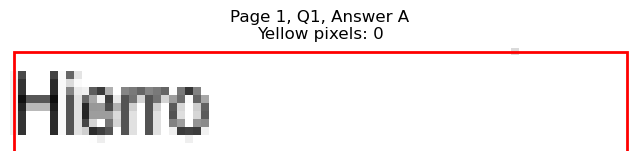

Page 1, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=109.9, y1=152.6
Page 1, Q1, B: Yellow pixels: 92
Page 1, Q1, B: Total non-white pixels: 324
Page 1, Q1, B: Yellow percentage: 28.4%


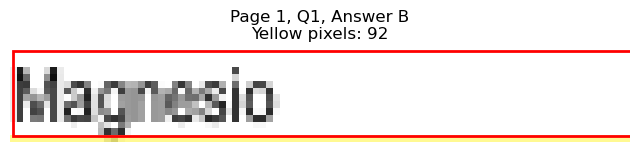

Page 1, Q1 - C: Detected box: x0=68.8, y0=152.5, x1=88.3, y1=165.2
Page 1, Q1, C: Yellow pixels: 855
Page 1, Q1, C: Total non-white pixels: 994
Page 1, Q1, C: Yellow percentage: 86.0%


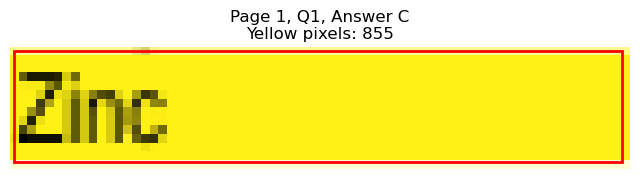

Page 1, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=355.1, y1=139.9
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 131
Page 1, Q1, D: Yellow percentage: 0.0%


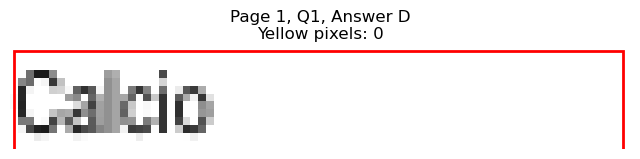

Page 1, Q1 - E: Detected box: x0=327.0, y0=139.9, x1=354.2, y1=152.6
Page 1, Q1, E: Yellow pixels: 0
Page 1, Q1, E: Total non-white pixels: 125
Page 1, Q1, E: Yellow percentage: 0.0%


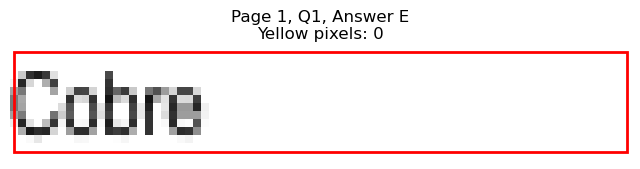


Page 1, Q1 - Selected Answer: C (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=215.7, x1=132.0, y1=228.3
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 343
Page 1, Q2, A: Yellow percentage: 0.0%


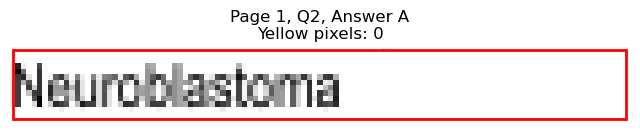

Page 1, Q2 - B: Detected box: x0=68.3, y0=228.3, x1=151.1, y1=240.9
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 396
Page 1, Q2, B: Yellow percentage: 0.0%


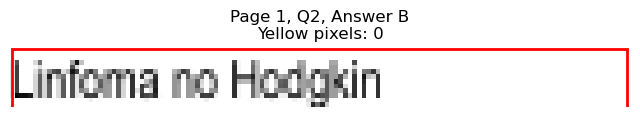

Page 1, Q2 - C: Detected box: x0=68.8, y0=240.9, x1=147.0, y1=253.5
Page 1, Q2, C: Yellow pixels: 0
Page 1, Q2, C: Total non-white pixels: 404
Page 1, Q2, C: Yellow percentage: 0.0%


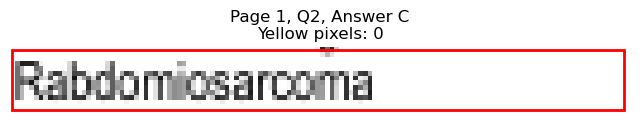

Page 1, Q2 - D: Detected box: x0=327.5, y0=215.7, x1=395.7, y1=228.3
Page 1, Q2, D: Yellow pixels: 119
Page 1, Q2, D: Total non-white pixels: 484
Page 1, Q2, D: Yellow percentage: 24.6%


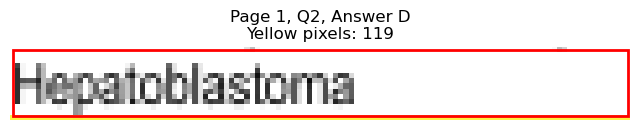

Page 1, Q2 - E: Detected box: x0=327.0, y0=228.3, x1=395.2, y1=240.9
Page 1, Q2, E: Yellow pixels: 1311
Page 1, Q2, E: Total non-white pixels: 1547
Page 1, Q2, E: Yellow percentage: 84.7%


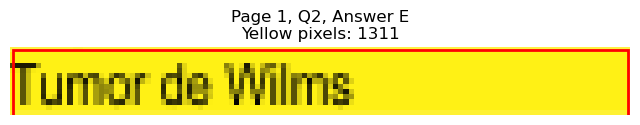


Page 1, Q2 - Selected Answer: E (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=304.0, x1=118.5, y1=316.7
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 361
Page 1, Q3, A: Yellow percentage: 0.0%


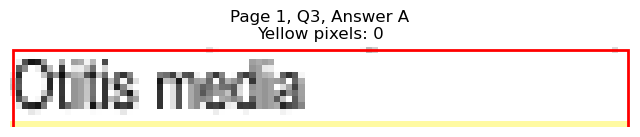

Page 1, Q3 - B: Detected box: x0=68.3, y0=316.6, x1=139.6, y1=329.3
Page 1, Q3, B: Yellow pixels: 1172
Page 1, Q3, B: Total non-white pixels: 1708
Page 1, Q3, B: Yellow percentage: 68.6%


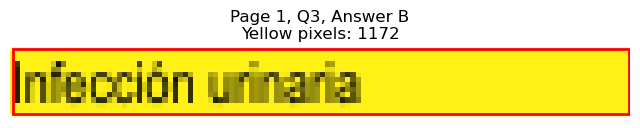

Page 1, Q3 - C: Detected box: x0=68.8, y0=329.2, x1=115.0, y1=341.9
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 349
Page 1, Q3, C: Yellow percentage: 0.0%


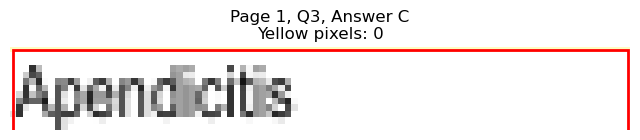

Page 1, Q3 - D: Detected box: x0=327.5, y0=304.0, x1=371.7, y1=316.7
Page 1, Q3, D: Yellow pixels: 0
Page 1, Q3, D: Total non-white pixels: 221
Page 1, Q3, D: Yellow percentage: 0.0%


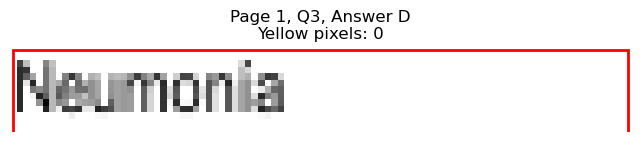

Page 1, Q3 - E: Detected box: x0=327.0, y0=316.6, x1=368.7, y1=329.3
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 218
Page 1, Q3, E: Yellow percentage: 0.0%


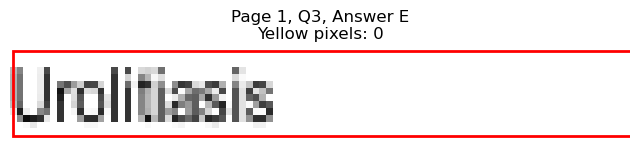


Page 1, Q3 - Selected Answer: B (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=180.1, y1=379.8
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 555
Page 1, Q4, A: Yellow percentage: 0.0%


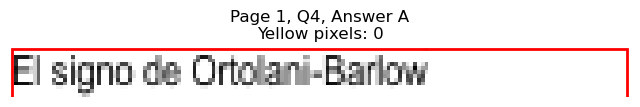

Page 1, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=183.1, y1=392.4
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 574
Page 1, Q4, B: Yellow percentage: 0.0%


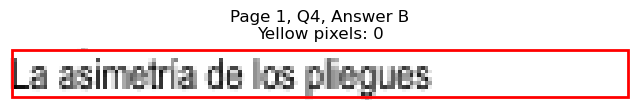

Page 1, Q4 - C: Detected box: x0=68.8, y0=392.3, x1=144.5, y1=405.0
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 394
Page 1, Q4, C: Yellow percentage: 0.0%


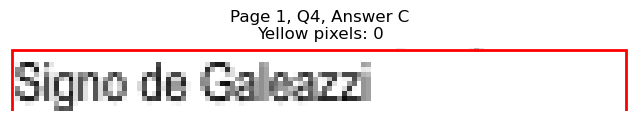

Page 1, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=469.4, y1=379.8
Page 1, Q4, D: Yellow pixels: 2
Page 1, Q4, D: Total non-white pixels: 903
Page 1, Q4, D: Yellow percentage: 0.2%


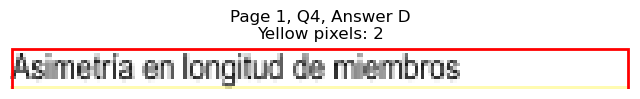

Page 1, Q4 - E: Detected box: x0=327.0, y0=379.7, x1=423.9, y1=392.4
Page 1, Q4, E: Yellow pixels: 1383
Page 1, Q4, E: Total non-white pixels: 2058
Page 1, Q4, E: Yellow percentage: 67.2%


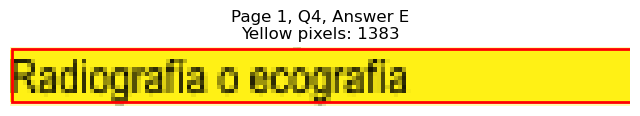


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=468.1, x1=147.5, y1=480.7
Page 1, Q5, A: Yellow pixels: 1361
Page 1, Q5, A: Total non-white pixels: 1690
Page 1, Q5, A: Yellow percentage: 80.5%


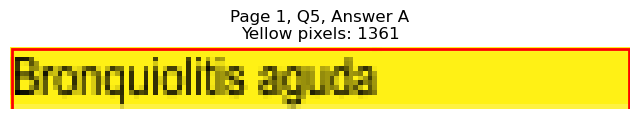

Page 1, Q5 - B: Detected box: x0=68.3, y0=480.8, x1=137.5, y1=493.4
Page 1, Q5, B: Yellow pixels: 119
Page 1, Q5, B: Total non-white pixels: 477
Page 1, Q5, B: Yellow percentage: 24.9%


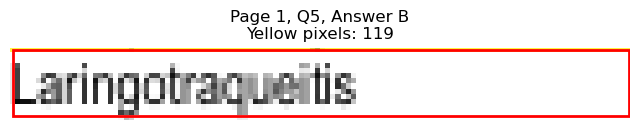

Page 1, Q5 - C: Detected box: x0=68.8, y0=493.4, x1=111.4, y1=506.0
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 201
Page 1, Q5, C: Yellow percentage: 0.0%


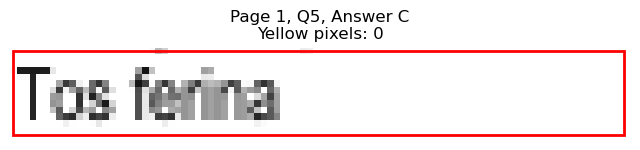

Page 1, Q5 - D: Detected box: x0=327.5, y0=468.1, x1=424.4, y1=480.7
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 532
Page 1, Q5, D: Yellow percentage: 0.0%


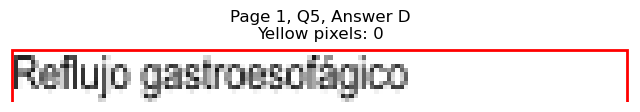

Page 1, Q5 - E: Detected box: x0=327.0, y0=480.8, x1=416.3, y1=493.4
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 464
Page 1, Q5, E: Yellow percentage: 0.0%


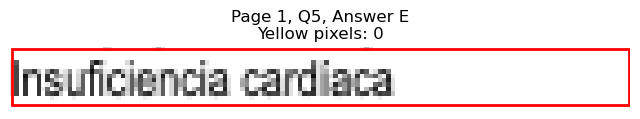


Page 1, Q5 - Selected Answer: A (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=531.2, x1=158.1, y1=543.8
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 438
Page 1, Q6, A: Yellow percentage: 0.0%


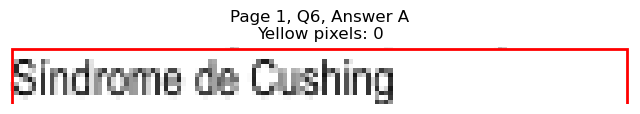

Page 1, Q6 - B: Detected box: x0=68.3, y0=543.8, x1=205.7, y1=556.4
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 693
Page 1, Q6, B: Yellow percentage: 0.0%


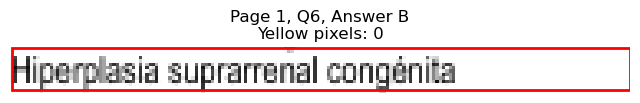

Page 1, Q6 - C: Detected box: x0=68.8, y0=556.5, x1=143.1, y1=569.2
Page 1, Q6, C: Yellow pixels: 1315
Page 1, Q6, C: Total non-white pixels: 1764
Page 1, Q6, C: Yellow percentage: 74.5%


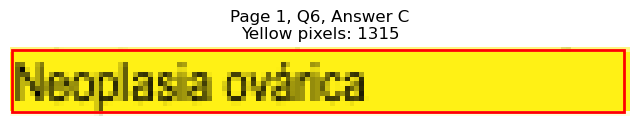

Page 1, Q6 - D: Detected box: x0=327.5, y0=531.2, x1=415.3, y1=543.8
Page 1, Q6, D: Yellow pixels: 0
Page 1, Q6, D: Total non-white pixels: 480
Page 1, Q6, D: Yellow percentage: 0.0%


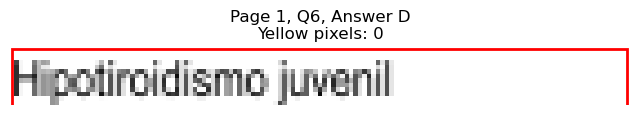

Page 1, Q6 - E: Detected box: x0=327.0, y0=543.8, x1=420.8, y1=556.4
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 451
Page 1, Q6, E: Yellow percentage: 0.0%


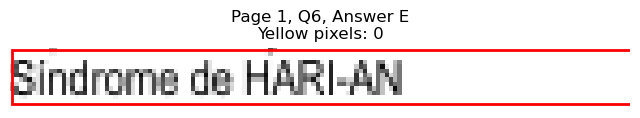


Page 1, Q6 - Selected Answer: C (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=606.9, x1=177.1, y1=619.6
Page 1, Q7, A: Yellow pixels: 1665
Page 1, Q7, A: Total non-white pixels: 2240
Page 1, Q7, A: Yellow percentage: 74.3%


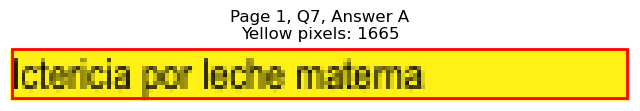

Page 1, Q7 - B: Detected box: x0=68.3, y0=619.6, x1=185.7, y1=632.3
Page 1, Q7, B: Yellow pixels: 168
Page 1, Q7, B: Total non-white pixels: 817
Page 1, Q7, B: Yellow percentage: 20.6%


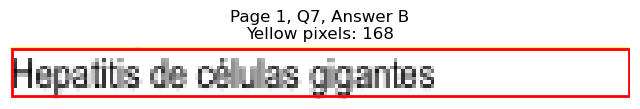

Page 1, Q7 - C: Detected box: x0=68.8, y0=632.2, x1=136.0, y1=644.9
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 350
Page 1, Q7, C: Yellow percentage: 0.0%


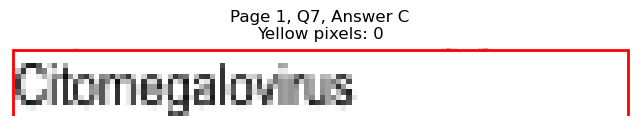

Page 1, Q7 - D: Detected box: x0=327.5, y0=606.9, x1=407.3, y1=619.6
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 413
Page 1, Q7, D: Yellow percentage: 0.0%


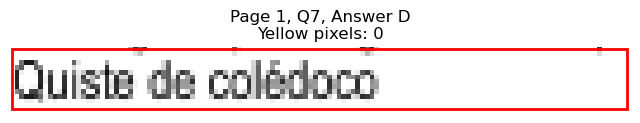

Page 1, Q7 - E: Detected box: x0=327.0, y0=619.6, x1=394.7, y1=632.3
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 327
Page 1, Q7, E: Yellow percentage: 0.0%


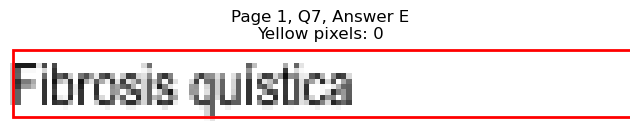


Page 1, Q7 - Selected Answer: A (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=695.4, x1=155.5, y1=708.0
Page 1, Q8, A: Yellow pixels: 1416
Page 1, Q8, A: Total non-white pixels: 1796
Page 1, Q8, A: Yellow percentage: 78.8%


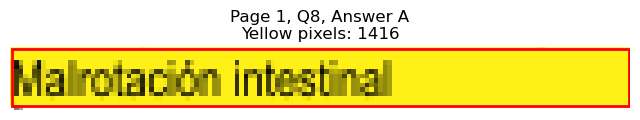

Page 1, Q8 - B: Detected box: x0=68.3, y0=708.0, x1=124.0, y1=720.6
Page 1, Q8, B: Yellow pixels: 106
Page 1, Q8, B: Total non-white pixels: 355
Page 1, Q8, B: Yellow percentage: 29.9%


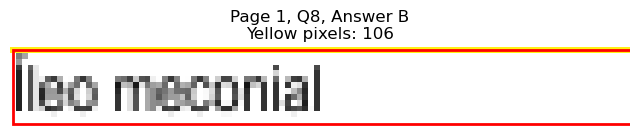

Page 1, Q8 - C: Detected box: x0=68.8, y0=720.6, x1=172.1, y1=733.2
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 541
Page 1, Q8, C: Yellow percentage: 0.0%


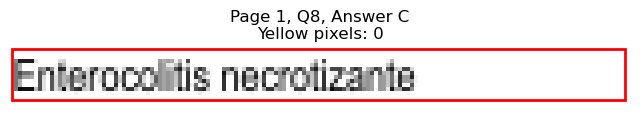

Page 1, Q8 - D: Detected box: x0=327.5, y0=695.4, x1=440.3, y1=708.0
Page 1, Q8, D: Yellow pixels: 0
Page 1, Q8, D: Total non-white pixels: 575
Page 1, Q8, D: Yellow percentage: 0.0%


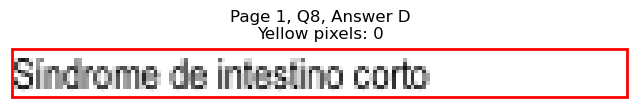

Page 1, Q8 - E: Detected box: x0=327.0, y0=708.0, x1=405.4, y1=720.6
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 404
Page 1, Q8, E: Yellow percentage: 0.0%


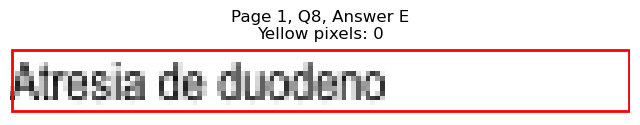


Page 1, Q8 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 8 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=160.1, y1=102.1
Page 2, Q1, A: Yellow pixels: 1537
Page 2, Q1, A: Total non-white pixels: 2002
Page 2, Q1, A: Yellow percentage: 76.8%


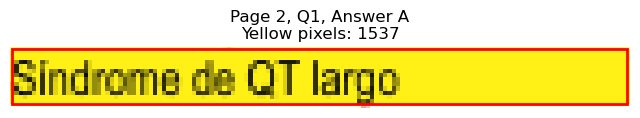

Page 2, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=188.2, y1=114.7
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 787
Page 2, Q1, B: Yellow percentage: 0.0%


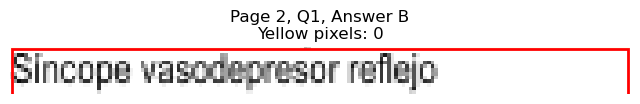

Page 2, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=181.6, y1=127.3
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 552
Page 2, Q1, C: Yellow percentage: 0.0%


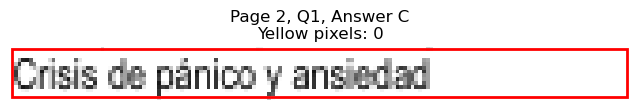

Page 2, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=425.8, y1=102.1
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 523
Page 2, Q1, D: Yellow percentage: 0.0%


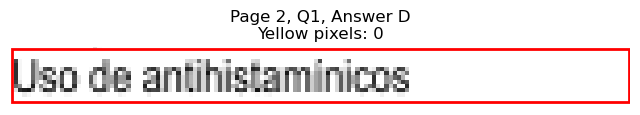

Page 2, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=383.7, y1=114.7
Page 2, Q1, E: Yellow pixels: 0
Page 2, Q1, E: Total non-white pixels: 280
Page 2, Q1, E: Yellow percentage: 0.0%


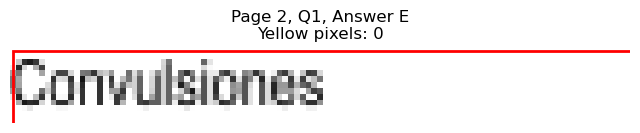


Page 2, Q1 - Selected Answer: A (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=156.6, y1=177.8
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 458
Page 2, Q2, A: Yellow percentage: 0.0%


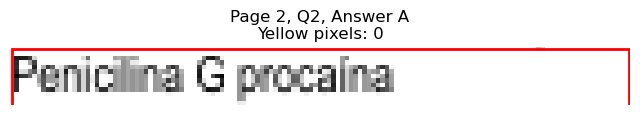

Page 2, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=111.4, y1=190.4
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 241
Page 2, Q2, B: Yellow percentage: 0.0%


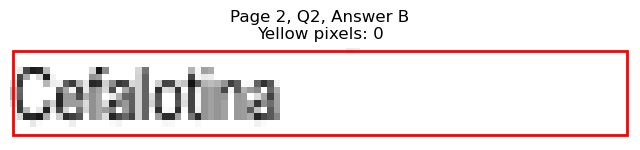

Page 2, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=168.1, y1=203.0
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 475
Page 2, Q2, C: Yellow percentage: 0.0%


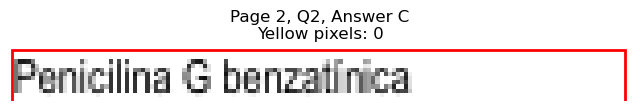

Page 2, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=447.9, y1=177.8
Page 2, Q2, D: Yellow pixels: 1754
Page 2, Q2, D: Total non-white pixels: 2223
Page 2, Q2, D: Yellow percentage: 78.9%


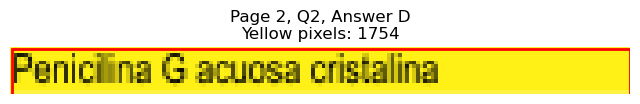

Page 2, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=375.7, y1=190.4
Page 2, Q2, E: Yellow pixels: 99
Page 2, Q2, E: Total non-white pixels: 339
Page 2, Q2, E: Yellow percentage: 29.2%


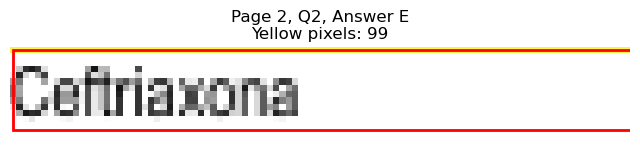


Page 2, Q2 - Selected Answer: D (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=56.6, y0=240.9, x1=65.2, y1=253.5
Page 2, Q3, A: Yellow pixels: 725
Page 2, Q3, A: Total non-white pixels: 840
Page 2, Q3, A: Yellow percentage: 86.3%


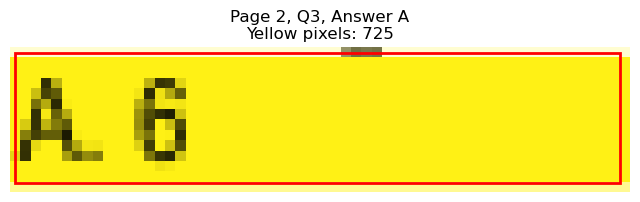

Page 2, Q3 - B: Detected box: x0=56.6, y0=253.5, x1=65.2, y1=266.1
Page 2, Q3, B: Yellow pixels: 60
Page 2, Q3, B: Total non-white pixels: 133
Page 2, Q3, B: Yellow percentage: 45.1%


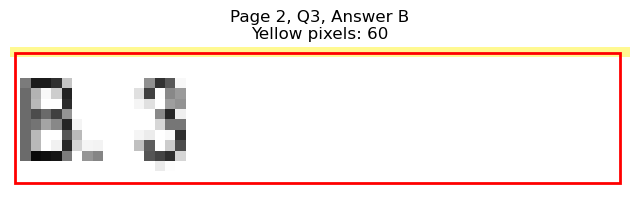

Page 2, Q3 - C: Detected box: x0=56.6, y0=266.1, x1=65.6, y1=278.7
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 63
Page 2, Q3, C: Yellow percentage: 0.0%


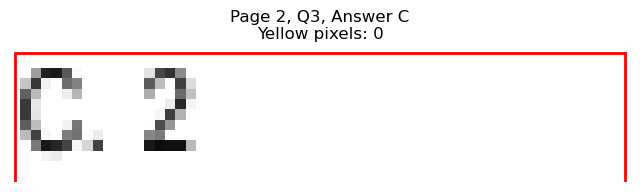

Page 2, Q3 - D: Detected box: x0=315.4, y0=240.9, x1=324.4, y1=253.5
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 73
Page 2, Q3, D: Yellow percentage: 0.0%


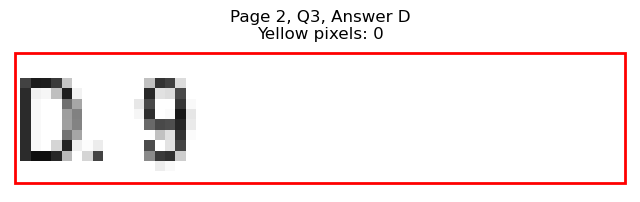

Page 2, Q3 - E: Detected box: x0=315.4, y0=253.5, x1=323.9, y1=266.1
Page 2, Q3, E: Yellow pixels: 0
Page 2, Q3, E: Total non-white pixels: 63
Page 2, Q3, E: Yellow percentage: 0.0%


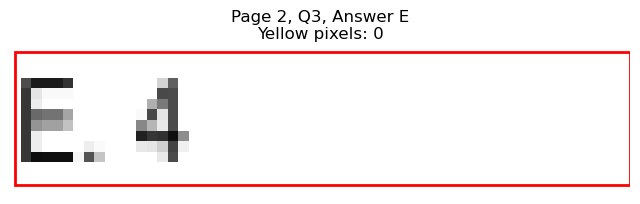


Page 2, Q3 - Selected Answer: A (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=347.3, y1=329.3
Page 2, Q4, A: Yellow pixels: 2898
Page 2, Q4, A: Total non-white pixels: 4620
Page 2, Q4, A: Yellow percentage: 62.7%


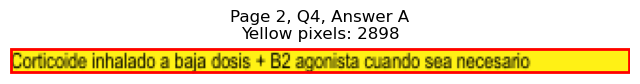

Page 2, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=355.0, y1=341.9
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 1684
Page 2, Q4, B: Yellow percentage: 0.0%


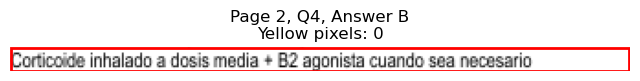

Page 2, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=268.1, y1=354.6
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 988
Page 2, Q4, C: Yellow percentage: 0.0%


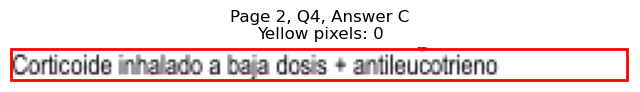

Page 2, Q4 - D: Detected box: x0=68.8, y0=354.5, x1=275.7, y1=367.2
Page 2, Q4, D: Yellow pixels: 0
Page 2, Q4, D: Total non-white pixels: 1031
Page 2, Q4, D: Yellow percentage: 0.0%


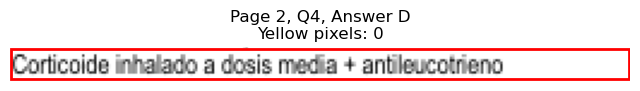

Page 2, Q4 - E: Detected box: x0=68.3, y0=367.1, x1=242.6, y1=379.8
Page 2, Q4, E: Yellow pixels: 0
Page 2, Q4, E: Total non-white pixels: 851
Page 2, Q4, E: Yellow percentage: 0.0%


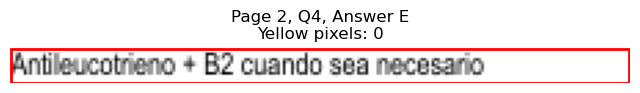


Page 2, Q4 - Selected Answer: A (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=56.6, y0=442.8, x1=65.2, y1=455.5
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 69
Page 2, Q5, A: Yellow percentage: 0.0%


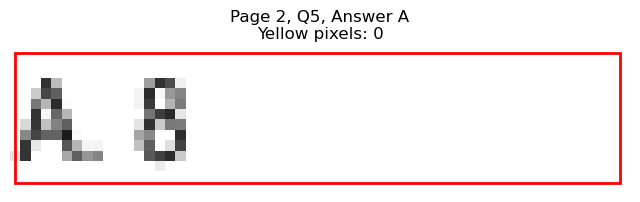

Page 2, Q5 - B: Detected box: x0=68.3, y0=455.5, x1=80.9, y1=468.1
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 42
Page 2, Q5, B: Yellow percentage: 0.0%


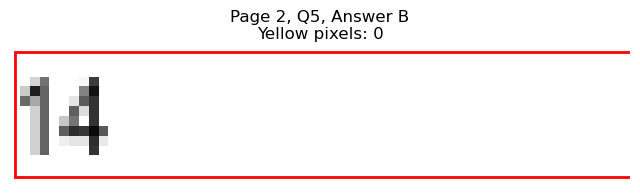

Page 2, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=81.4, y1=480.7
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 52
Page 2, Q5, C: Yellow percentage: 0.0%


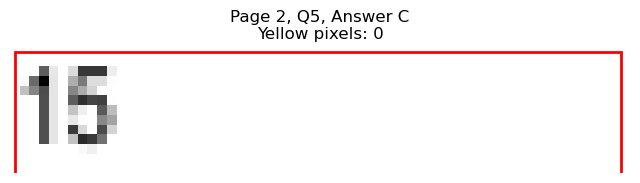

Page 2, Q5 - D: Detected box: x0=327.5, y0=442.8, x1=340.1, y1=455.5
Page 2, Q5, D: Yellow pixels: 810
Page 2, Q5, D: Total non-white pixels: 896
Page 2, Q5, D: Yellow percentage: 90.4%


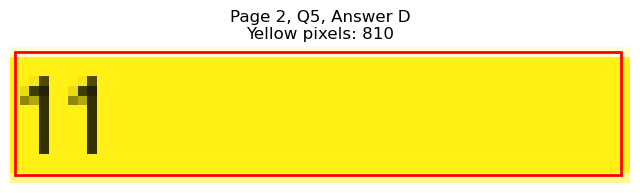

Page 2, Q5 - E: Detected box: x0=315.4, y0=455.5, x1=323.9, y1=468.1
Page 2, Q5, E: Yellow pixels: 0
Page 2, Q5, E: Total non-white pixels: 70
Page 2, Q5, E: Yellow percentage: 0.0%


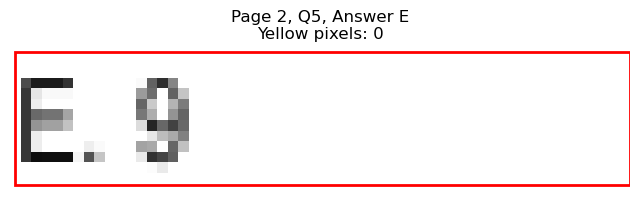


Page 2, Q5 - Selected Answer: D (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=543.8, x1=152.5, y1=556.4
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 419
Page 2, Q6, A: Yellow percentage: 0.0%


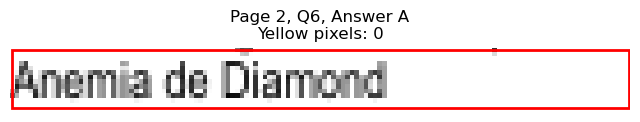

Page 2, Q6 - B: Detected box: x0=68.3, y0=556.5, x1=176.7, y1=569.2
Page 2, Q6, B: Yellow pixels: 0
Page 2, Q6, B: Total non-white pixels: 536
Page 2, Q6, B: Yellow percentage: 0.0%


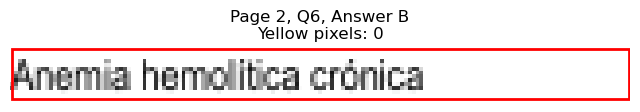

Page 2, Q6 - C: Detected box: x0=68.8, y0=569.1, x1=159.5, y1=581.8
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 446
Page 2, Q6, C: Yellow percentage: 0.0%


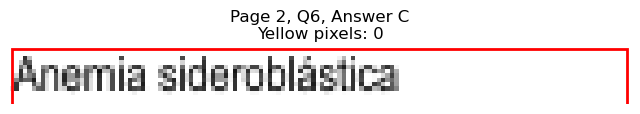

Page 2, Q6 - D: Detected box: x0=327.5, y0=543.8, x1=418.9, y1=556.4
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 477
Page 2, Q6, D: Yellow percentage: 0.0%


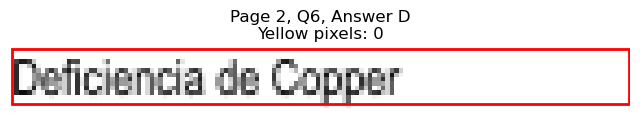

Page 2, Q6 - E: Detected box: x0=327.0, y0=556.5, x1=422.8, y1=569.2
Page 2, Q6, E: Yellow pixels: 1516
Page 2, Q6, E: Total non-white pixels: 2044
Page 2, Q6, E: Yellow percentage: 74.2%


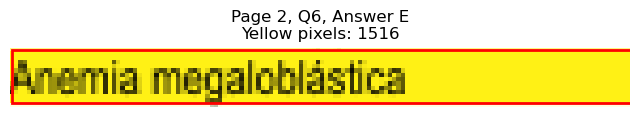


Page 2, Q6 - Selected Answer: E (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=606.9, x1=100.9, y1=619.6
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 144
Page 2, Q7, A: Yellow percentage: 0.0%


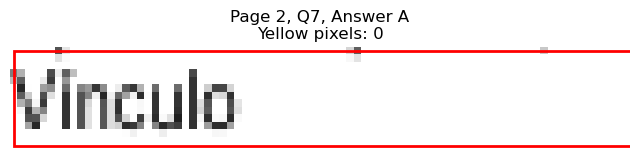

Page 2, Q7 - B: Detected box: x0=68.3, y0=619.6, x1=96.9, y1=632.3
Page 2, Q7, B: Yellow pixels: 829
Page 2, Q7, B: Total non-white pixels: 1106
Page 2, Q7, B: Yellow percentage: 75.0%


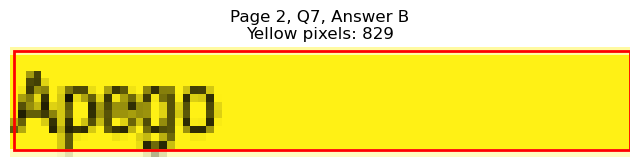

Page 2, Q7 - C: Detected box: x0=68.8, y0=632.2, x1=106.5, y1=644.9
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 292
Page 2, Q7, C: Yellow percentage: 0.0%


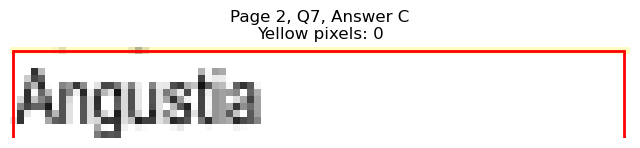

Page 2, Q7 - D: Detected box: x0=327.5, y0=606.9, x1=357.7, y1=619.6
Page 2, Q7, D: Yellow pixels: 0
Page 2, Q7, D: Total non-white pixels: 146
Page 2, Q7, D: Yellow percentage: 0.0%


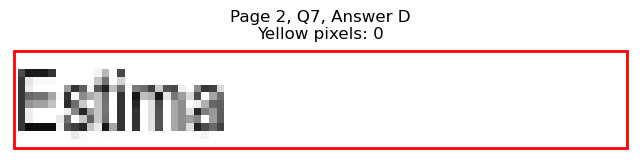

Page 2, Q7 - E: Detected box: x0=327.0, y0=619.6, x1=370.1, y1=632.3
Page 2, Q7, E: Yellow pixels: 0
Page 2, Q7, E: Total non-white pixels: 213
Page 2, Q7, E: Yellow percentage: 0.0%


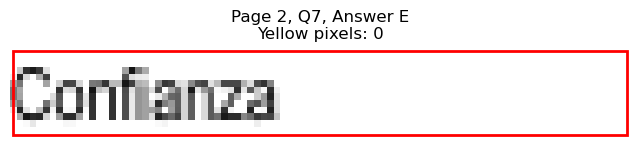


Page 2, Q7 - Selected Answer: B (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=695.4, x1=113.4, y1=708.0
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 234
Page 2, Q8, A: Yellow percentage: 0.0%


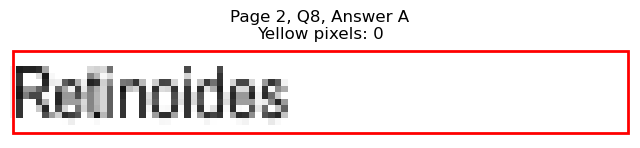

Page 2, Q8 - B: Detected box: x0=68.3, y0=708.0, x1=144.5, y1=720.6
Page 2, Q8, B: Yellow pixels: 0
Page 2, Q8, B: Total non-white pixels: 367
Page 2, Q8, B: Yellow percentage: 0.0%


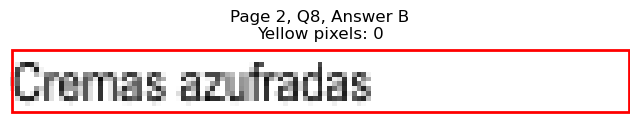

Page 2, Q8 - C: Detected box: x0=68.8, y0=720.6, x1=147.5, y1=733.2
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 408
Page 2, Q8, C: Yellow percentage: 0.0%


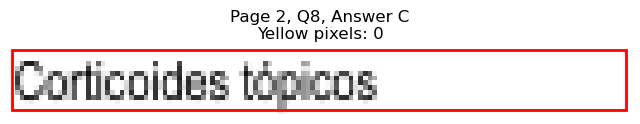

Page 2, Q8 - D: Detected box: x0=327.5, y0=695.4, x1=374.2, y1=708.0
Page 2, Q8, D: Yellow pixels: 1108
Page 2, Q8, D: Total non-white pixels: 1274
Page 2, Q8, D: Yellow percentage: 87.0%


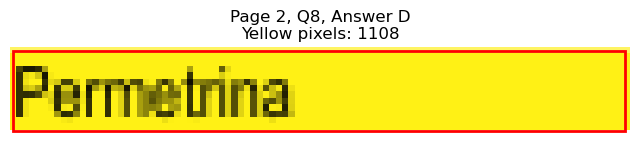

Page 2, Q8 - E: Detected box: x0=327.0, y0=708.0, x1=422.3, y1=720.6
Page 2, Q8, E: Yellow pixels: 146
Page 2, Q8, E: Total non-white pixels: 628
Page 2, Q8, E: Yellow percentage: 23.2%


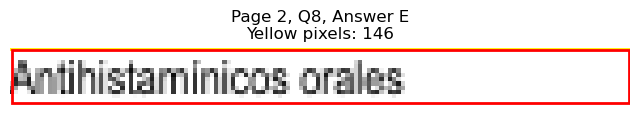


Page 2, Q8 - Selected Answer: D (based on yellow pixel count)





Page 3: Found 7 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=139.9, x1=154.1, y1=152.6
Page 3, Q1, A: Yellow pixels: 137
Page 3, Q1, A: Total non-white pixels: 551
Page 3, Q1, A: Yellow percentage: 24.9%


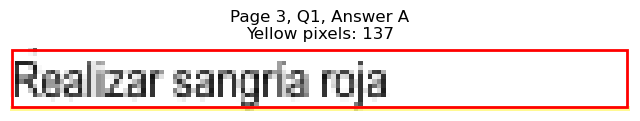

Page 3, Q1 - B: Detected box: x0=68.3, y0=152.5, x1=195.3, y1=165.2
Page 3, Q1, B: Yellow pixels: 1814
Page 3, Q1, B: Total non-white pixels: 2492
Page 3, Q1, B: Yellow percentage: 72.8%


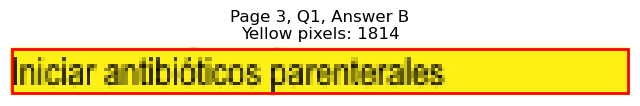

Page 3, Q1 - C: Detected box: x0=68.8, y0=165.1, x1=158.5, y1=177.8
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 581
Page 3, Q1, C: Yellow percentage: 0.0%


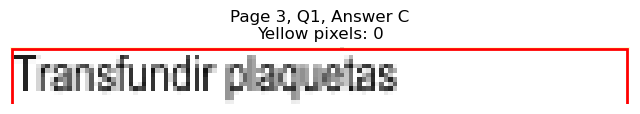

Page 3, Q1 - D: Detected box: x0=327.5, y0=139.9, x1=450.9, y1=152.6
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 628
Page 3, Q1, D: Yellow percentage: 0.0%


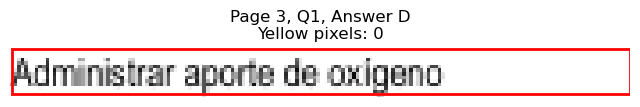

Page 3, Q1 - E: Detected box: x0=327.0, y0=152.5, x1=480.6, y1=165.2
Page 3, Q1, E: Yellow pixels: 0
Page 3, Q1, E: Total non-white pixels: 781
Page 3, Q1, E: Yellow percentage: 0.0%


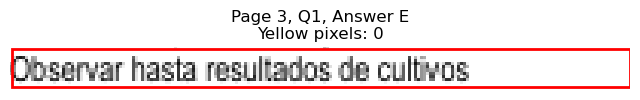


Page 3, Q1 - Selected Answer: B (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=118.9, y1=215.6
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 228
Page 3, Q2, A: Yellow percentage: 0.0%


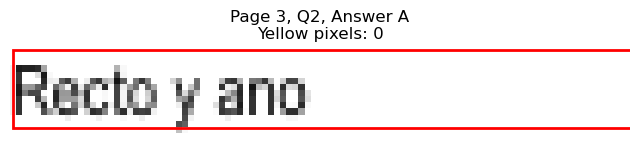

Page 3, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=171.1, y1=228.3
Page 3, Q2, B: Yellow pixels: 1487
Page 3, Q2, B: Total non-white pixels: 2156
Page 3, Q2, B: Yellow percentage: 69.0%


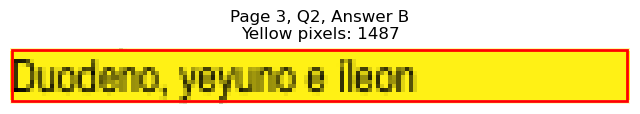

Page 3, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=149.1, y1=240.9
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 548
Page 3, Q2, C: Yellow percentage: 0.0%


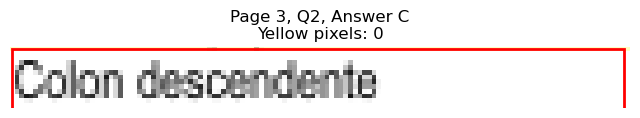

Page 3, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=398.2, y1=215.6
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 355
Page 3, Q2, D: Yellow percentage: 0.0%


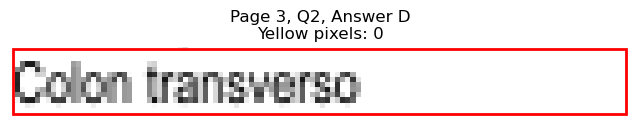

Page 3, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=402.3, y1=228.3
Page 3, Q2, E: Yellow pixels: 0
Page 3, Q2, E: Total non-white pixels: 375
Page 3, Q2, E: Yellow percentage: 0.0%


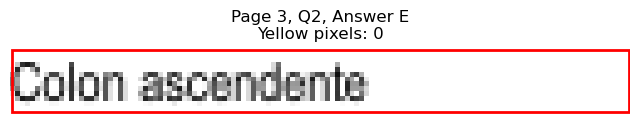


Page 3, Q2 - Selected Answer: B (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=291.4, x1=115.9, y1=304.1
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 252
Page 3, Q3, A: Yellow percentage: 0.0%


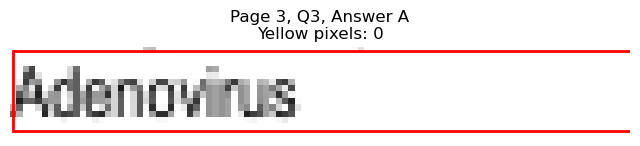

Page 3, Q3 - B: Detected box: x0=68.3, y0=304.0, x1=133.5, y1=316.7
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 320
Page 3, Q3, B: Yellow percentage: 0.0%


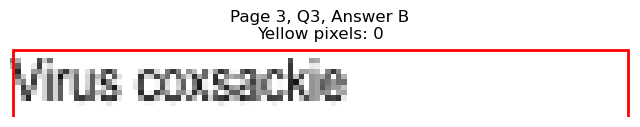

Page 3, Q3 - C: Detected box: x0=68.8, y0=316.6, x1=172.6, y1=329.3
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 514
Page 3, Q3, C: Yellow percentage: 0.0%


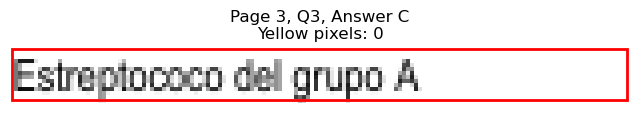

Page 3, Q3 - D: Detected box: x0=327.5, y0=291.4, x1=415.3, y1=304.1
Page 3, Q3, D: Yellow pixels: 139
Page 3, Q3, D: Total non-white pixels: 563
Page 3, Q3, D: Yellow percentage: 24.7%


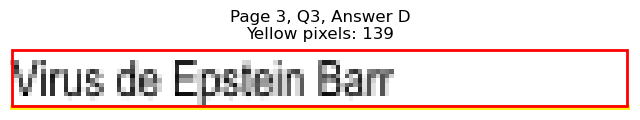

Page 3, Q3 - E: Detected box: x0=327.0, y0=304.0, x1=408.8, y1=316.7
Page 3, Q3, E: Yellow pixels: 1379
Page 3, Q3, E: Total non-white pixels: 1716
Page 3, Q3, E: Yellow percentage: 80.4%


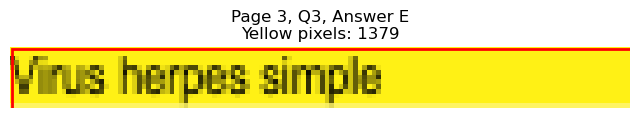


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=379.7, x1=98.9, y1=392.4
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 98
Page 3, Q4, A: Yellow percentage: 0.0%


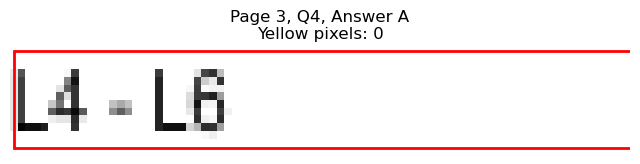

Page 3, Q4 - B: Detected box: x0=68.3, y0=392.3, x1=99.9, y1=405.0
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 105
Page 3, Q4, B: Yellow percentage: 0.0%


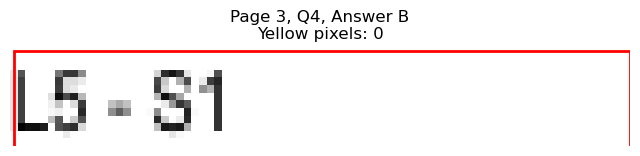

Page 3, Q4 - C: Detected box: x0=68.8, y0=404.9, x1=109.9, y1=417.6
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 175
Page 3, Q4, C: Yellow percentage: 0.0%


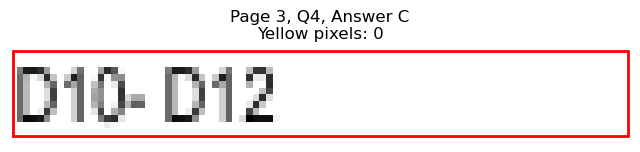

Page 3, Q4 - D: Detected box: x0=327.5, y0=379.7, x1=364.6, y1=392.4
Page 3, Q4, D: Yellow pixels: 88
Page 3, Q4, D: Total non-white pixels: 215
Page 3, Q4, D: Yellow percentage: 40.9%


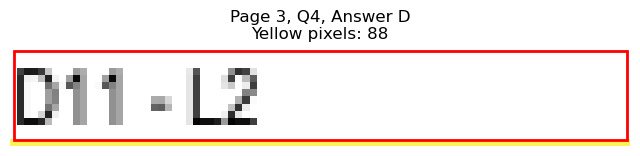

Page 3, Q4 - E: Detected box: x0=327.0, y0=392.3, x1=359.7, y1=405.0
Page 3, Q4, E: Yellow pixels: 979
Page 3, Q4, E: Total non-white pixels: 1079
Page 3, Q4, E: Yellow percentage: 90.7%


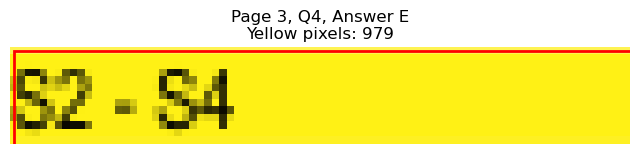


Page 3, Q4 - Selected Answer: E (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=480.8, x1=190.2, y1=493.4
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 619
Page 3, Q5, A: Yellow percentage: 0.0%


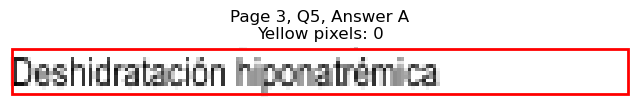

Page 3, Q5 - B: Detected box: x0=68.3, y0=493.4, x1=190.2, y1=506.0
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 674
Page 3, Q5, B: Yellow percentage: 0.0%


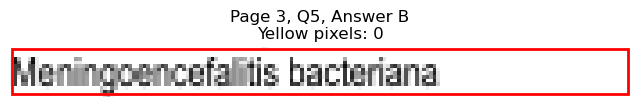

Page 3, Q5 - C: Detected box: x0=68.8, y0=506.0, x1=144.0, y1=518.6
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 373
Page 3, Q5, C: Yellow percentage: 0.0%


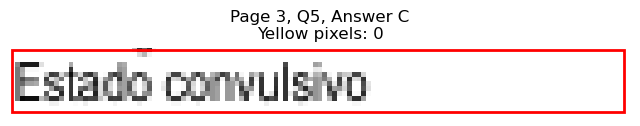

Page 3, Q5 - D: Detected box: x0=327.5, y0=480.8, x1=386.2, y1=493.4
Page 3, Q5, D: Yellow pixels: 110
Page 3, Q5, D: Total non-white pixels: 414
Page 3, Q5, D: Yellow percentage: 26.6%


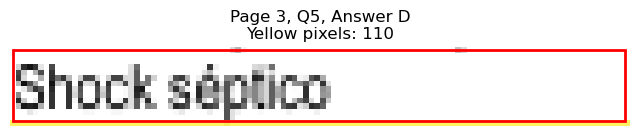

Page 3, Q5 - E: Detected box: x0=327.0, y0=493.4, x1=452.0, y1=506.0
Page 3, Q5, E: Yellow pixels: 1766
Page 3, Q5, E: Total non-white pixels: 2276
Page 3, Q5, E: Yellow percentage: 77.6%


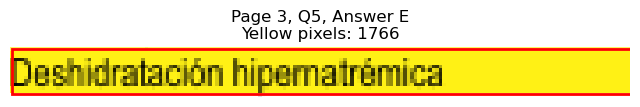


Page 3, Q5 - Selected Answer: E (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=594.3, x1=205.1, y1=607.0
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 646
Page 3, Q6, A: Yellow percentage: 0.0%


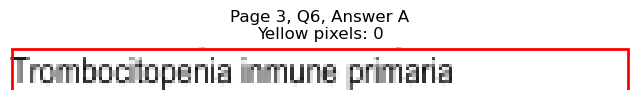

Page 3, Q6 - B: Detected box: x0=68.3, y0=606.9, x1=176.2, y1=619.6
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 544
Page 3, Q6, B: Yellow percentage: 0.0%


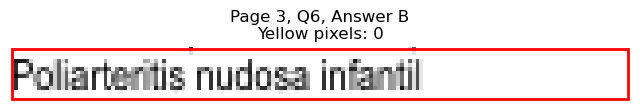

Page 3, Q6 - C: Detected box: x0=68.8, y0=619.6, x1=174.1, y1=632.3
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 547
Page 3, Q6, C: Yellow percentage: 0.0%


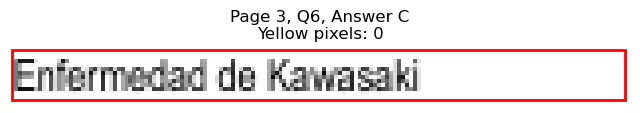

Page 3, Q6 - D: Detected box: x0=327.5, y0=594.3, x1=405.8, y1=607.0
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 514
Page 3, Q6, D: Yellow percentage: 0.0%


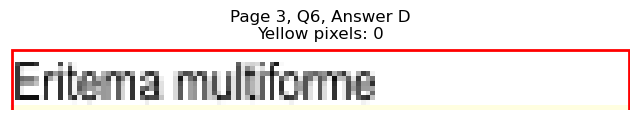

Page 3, Q6 - E: Detected box: x0=327.0, y0=606.9, x1=450.4, y1=619.6
Page 3, Q6, E: Yellow pixels: 1766
Page 3, Q6, E: Total non-white pixels: 2436
Page 3, Q6, E: Yellow percentage: 72.5%


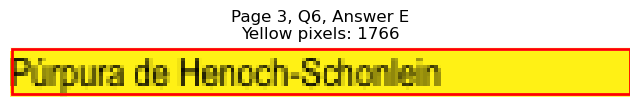


Page 3, Q6 - Selected Answer: E (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=695.4, x1=119.9, y1=708.0
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 264
Page 3, Q7, A: Yellow percentage: 0.0%


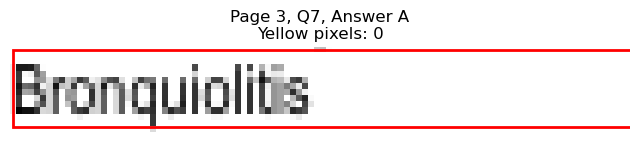

Page 3, Q7 - B: Detected box: x0=68.3, y0=708.0, x1=90.4, y1=720.6
Page 3, Q7, B: Yellow pixels: 73
Page 3, Q7, B: Total non-white pixels: 178
Page 3, Q7, B: Yellow percentage: 41.0%


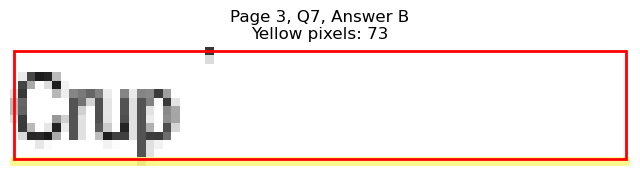

Page 3, Q7 - C: Detected box: x0=68.8, y0=720.6, x1=221.2, y1=733.2
Page 3, Q7, C: Yellow pixels: 2043
Page 3, Q7, C: Total non-white pixels: 2856
Page 3, Q7, C: Yellow percentage: 71.5%


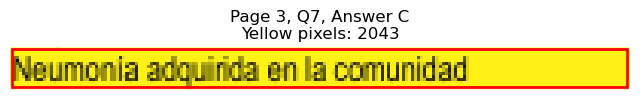

Page 3, Q7 - D: Detected box: x0=327.5, y0=695.4, x1=434.8, y1=708.0
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 584
Page 3, Q7, D: Yellow percentage: 0.0%


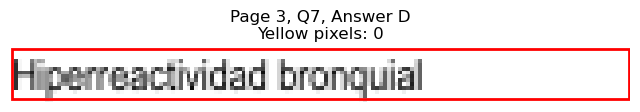

Page 3, Q7 - E: Detected box: x0=327.0, y0=708.0, x1=388.3, y1=720.6
Page 3, Q7, E: Yellow pixels: 0
Page 3, Q7, E: Total non-white pixels: 313
Page 3, Q7, E: Yellow percentage: 0.0%


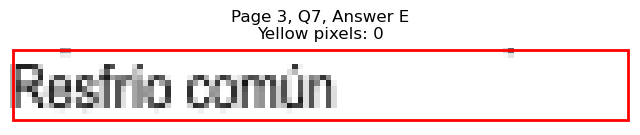


Page 3, Q7 - Selected Answer: C (based on yellow pixel count)





Page 4: Found 7 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=139.9, x1=171.1, y1=152.6
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 502
Page 4, Q1, A: Yellow percentage: 0.0%


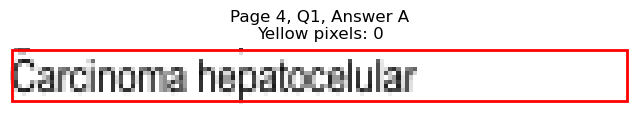

Page 4, Q1 - B: Detected box: x0=68.3, y0=152.5, x1=157.1, y1=165.2
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 402
Page 4, Q1, B: Yellow percentage: 0.0%


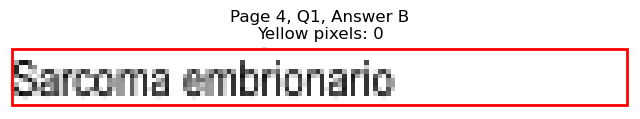

Page 4, Q1 - C: Detected box: x0=68.8, y0=165.1, x1=129.0, y1=177.8
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 304
Page 4, Q1, C: Yellow percentage: 0.0%


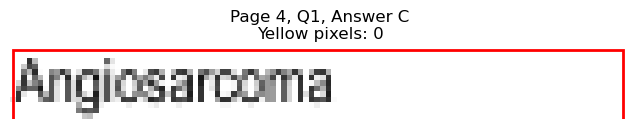

Page 4, Q1 - D: Detected box: x0=327.5, y0=139.9, x1=442.4, y1=152.6
Page 4, Q1, D: Yellow pixels: 166
Page 4, Q1, D: Total non-white pixels: 769
Page 4, Q1, D: Yellow percentage: 21.6%


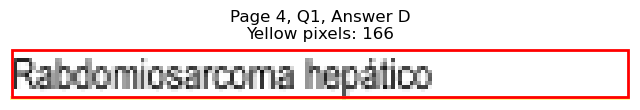

Page 4, Q1 - E: Detected box: x0=327.0, y0=152.5, x1=395.2, y1=165.2
Page 4, Q1, E: Yellow pixels: 1260
Page 4, Q1, E: Total non-white pixels: 1666
Page 4, Q1, E: Yellow percentage: 75.6%


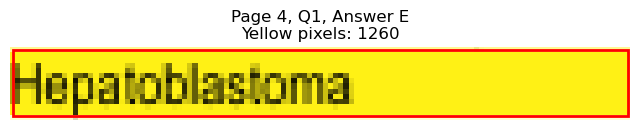


Page 4, Q1 - Selected Answer: E (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=152.7, y1=215.6
Page 4, Q2, A: Yellow pixels: 0
Page 4, Q2, A: Total non-white pixels: 395
Page 4, Q2, A: Yellow percentage: 0.0%


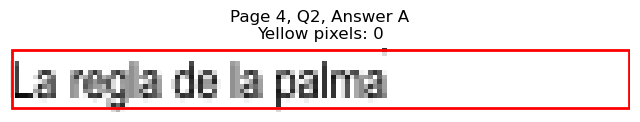

Page 4, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=161.7, y1=228.3
Page 4, Q2, B: Yellow pixels: 1376
Page 4, Q2, B: Total non-white pixels: 2016
Page 4, Q2, B: Yellow percentage: 68.3%


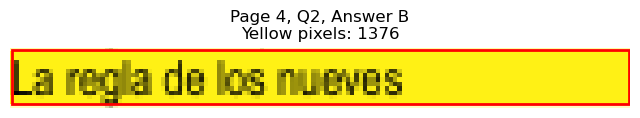

Page 4, Q2 - C: Detected box: x0=171.1, y0=228.3, x1=212.6, y1=240.9
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 542
Page 4, Q2, C: Yellow percentage: 0.0%


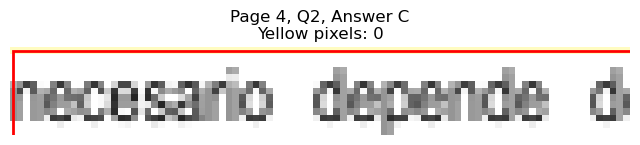

Page 4, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=410.9, y1=215.6
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 438
Page 4, Q2, D: Yellow percentage: 0.0%


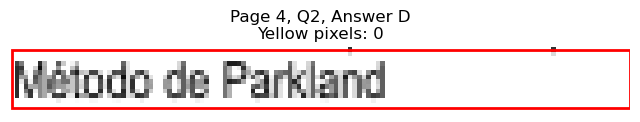

Page 4, Q2 - E: Detected box: x0=471.8, y0=215.7, x1=512.9, y1=228.3
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 300
Page 4, Q2, E: Yellow percentage: 0.0%


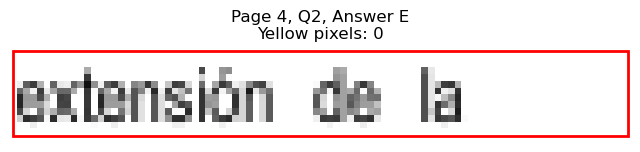


Page 4, Q2 - Selected Answer: B (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=329.2, x1=151.1, y1=341.9
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 439
Page 4, Q3, A: Yellow percentage: 0.0%


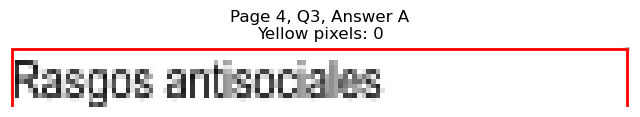

Page 4, Q3 - B: Detected box: x0=68.3, y0=341.9, x1=145.1, y1=354.6
Page 4, Q3, B: Yellow pixels: 0
Page 4, Q3, B: Total non-white pixels: 401
Page 4, Q3, B: Yellow percentage: 0.0%


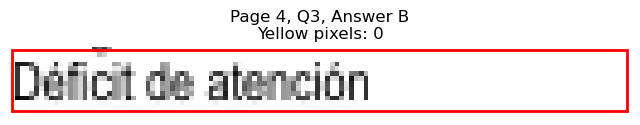

Page 4, Q3 - C: Detected box: x0=68.8, y0=354.5, x1=144.0, y1=367.2
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 393
Page 4, Q3, C: Yellow percentage: 0.0%


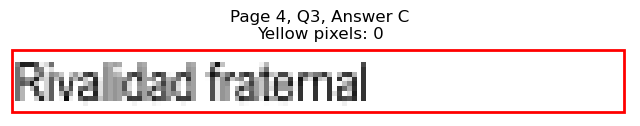

Page 4, Q3 - D: Detected box: x0=327.5, y0=329.2, x1=405.8, y1=341.9
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 449
Page 4, Q3, D: Yellow percentage: 0.0%


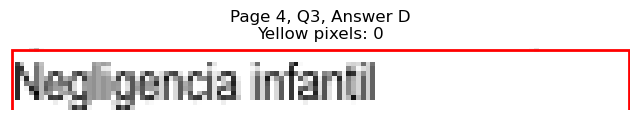

Page 4, Q3 - E: Detected box: x0=327.0, y0=341.9, x1=427.9, y1=354.6
Page 4, Q3, E: Yellow pixels: 1551
Page 4, Q3, E: Total non-white pixels: 2114
Page 4, Q3, E: Yellow percentage: 73.4%


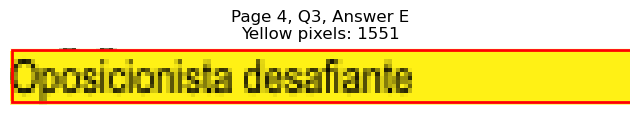


Page 4, Q3 - Selected Answer: E (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=430.2, x1=157.6, y1=442.9
Page 4, Q4, A: Yellow pixels: 0
Page 4, Q4, A: Total non-white pixels: 434
Page 4, Q4, A: Yellow percentage: 0.0%


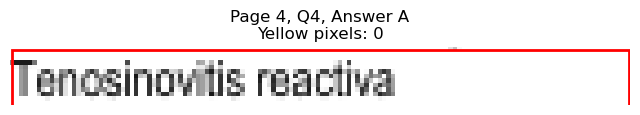

Page 4, Q4 - B: Detected box: x0=68.3, y0=442.8, x1=113.9, y1=455.5
Page 4, Q4, B: Yellow pixels: 0
Page 4, Q4, B: Total non-white pixels: 249
Page 4, Q4, B: Yellow percentage: 0.0%


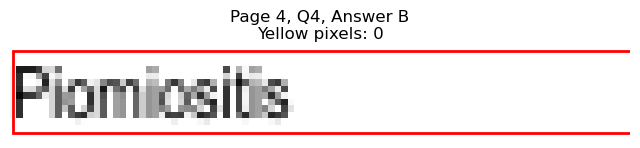

Page 4, Q4 - C: Detected box: x0=68.8, y0=455.5, x1=147.0, y1=468.1
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 393
Page 4, Q4, C: Yellow percentage: 0.0%


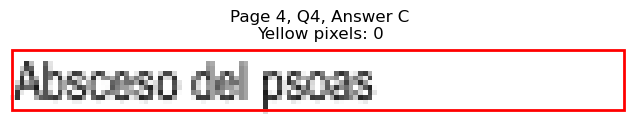

Page 4, Q4 - D: Detected box: x0=327.5, y0=430.2, x1=429.3, y1=442.9
Page 4, Q4, D: Yellow pixels: 1588
Page 4, Q4, D: Total non-white pixels: 1989
Page 4, Q4, D: Yellow percentage: 79.8%


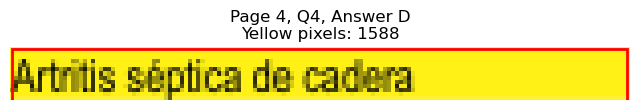

Page 4, Q4 - E: Detected box: x0=327.0, y0=442.8, x1=424.9, y1=455.5
Page 4, Q4, E: Yellow pixels: 147
Page 4, Q4, E: Total non-white pixels: 652
Page 4, Q4, E: Yellow percentage: 22.5%


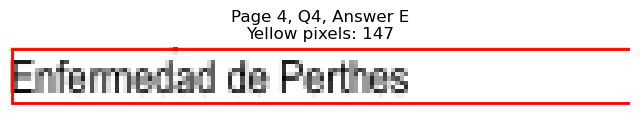


Page 4, Q4 - Selected Answer: D (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=531.2, x1=104.4, y1=543.8
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 287
Page 4, Q5, A: Yellow percentage: 0.0%


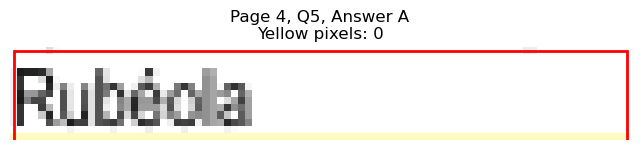

Page 4, Q5 - B: Detected box: x0=68.3, y0=543.8, x1=114.5, y1=556.4
Page 4, Q5, B: Yellow pixels: 1063
Page 4, Q5, B: Total non-white pixels: 1358
Page 4, Q5, B: Yellow percentage: 78.3%


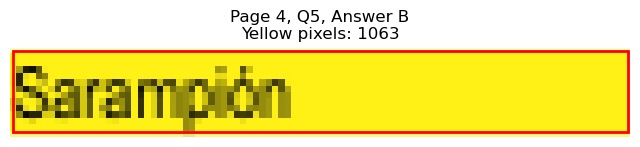

Page 4, Q5 - C: Detected box: x0=68.8, y0=556.5, x1=103.9, y1=569.2
Page 4, Q5, C: Yellow pixels: 86
Page 4, Q5, C: Total non-white pixels: 256
Page 4, Q5, C: Yellow percentage: 33.6%


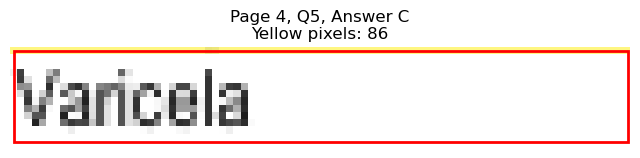

Page 4, Q5 - D: Detected box: x0=327.5, y0=531.2, x1=391.7, y1=543.8
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 346
Page 4, Q5, D: Yellow percentage: 0.0%


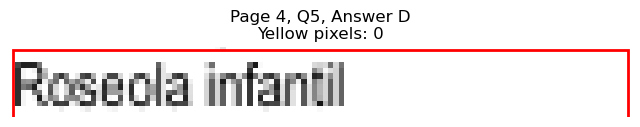

Page 4, Q5 - E: Detected box: x0=327.0, y0=543.8, x1=403.3, y1=556.4
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 396
Page 4, Q5, E: Yellow percentage: 0.0%


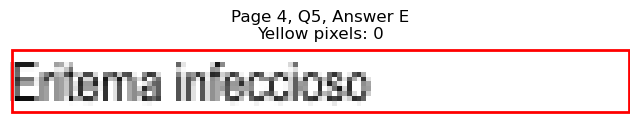


Page 4, Q5 - Selected Answer: B (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=606.9, x1=206.0, y1=619.6
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 671
Page 4, Q6, A: Yellow percentage: 0.0%


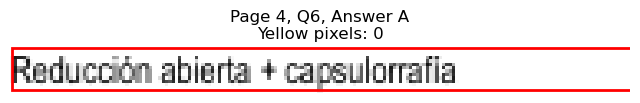

Page 4, Q6 - B: Detected box: x0=68.3, y0=619.6, x1=242.1, y1=632.3
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 869
Page 4, Q6, B: Yellow percentage: 0.0%


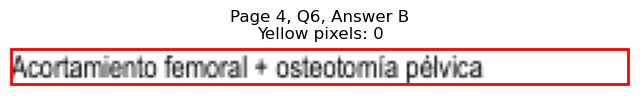

Page 4, Q6 - C: Detected box: x0=68.8, y0=632.2, x1=159.9, y1=644.9
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 435
Page 4, Q6, C: Yellow percentage: 0.0%


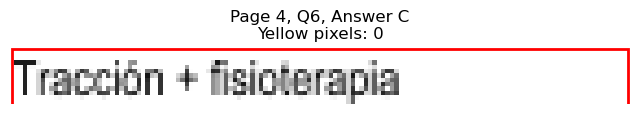

Page 4, Q6 - D: Detected box: x0=327.5, y0=606.9, x1=519.5, y1=619.6
Page 4, Q6, D: Yellow pixels: 2005
Page 4, Q6, D: Total non-white pixels: 2995
Page 4, Q6, D: Yellow percentage: 66.9%


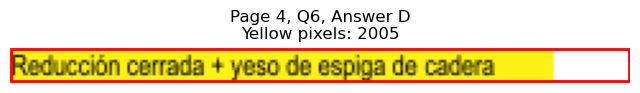

Page 4, Q6 - E: Detected box: x0=327.0, y0=619.6, x1=485.4, y1=632.3
Page 4, Q6, E: Yellow pixels: 207
Page 4, Q6, E: Total non-white pixels: 1054
Page 4, Q6, E: Yellow percentage: 19.6%


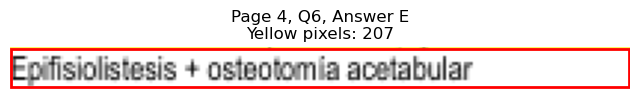


Page 4, Q6 - Selected Answer: D (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=708.0, x1=137.5, y1=720.6
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 369
Page 4, Q7, A: Yellow percentage: 0.0%


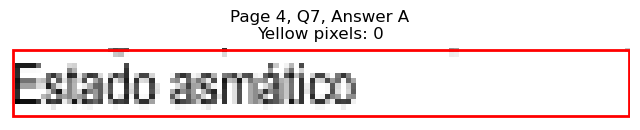

Page 4, Q7 - B: Detected box: x0=68.3, y0=720.6, x1=184.2, y1=733.2
Page 4, Q7, B: Yellow pixels: 167
Page 4, Q7, B: Total non-white pixels: 748
Page 4, Q7, B: Yellow percentage: 22.3%


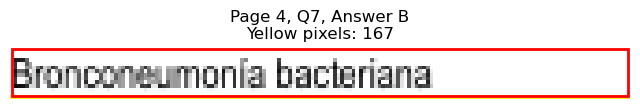

Page 4, Q7 - C: Detected box: x0=68.8, y0=733.2, x1=214.4, y1=745.8
Page 4, Q7, C: Yellow pixels: 1985
Page 4, Q7, C: Total non-white pixels: 2561
Page 4, Q7, C: Yellow percentage: 77.5%


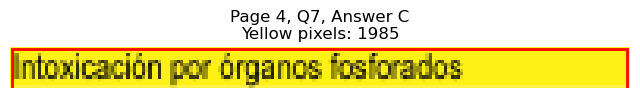

Page 4, Q7 - D: Detected box: x0=327.5, y0=708.0, x1=419.8, y1=720.6
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 479
Page 4, Q7, D: Yellow percentage: 0.0%


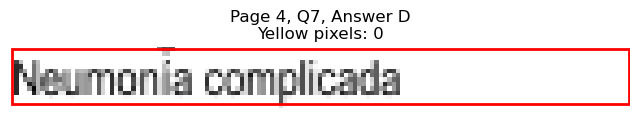

Page 4, Q7 - E: Detected box: x0=327.0, y0=720.6, x1=376.2, y1=733.2
Page 4, Q7, E: Yellow pixels: 0
Page 4, Q7, E: Total non-white pixels: 287
Page 4, Q7, E: Yellow percentage: 0.0%


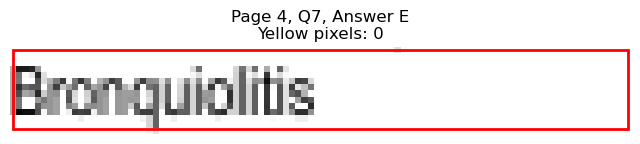


Page 4, Q7 - Selected Answer: C (based on yellow pixel count)





Page 5: Found 7 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=180.6, y1=127.3
Page 5, Q1, A: Yellow pixels: 1530
Page 5, Q1, A: Total non-white pixels: 2282
Page 5, Q1, A: Yellow percentage: 67.0%


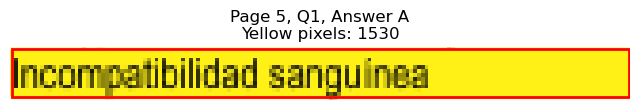

Page 5, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=131.1, y1=139.9
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 402
Page 5, Q1, B: Yellow percentage: 0.0%


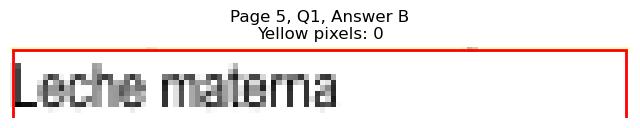

Page 5, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=125.4, y1=152.6
Page 5, Q1, C: Yellow pixels: 0
Page 5, Q1, C: Total non-white pixels: 303
Page 5, Q1, C: Yellow percentage: 0.0%


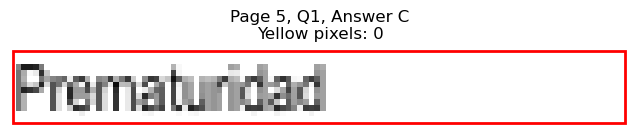

Page 5, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=393.8, y1=127.3
Page 5, Q1, D: Yellow pixels: 0
Page 5, Q1, D: Total non-white pixels: 341
Page 5, Q1, D: Yellow percentage: 0.0%


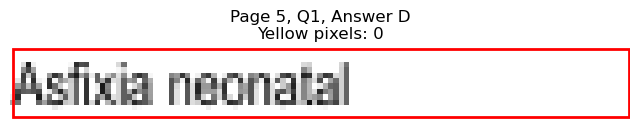

Page 5, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=415.4, y1=139.9
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 461
Page 5, Q1, E: Yellow percentage: 0.0%


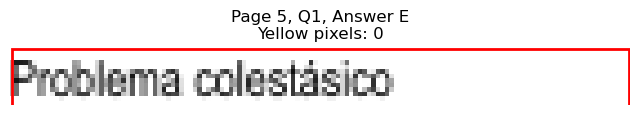


Page 5, Q1 - Selected Answer: A (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=162.1, y1=215.6
Page 5, Q2, A: Yellow pixels: 1511
Page 5, Q2, A: Total non-white pixels: 2030
Page 5, Q2, A: Yellow percentage: 74.4%


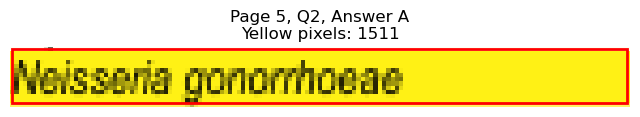

Page 5, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=162.6, y1=228.3
Page 5, Q2, B: Yellow pixels: 144
Page 5, Q2, B: Total non-white pixels: 632
Page 5, Q2, B: Yellow percentage: 22.8%


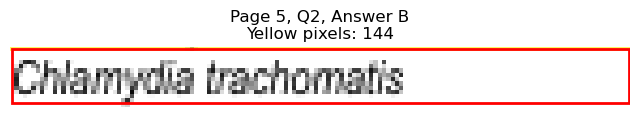

Page 5, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=167.5, y1=240.9
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 501
Page 5, Q2, C: Yellow percentage: 0.0%


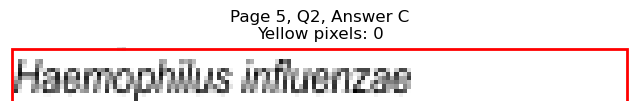

Page 5, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=420.8, y1=215.6
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 467
Page 5, Q2, D: Yellow percentage: 0.0%


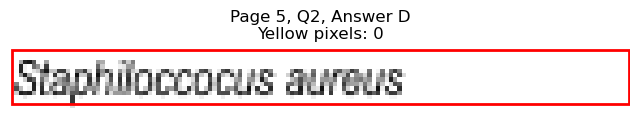

Page 5, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=429.9, y1=228.3
Page 5, Q2, E: Yellow pixels: 0
Page 5, Q2, E: Total non-white pixels: 516
Page 5, Q2, E: Yellow percentage: 0.0%


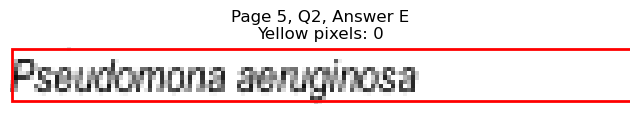


Page 5, Q2 - Selected Answer: A (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=291.4, x1=165.1, y1=304.1
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 480
Page 5, Q3, A: Yellow percentage: 0.0%


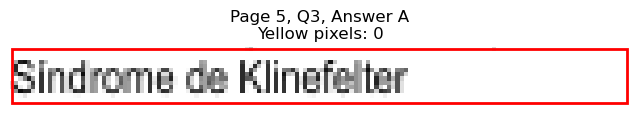

Page 5, Q3 - B: Detected box: x0=68.3, y0=304.0, x1=160.1, y1=316.7
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 453
Page 5, Q3, B: Yellow percentage: 0.0%


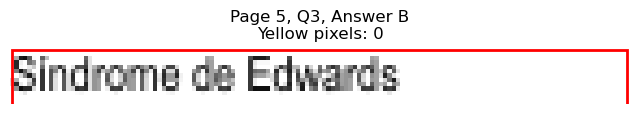

Page 5, Q3 - C: Detected box: x0=68.8, y0=316.6, x1=149.1, y1=329.3
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 400
Page 5, Q3, C: Yellow percentage: 0.0%


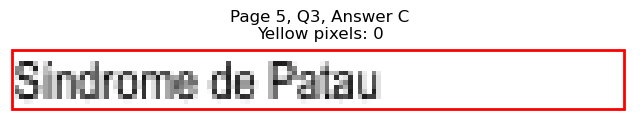

Page 5, Q3 - D: Detected box: x0=327.5, y0=291.4, x1=370.6, y1=304.1
Page 5, Q3, D: Yellow pixels: 94
Page 5, Q3, D: Total non-white pixels: 305
Page 5, Q3, D: Yellow percentage: 30.8%


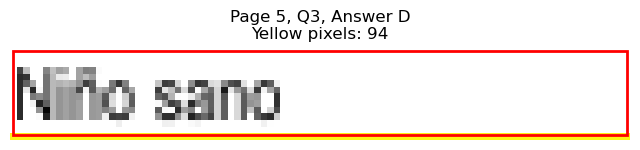

Page 5, Q3 - E: Detected box: x0=327.0, y0=304.0, x1=410.3, y1=316.7
Page 5, Q3, E: Yellow pixels: 1450
Page 5, Q3, E: Total non-white pixels: 1742
Page 5, Q3, E: Yellow percentage: 83.2%


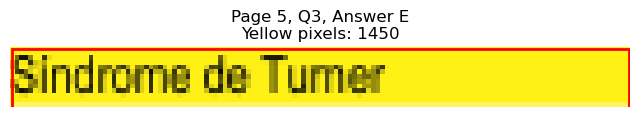


Page 5, Q3 - Selected Answer: E (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=392.3, x1=137.5, y1=405.0
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 481
Page 5, Q4, A: Yellow percentage: 0.0%


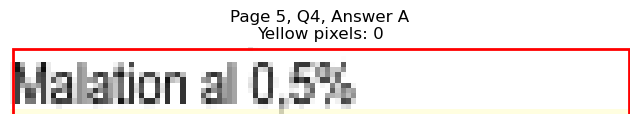

Page 5, Q4 - B: Detected box: x0=68.3, y0=404.9, x1=117.5, y1=417.6
Page 5, Q4, B: Yellow pixels: 1103
Page 5, Q4, B: Total non-white pixels: 1400
Page 5, Q4, B: Yellow percentage: 78.8%


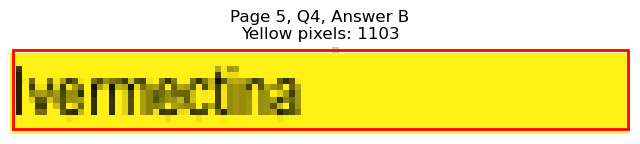

Page 5, Q4 - C: Detected box: x0=68.8, y0=417.6, x1=129.6, y1=430.3
Page 5, Q4, C: Yellow pixels: 112
Page 5, Q4, C: Total non-white pixels: 411
Page 5, Q4, C: Yellow percentage: 27.3%


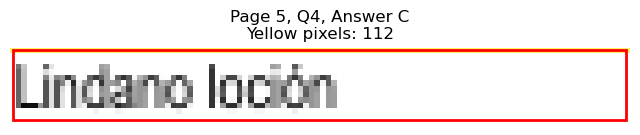

Page 5, Q4 - D: Detected box: x0=327.5, y0=392.3, x1=364.6, y1=405.0
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 194
Page 5, Q4, D: Yellow percentage: 0.0%


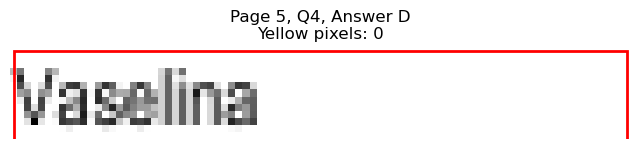

Page 5, Q4 - E: Detected box: x0=327.0, y0=404.9, x1=373.7, y1=417.6
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 233
Page 5, Q4, E: Yellow percentage: 0.0%


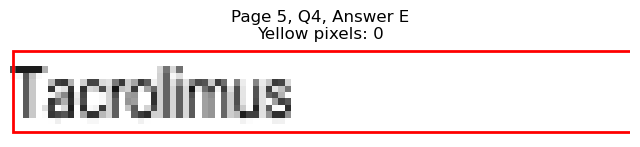


Page 5, Q4 - Selected Answer: B (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=493.4, x1=144.5, y1=506.0
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 380
Page 5, Q5, A: Yellow percentage: 0.0%


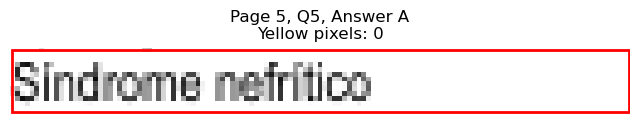

Page 5, Q5 - B: Detected box: x0=68.3, y0=506.0, x1=170.7, y1=518.6
Page 5, Q5, B: Yellow pixels: 0
Page 5, Q5, B: Total non-white pixels: 515
Page 5, Q5, B: Yellow percentage: 0.0%


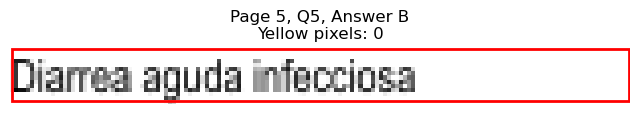

Page 5, Q5 - C: Detected box: x0=68.8, y0=518.6, x1=111.4, y1=531.2
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 221
Page 5, Q5, C: Yellow percentage: 0.0%


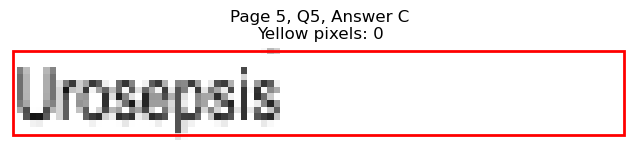

Page 5, Q5 - D: Detected box: x0=327.5, y0=493.4, x1=391.3, y1=506.0
Page 5, Q5, D: Yellow pixels: 115
Page 5, Q5, D: Total non-white pixels: 552
Page 5, Q5, D: Yellow percentage: 20.8%


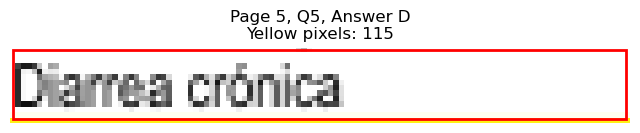

Page 5, Q5 - E: Detected box: x0=327.0, y0=506.0, x1=403.9, y1=518.6
Page 5, Q5, E: Yellow pixels: 1313
Page 5, Q5, E: Total non-white pixels: 1778
Page 5, Q5, E: Yellow percentage: 73.8%


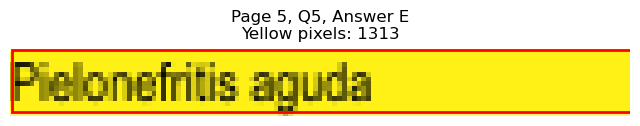


Page 5, Q5 - Selected Answer: E (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=581.7, x1=152.5, y1=594.4
Page 5, Q6, A: Yellow pixels: 135
Page 5, Q6, A: Total non-white pixels: 603
Page 5, Q6, A: Yellow percentage: 22.4%


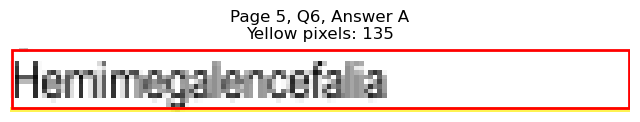

Page 5, Q6 - B: Detected box: x0=68.3, y0=594.3, x1=134.1, y1=607.0
Page 5, Q6, B: Yellow pixels: 1260
Page 5, Q6, B: Total non-white pixels: 1521
Page 5, Q6, B: Yellow percentage: 82.8%


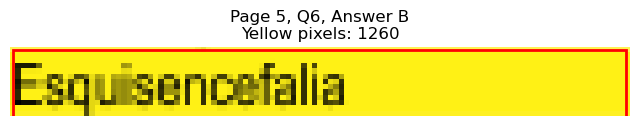

Page 5, Q6 - C: Detected box: x0=68.8, y0=606.9, x1=113.4, y1=619.6
Page 5, Q6, C: Yellow pixels: 95
Page 5, Q6, C: Total non-white pixels: 338
Page 5, Q6, C: Yellow percentage: 28.1%


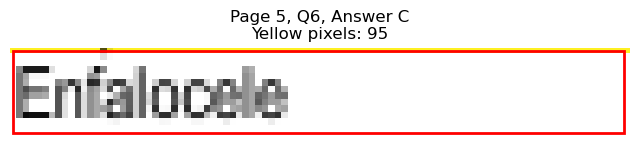

Page 5, Q6 - D: Detected box: x0=327.5, y0=581.7, x1=377.7, y1=594.4
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 258
Page 5, Q6, D: Yellow percentage: 0.0%


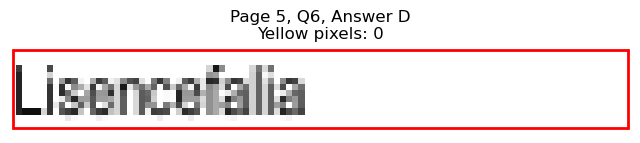

Page 5, Q6 - E: Detected box: x0=327.0, y0=594.3, x1=369.7, y1=607.0
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 243
Page 5, Q6, E: Yellow percentage: 0.0%


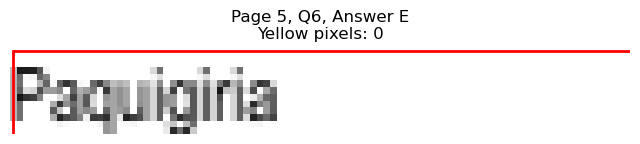


Page 5, Q6 - Selected Answer: B (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=644.9, x1=88.8, y1=657.5
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 104
Page 5, Q7, A: Yellow percentage: 0.0%


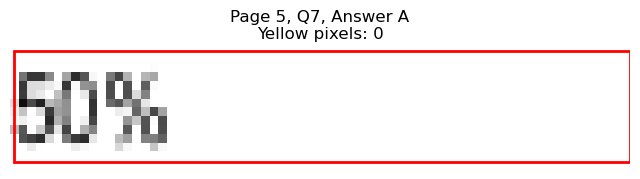

Page 5, Q7 - B: Detected box: x0=68.3, y0=657.5, x1=88.8, y1=670.1
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 84
Page 5, Q7, B: Yellow percentage: 0.0%


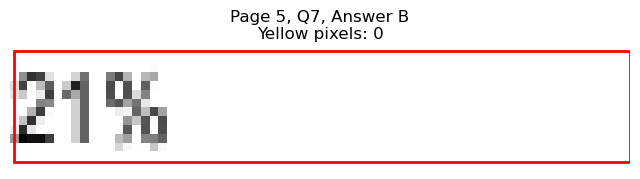

Page 5, Q7 - C: Detected box: x0=68.8, y0=670.1, x1=89.3, y1=682.7
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 104
Page 5, Q7, C: Yellow percentage: 0.0%


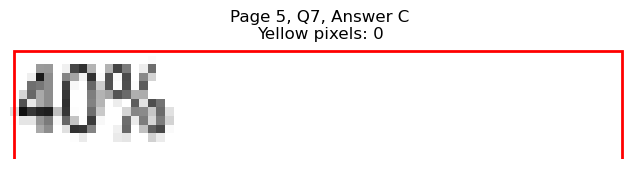

Page 5, Q7 - D: Detected box: x0=327.5, y0=644.9, x1=353.1, y1=657.5
Page 5, Q7, D: Yellow pixels: 917
Page 5, Q7, D: Total non-white pixels: 1078
Page 5, Q7, D: Yellow percentage: 85.1%


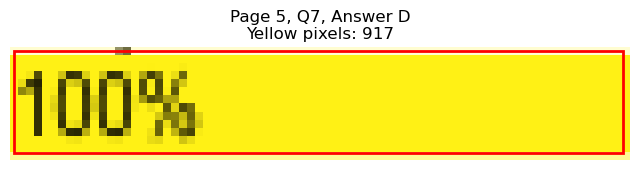

Page 5, Q7 - E: Detected box: x0=327.0, y0=657.5, x1=347.6, y1=670.1
Page 5, Q7, E: Yellow pixels: 71
Page 5, Q7, E: Total non-white pixels: 181
Page 5, Q7, E: Yellow percentage: 39.2%


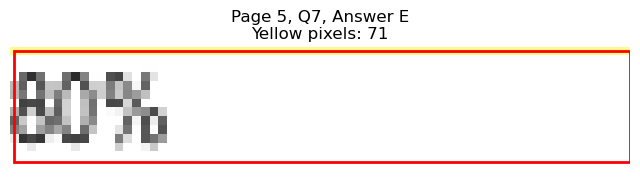


Page 5, Q7 - Selected Answer: D (based on yellow pixel count)





Page 6: Found 8 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=205.1, y1=139.9
Page 6, Q1, A: Yellow pixels: 0
Page 6, Q1, A: Total non-white pixels: 660
Page 6, Q1, A: Yellow percentage: 0.0%


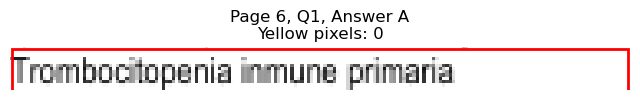

Page 6, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=109.0, y1=152.6
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 199
Page 6, Q1, B: Yellow percentage: 0.0%


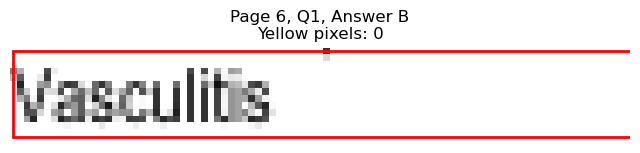

Page 6, Q1 - C: Detected box: x0=68.8, y0=152.5, x1=185.7, y1=165.2
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 599
Page 6, Q1, C: Yellow percentage: 0.0%


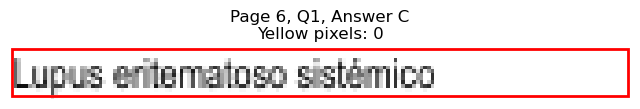

Page 6, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=429.9, y1=139.9
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 544
Page 6, Q1, D: Yellow percentage: 0.0%


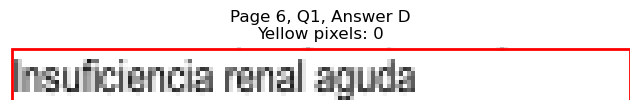

Page 6, Q1 - E: Detected box: x0=327.0, y0=139.9, x1=447.4, y1=152.6
Page 6, Q1, E: Yellow pixels: 1775
Page 6, Q1, E: Total non-white pixels: 2394
Page 6, Q1, E: Yellow percentage: 74.1%


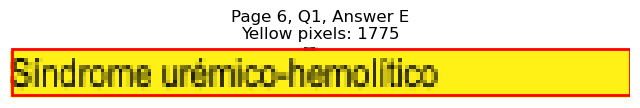


Page 6, Q1 - Selected Answer: E (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=268.5, y1=215.6
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 995
Page 6, Q2, A: Yellow percentage: 0.0%


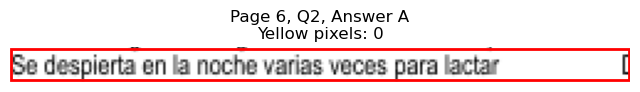

Page 6, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=199.7, y1=228.3
Page 6, Q2, B: Yellow pixels: 1637
Page 6, Q2, B: Total non-white pixels: 2548
Page 6, Q2, B: Yellow percentage: 64.2%


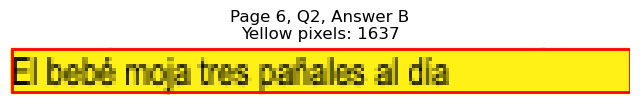

Page 6, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=202.2, y1=240.9
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 817
Page 6, Q2, C: Yellow percentage: 0.0%


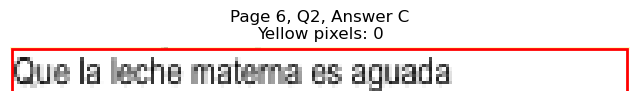

Page 6, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=509.6, y1=215.6
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 853
Page 6, Q2, D: Yellow percentage: 0.0%


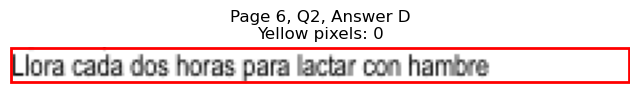

Page 6, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=474.2, y1=228.3
Page 6, Q2, E: Yellow pixels: 0
Page 6, Q2, E: Total non-white pixels: 696
Page 6, Q2, E: Yellow percentage: 0.0%


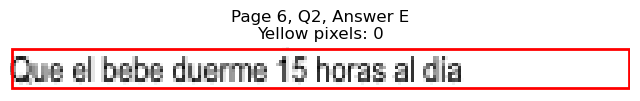


Page 6, Q2 - Selected Answer: B (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=135.5, y1=278.7
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 349
Page 6, Q3, A: Yellow percentage: 0.0%


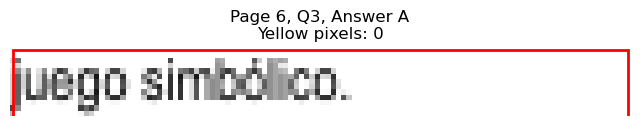

Page 6, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=207.3, y1=291.5
Page 6, Q3, B: Yellow pixels: 1955
Page 6, Q3, B: Total non-white pixels: 2660
Page 6, Q3, B: Yellow percentage: 73.5%


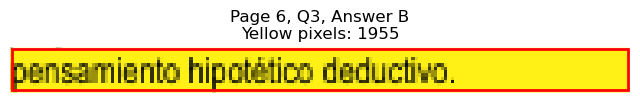

Page 6, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=170.5, y1=304.1
Page 6, Q3, C: Yellow pixels: 153
Page 6, Q3, C: Total non-white pixels: 659
Page 6, Q3, C: Yellow percentage: 23.2%


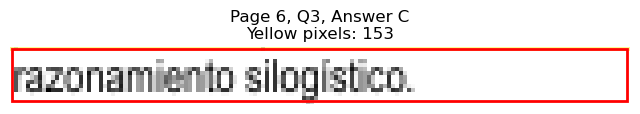

Page 6, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=433.4, y1=278.7
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 526
Page 6, Q3, D: Yellow percentage: 0.0%


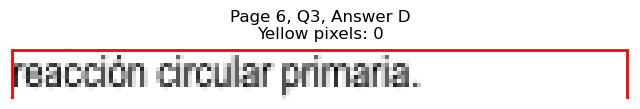

Page 6, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=444.4, y1=291.5
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 545
Page 6, Q3, E: Yellow percentage: 0.0%


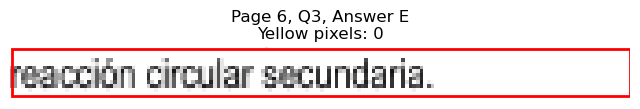


Page 6, Q3 - Selected Answer: B (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=331.1, y1=367.2
Page 6, Q4, A: Yellow pixels: 314
Page 6, Q4, A: Total non-white pixels: 1566
Page 6, Q4, A: Yellow percentage: 20.1%


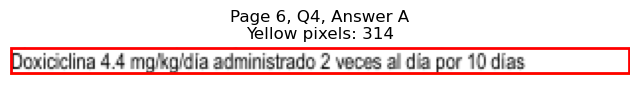

Page 6, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=311.6, y1=379.8
Page 6, Q4, B: Yellow pixels: 2881
Page 6, Q4, B: Total non-white pixels: 3822
Page 6, Q4, B: Yellow percentage: 75.4%


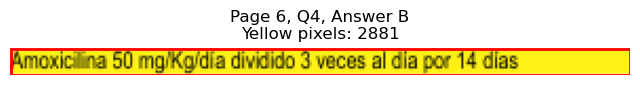

Page 6, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=333.7, y1=392.4
Page 6, Q4, C: Yellow pixels: 313
Page 6, Q4, C: Total non-white pixels: 1589
Page 6, Q4, C: Yellow percentage: 19.7%


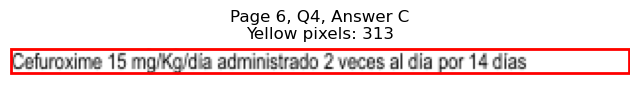

Page 6, Q4 - D: Detected box: x0=68.8, y0=392.3, x1=325.6, y1=405.0
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 1254
Page 6, Q4, D: Yellow percentage: 0.0%


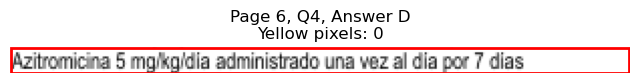

Page 6, Q4 - E: Detected box: x0=68.3, y0=404.9, x1=264.4, y1=417.6
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 982
Page 6, Q4, E: Yellow percentage: 0.0%


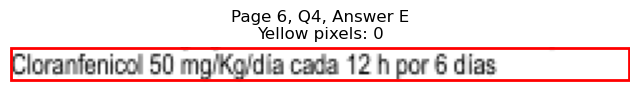


Page 6, Q4 - Selected Answer: B (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=468.1, x1=149.1, y1=480.7
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 385
Page 6, Q5, A: Yellow percentage: 0.0%


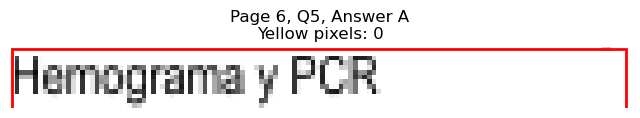

Page 6, Q5 - B: Detected box: x0=68.3, y0=480.8, x1=89.9, y1=493.4
Page 6, Q5, B: Yellow pixels: 0
Page 6, Q5, B: Total non-white pixels: 107
Page 6, Q5, B: Yellow percentage: 0.0%


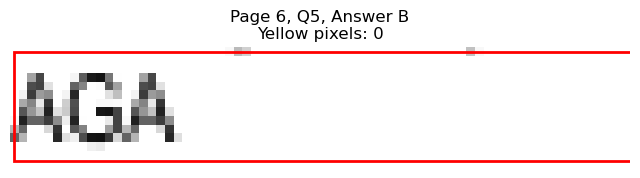

Page 6, Q5 - C: Detected box: x0=68.8, y0=493.4, x1=217.8, y1=506.0
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 758
Page 6, Q5, C: Yellow percentage: 0.0%


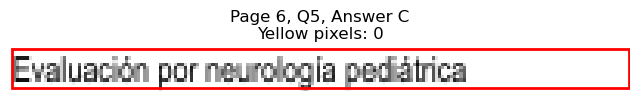

Page 6, Q5 - D: Detected box: x0=327.5, y0=468.1, x1=385.3, y1=480.7
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 274
Page 6, Q5, D: Yellow percentage: 0.0%


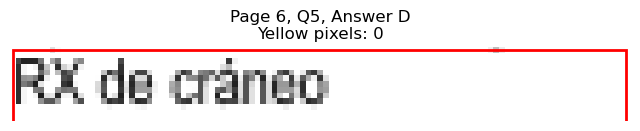

Page 6, Q5 - E: Detected box: x0=327.0, y0=480.8, x1=382.7, y1=493.4
Page 6, Q5, E: Yellow pixels: 1052
Page 6, Q5, E: Total non-white pixels: 1484
Page 6, Q5, E: Yellow percentage: 70.9%


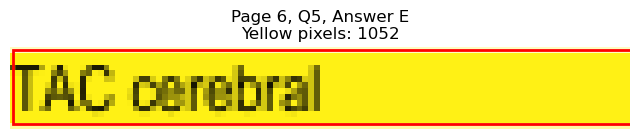


Page 6, Q5 - Selected Answer: E (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=569.1, x1=146.5, y1=581.8
Page 6, Q6, A: Yellow pixels: 0
Page 6, Q6, A: Total non-white pixels: 512
Page 6, Q6, A: Yellow percentage: 0.0%


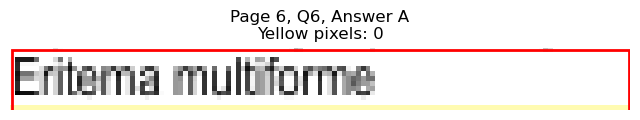

Page 6, Q6 - B: Detected box: x0=68.3, y0=581.7, x1=152.5, y1=594.4
Page 6, Q6, B: Yellow pixels: 1298
Page 6, Q6, B: Total non-white pixels: 1890
Page 6, Q6, B: Yellow percentage: 68.7%


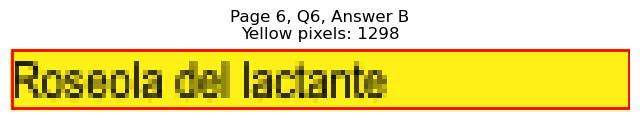

Page 6, Q6 - C: Detected box: x0=68.8, y0=594.3, x1=181.6, y1=607.0
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 711
Page 6, Q6, C: Yellow percentage: 0.0%


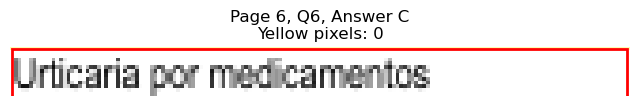

Page 6, Q6 - D: Detected box: x0=327.5, y0=569.1, x1=438.4, y1=581.8
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 593
Page 6, Q6, D: Yellow percentage: 0.0%


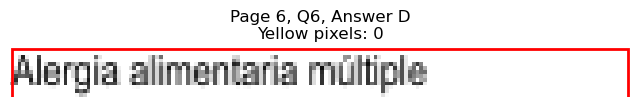

Page 6, Q6 - E: Detected box: x0=327.0, y0=581.7, x1=419.3, y1=594.4
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 456
Page 6, Q6, E: Yellow percentage: 0.0%


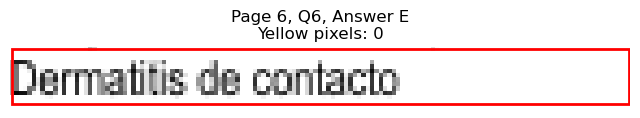


Page 6, Q6 - Selected Answer: B (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=670.1, x1=123.5, y1=682.7
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 297
Page 6, Q7, A: Yellow percentage: 0.0%


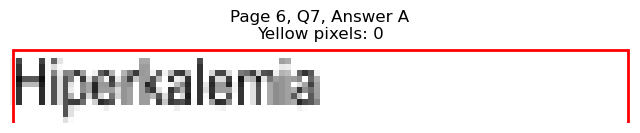

Page 6, Q7 - B: Detected box: x0=68.3, y0=682.7, x1=124.9, y1=695.3
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 285
Page 6, Q7, B: Yellow percentage: 0.0%


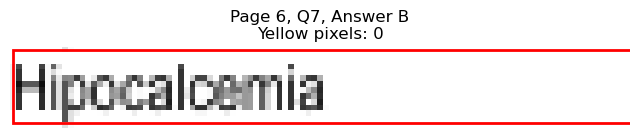

Page 6, Q7 - C: Detected box: x0=68.8, y0=695.4, x1=121.0, y1=708.0
Page 6, Q7, C: Yellow pixels: 1105
Page 6, Q7, C: Total non-white pixels: 1341
Page 6, Q7, C: Yellow percentage: 82.4%


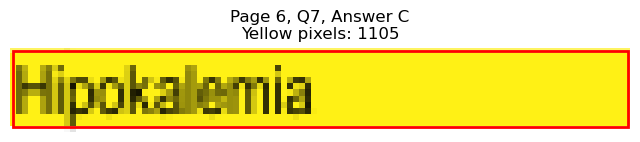

Page 6, Q7 - D: Detected box: x0=327.5, y0=670.1, x1=387.2, y1=682.7
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 324
Page 6, Q7, D: Yellow percentage: 0.0%


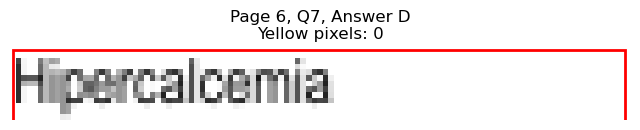

Page 6, Q7 - E: Detected box: x0=327.0, y0=682.7, x1=386.2, y1=695.3
Page 6, Q7, E: Yellow pixels: 0
Page 6, Q7, E: Total non-white pixels: 312
Page 6, Q7, E: Yellow percentage: 0.0%


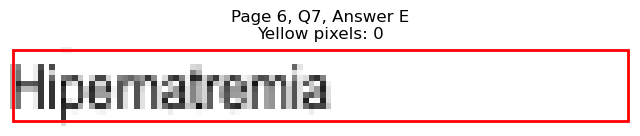


Page 6, Q7 - Selected Answer: C (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=733.2, x1=205.2, y1=745.8
Page 6, Q8, A: Yellow pixels: 1863
Page 6, Q8, A: Total non-white pixels: 2444
Page 6, Q8, A: Yellow percentage: 76.2%


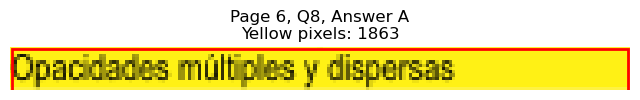

Page 6, Q8 - B: Detected box: x0=68.3, y0=745.8, x1=132.0, y1=758.4
Page 6, Q8, B: Yellow pixels: 115
Page 6, Q8, B: Total non-white pixels: 440
Page 6, Q8, B: Yellow percentage: 26.1%


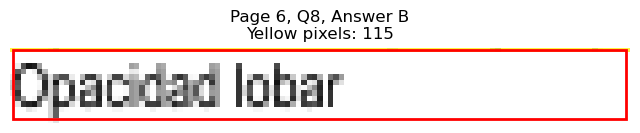

Page 6, Q8 - C: Detected box: x0=68.8, y0=758.5, x1=183.6, y1=771.2
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 573
Page 6, Q8, C: Yellow percentage: 0.0%


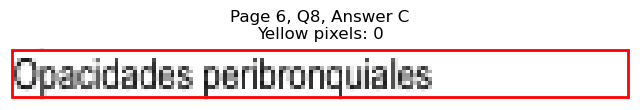

Page 6, Q8 - D: Detected box: x0=327.5, y0=733.2, x1=374.2, y1=745.8
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 259
Page 6, Q8, D: Yellow percentage: 0.0%


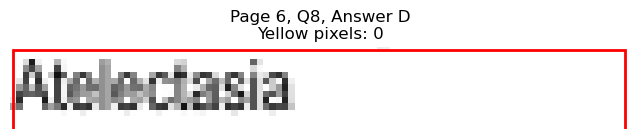

Page 6, Q8 - E: Detected box: x0=327.0, y0=745.8, x1=431.4, y1=758.4
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 542
Page 6, Q8, E: Yellow percentage: 0.0%


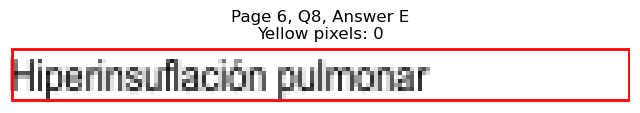


Page 6, Q8 - Selected Answer: A (based on yellow pixel count)





Page 7: Found 8 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=109.5, y1=127.3
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 210
Page 7, Q1, A: Yellow percentage: 0.0%


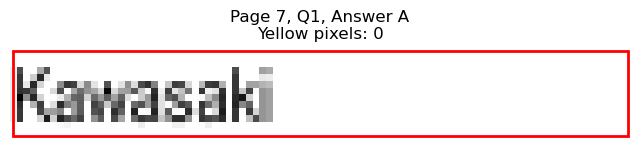

Page 7, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=130.9, y1=139.9
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 334
Page 7, Q1, B: Yellow percentage: 0.0%


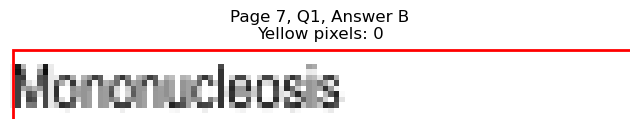

Page 7, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=115.0, y1=152.6
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 223
Page 7, Q1, C: Yellow percentage: 0.0%


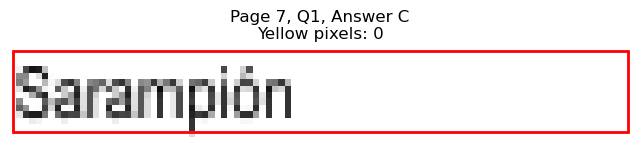

Page 7, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=374.7, y1=127.3
Page 7, Q1, D: Yellow pixels: 989
Page 7, Q1, D: Total non-white pixels: 1372
Page 7, Q1, D: Yellow percentage: 72.1%


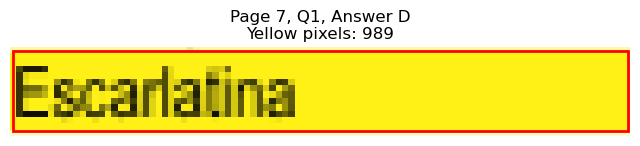

Page 7, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=403.3, y1=139.9
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 523
Page 7, Q1, E: Yellow percentage: 0.0%


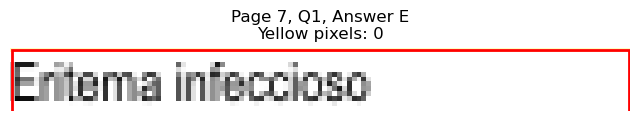


Page 7, Q1 - Selected Answer: D (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=215.7, x1=127.0, y1=228.3
Page 7, Q2, A: Yellow pixels: 109
Page 7, Q2, A: Total non-white pixels: 418
Page 7, Q2, A: Yellow percentage: 26.1%


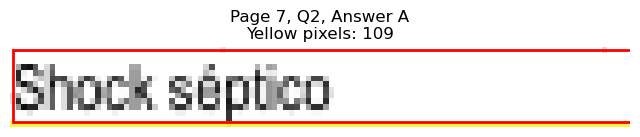

Page 7, Q2 - B: Detected box: x0=68.3, y0=228.3, x1=161.1, y1=240.9
Page 7, Q2, B: Yellow pixels: 1499
Page 7, Q2, B: Total non-white pixels: 1872
Page 7, Q2, B: Yellow percentage: 80.1%


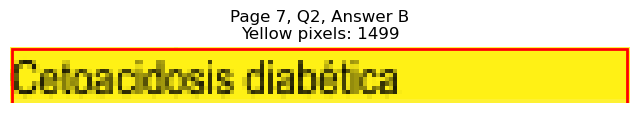

Page 7, Q2 - C: Detected box: x0=68.8, y0=240.9, x1=150.0, y1=253.5
Page 7, Q2, C: Yellow pixels: 133
Page 7, Q2, C: Total non-white pixels: 562
Page 7, Q2, C: Yellow percentage: 23.7%


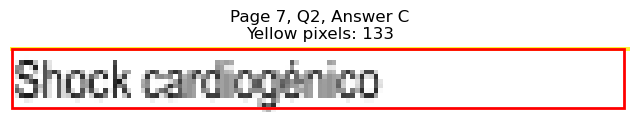

Page 7, Q2 - D: Detected box: x0=327.5, y0=215.7, x1=402.8, y1=228.3
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 383
Page 7, Q2, D: Yellow percentage: 0.0%


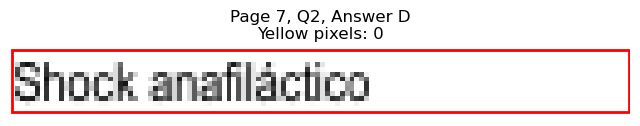

Page 7, Q2 - E: Detected box: x0=327.0, y0=228.3, x1=454.0, y1=240.9
Page 7, Q2, E: Yellow pixels: 0
Page 7, Q2, E: Total non-white pixels: 629
Page 7, Q2, E: Yellow percentage: 0.0%


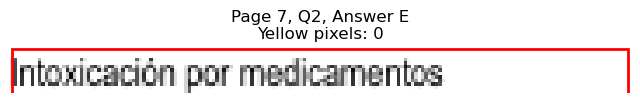


Page 7, Q2 - Selected Answer: B (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=304.0, x1=228.3, y1=316.7
Page 7, Q3, A: Yellow pixels: 2172
Page 7, Q3, A: Total non-white pixels: 2743
Page 7, Q3, A: Yellow percentage: 79.2%


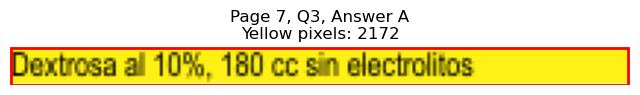

Page 7, Q3 - B: Detected box: x0=68.3, y0=316.6, x1=211.8, y1=329.3
Page 7, Q3, B: Yellow pixels: 194
Page 7, Q3, B: Total non-white pixels: 881
Page 7, Q3, B: Yellow percentage: 22.0%


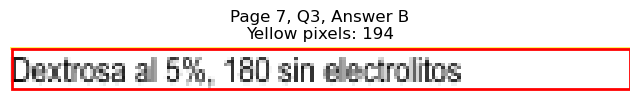

Page 7, Q3 - C: Detected box: x0=68.8, y0=329.2, x1=235.7, y1=341.9
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 794
Page 7, Q3, C: Yellow percentage: 0.0%


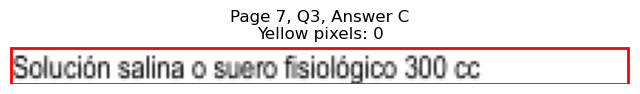

Page 7, Q3 - D: Detected box: x0=327.5, y0=304.0, x1=491.0, y1=316.7
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 771
Page 7, Q3, D: Yellow percentage: 0.0%


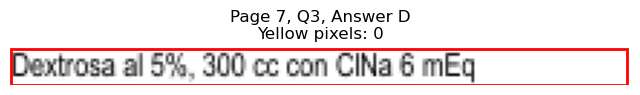

Page 7, Q3 - E: Detected box: x0=327.0, y0=316.6, x1=496.1, y1=329.3
Page 7, Q3, E: Yellow pixels: 0
Page 7, Q3, E: Total non-white pixels: 803
Page 7, Q3, E: Yellow percentage: 0.0%


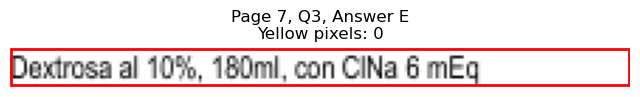


Page 7, Q3 - Selected Answer: A (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=114.5, y1=379.8
Page 7, Q4, A: Yellow pixels: 2
Page 7, Q4, A: Total non-white pixels: 352
Page 7, Q4, A: Yellow percentage: 0.6%


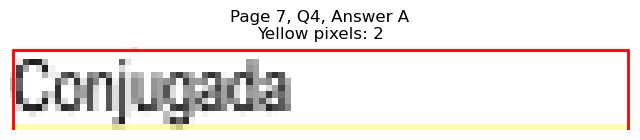

Page 7, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=150.0, y1=392.4
Page 7, Q4, B: Yellow pixels: 1302
Page 7, Q4, B: Total non-white pixels: 1862
Page 7, Q4, B: Yellow percentage: 69.9%


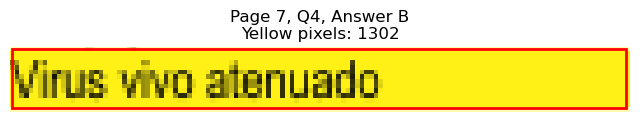

Page 7, Q4 - C: Detected box: x0=68.8, y0=392.3, x1=139.5, y1=405.0
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 479
Page 7, Q4, C: Yellow percentage: 0.0%


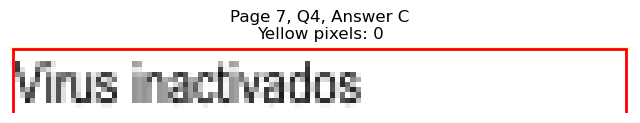

Page 7, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=349.1, y1=379.8
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 109
Page 7, Q4, D: Yellow percentage: 0.0%


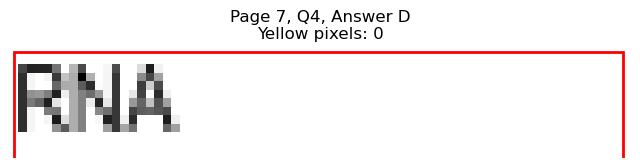

Page 7, Q4 - E: Detected box: x0=327.0, y0=379.7, x1=387.8, y1=392.4
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 330
Page 7, Q4, E: Yellow percentage: 0.0%


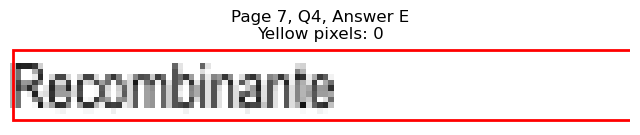


Page 7, Q4 - Selected Answer: B (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=115.5, y1=442.9
Page 7, Q5, A: Yellow pixels: 1081
Page 7, Q5, A: Total non-white pixels: 1274
Page 7, Q5, A: Yellow percentage: 84.9%


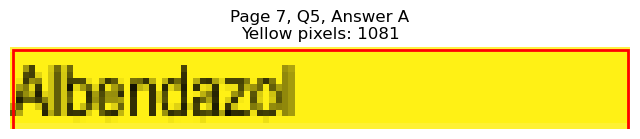

Page 7, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=151.6, y1=455.5
Page 7, Q5, B: Yellow pixels: 134
Page 7, Q5, B: Total non-white pixels: 539
Page 7, Q5, B: Yellow percentage: 24.9%


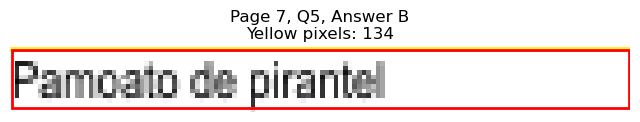

Page 7, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=118.0, y1=468.1
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 231
Page 7, Q5, C: Yellow percentage: 0.0%


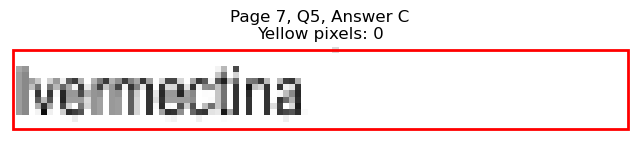

Page 7, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=382.3, y1=442.9
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 287
Page 7, Q5, D: Yellow percentage: 0.0%


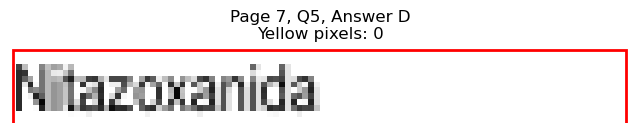

Page 7, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=378.8, y1=455.5
Page 7, Q5, E: Yellow pixels: 0
Page 7, Q5, E: Total non-white pixels: 272
Page 7, Q5, E: Yellow percentage: 0.0%


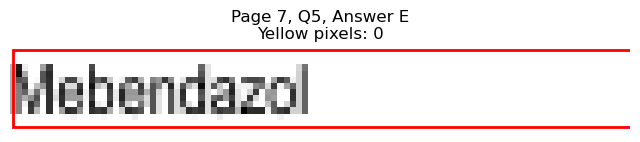


Page 7, Q5 - Selected Answer: A (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=100.3, y1=518.6
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 185
Page 7, Q6, A: Yellow percentage: 0.0%


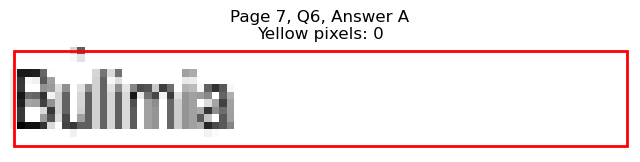

Page 7, Q6 - B: Detected box: x0=68.3, y0=518.6, x1=113.4, y1=531.2
Page 7, Q6, B: Yellow pixels: 96
Page 7, Q6, B: Total non-white pixels: 331
Page 7, Q6, B: Yellow percentage: 29.0%


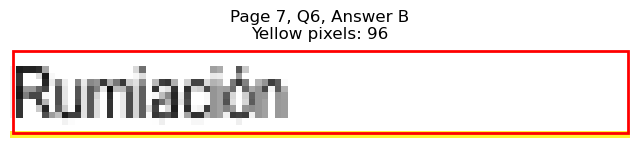

Page 7, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=88.8, y1=543.8
Page 7, Q6, C: Yellow pixels: 851
Page 7, Q6, C: Total non-white pixels: 923
Page 7, Q6, C: Yellow percentage: 92.2%


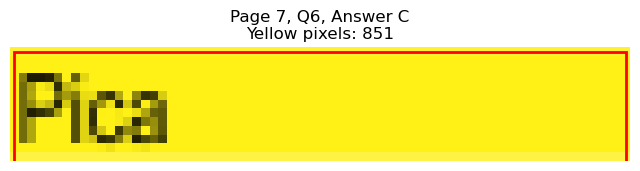

Page 7, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=363.2, y1=518.6
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 167
Page 7, Q6, D: Yellow percentage: 0.0%


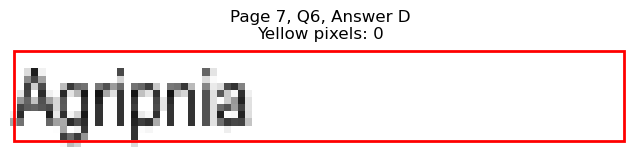

Page 7, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=366.7, y1=531.2
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 227
Page 7, Q6, E: Yellow percentage: 0.0%


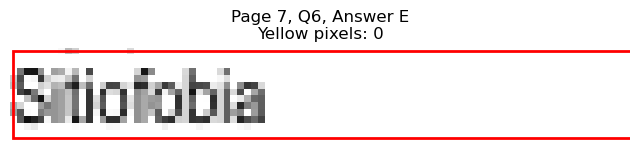


Page 7, Q6 - Selected Answer: C (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=594.3, x1=166.6, y1=607.0
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 620
Page 7, Q7, A: Yellow percentage: 0.0%


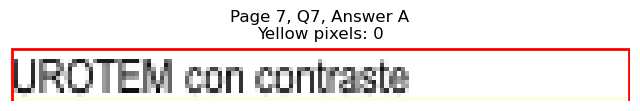

Page 7, Q7 - B: Detected box: x0=68.3, y0=606.9, x1=194.2, y1=619.6
Page 7, Q7, B: Yellow pixels: 1809
Page 7, Q7, B: Total non-white pixels: 2478
Page 7, Q7, B: Yellow percentage: 73.0%


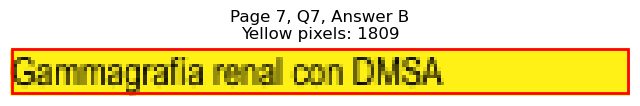

Page 7, Q7 - C: Detected box: x0=68.8, y0=619.6, x1=174.1, y1=632.3
Page 7, Q7, C: Yellow pixels: 155
Page 7, Q7, C: Total non-white pixels: 687
Page 7, Q7, C: Yellow percentage: 22.6%


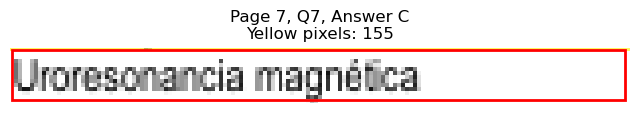

Page 7, Q7 - D: Detected box: x0=327.5, y0=594.3, x1=416.8, y1=607.0
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 462
Page 7, Q7, D: Yellow percentage: 0.0%


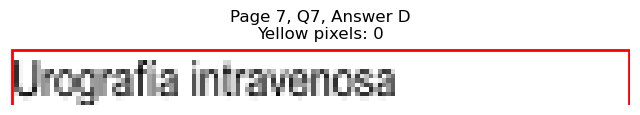

Page 7, Q7 - E: Detected box: x0=327.0, y0=606.9, x1=413.3, y1=619.6
Page 7, Q7, E: Yellow pixels: 0
Page 7, Q7, E: Total non-white pixels: 456
Page 7, Q7, E: Yellow percentage: 0.0%


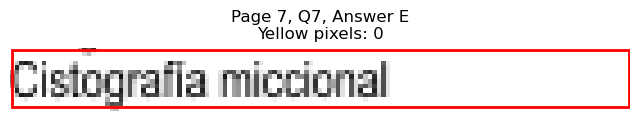


Page 7, Q7 - Selected Answer: B (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=682.7, x1=110.4, y1=695.3
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 210
Page 7, Q8, A: Yellow percentage: 0.0%


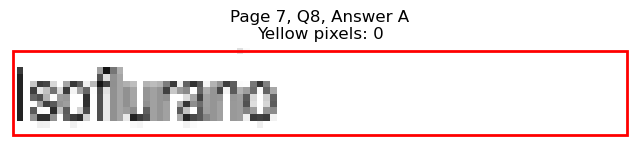

Page 7, Q8 - B: Detected box: x0=68.3, y0=695.4, x1=114.5, y1=708.0
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 246
Page 7, Q8, B: Yellow percentage: 0.0%


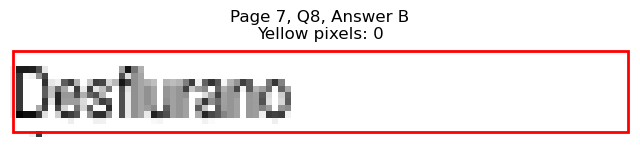

Page 7, Q8 - C: Detected box: x0=68.8, y0=708.0, x1=124.5, y1=720.6
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 270
Page 7, Q8, C: Yellow percentage: 0.0%


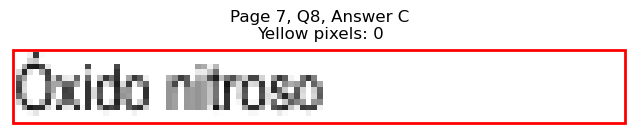

Page 7, Q8 - D: Detected box: x0=327.5, y0=682.7, x1=378.2, y1=695.3
Page 7, Q8, D: Yellow pixels: 1044
Page 7, Q8, D: Total non-white pixels: 1428
Page 7, Q8, D: Yellow percentage: 73.1%


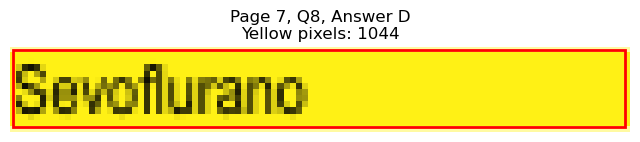

Page 7, Q8 - E: Detected box: x0=327.0, y0=695.4, x1=363.3, y1=708.0
Page 7, Q8, E: Yellow pixels: 0
Page 7, Q8, E: Total non-white pixels: 282
Page 7, Q8, E: Yellow percentage: 0.0%


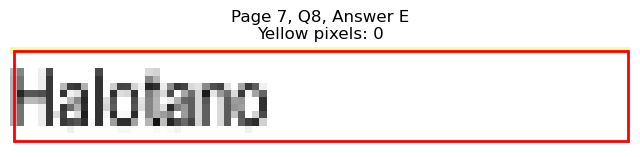


Page 7, Q8 - Selected Answer: D (based on yellow pixel count)





Page 8: Found 8 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=192.1, y1=139.9
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 617
Page 8, Q1, A: Yellow percentage: 0.0%


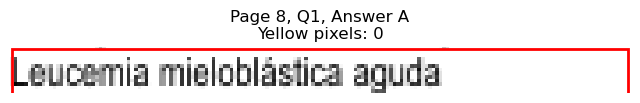

Page 8, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=187.2, y1=152.6
Page 8, Q1, B: Yellow pixels: 1749
Page 8, Q1, B: Total non-white pixels: 2380
Page 8, Q1, B: Yellow percentage: 73.5%


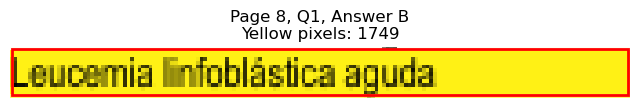

Page 8, Q1 - C: Detected box: x0=68.8, y0=152.5, x1=132.5, y1=165.2
Page 8, Q1, C: Yellow pixels: 113
Page 8, Q1, C: Total non-white pixels: 441
Page 8, Q1, C: Yellow percentage: 25.6%


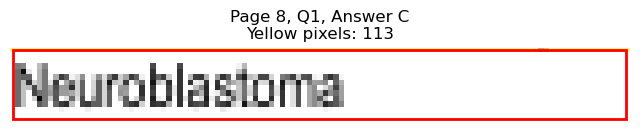

Page 8, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=405.8, y1=139.9
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 409
Page 8, Q1, D: Yellow percentage: 0.0%


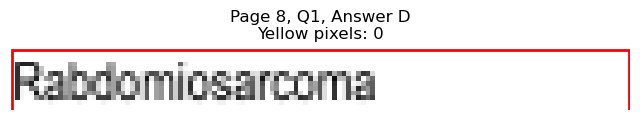

Page 8, Q1 - E: Detected box: x0=327.0, y0=139.9, x1=405.3, y1=152.6
Page 8, Q1, E: Yellow pixels: 0
Page 8, Q1, E: Total non-white pixels: 391
Page 8, Q1, E: Yellow percentage: 0.0%


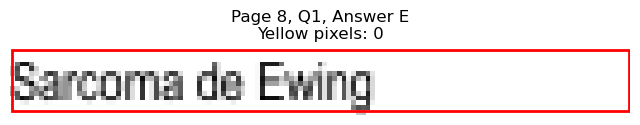


Page 8, Q1 - Selected Answer: B (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=223.4, y1=215.6
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 821
Page 8, Q2, A: Yellow percentage: 0.0%


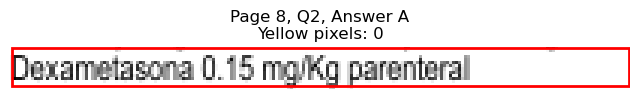

Page 8, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=184.7, y1=228.3
Page 8, Q2, B: Yellow pixels: 167
Page 8, Q2, B: Total non-white pixels: 710
Page 8, Q2, B: Yellow percentage: 23.5%


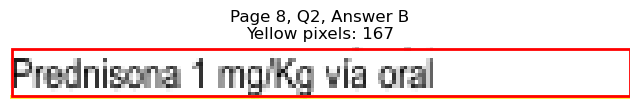

Page 8, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=228.3, y1=240.9
Page 8, Q2, C: Yellow pixels: 2092
Page 8, Q2, C: Total non-white pixels: 2743
Page 8, Q2, C: Yellow percentage: 76.3%


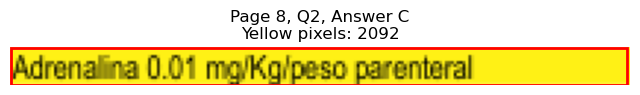

Page 8, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=459.5, y1=215.6
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 652
Page 8, Q2, D: Yellow percentage: 0.0%


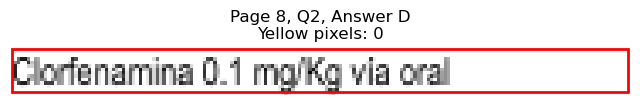

Page 8, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=470.0, y1=228.3
Page 8, Q2, E: Yellow pixels: 0
Page 8, Q2, E: Total non-white pixels: 733
Page 8, Q2, E: Yellow percentage: 0.0%


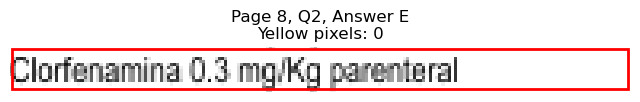


Page 8, Q2 - Selected Answer: C (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=291.4, x1=217.2, y1=304.1
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 719
Page 8, Q3, A: Yellow percentage: 0.0%


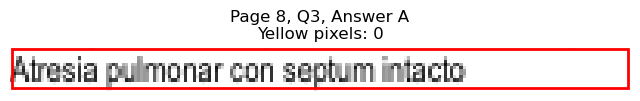

Page 8, Q3 - B: Detected box: x0=68.3, y0=304.0, x1=145.0, y1=316.7
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 378
Page 8, Q3, B: Yellow percentage: 0.0%


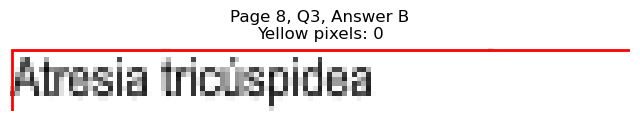

Page 8, Q3 - C: Detected box: x0=68.8, y0=316.6, x1=201.2, y1=329.3
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 668
Page 8, Q3, C: Yellow percentage: 0.0%


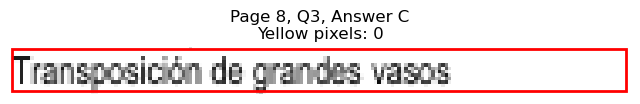

Page 8, Q3 - D: Detected box: x0=327.5, y0=291.4, x1=407.8, y1=304.1
Page 8, Q3, D: Yellow pixels: 1407
Page 8, Q3, D: Total non-white pixels: 1834
Page 8, Q3, D: Yellow percentage: 76.7%


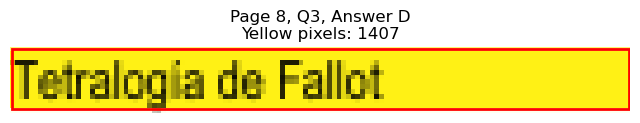

Page 8, Q3 - E: Detected box: x0=327.0, y0=304.0, x1=395.2, y1=316.7
Page 8, Q3, E: Yellow pixels: 0
Page 8, Q3, E: Total non-white pixels: 443
Page 8, Q3, E: Yellow percentage: 0.0%


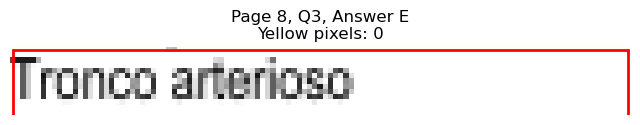


Page 8, Q3 - Selected Answer: D (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=187.2, y1=367.2
Page 8, Q4, A: Yellow pixels: 1748
Page 8, Q4, A: Total non-white pixels: 2380
Page 8, Q4, A: Yellow percentage: 73.4%


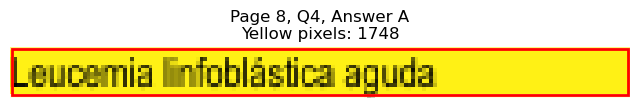

Page 8, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=177.6, y1=379.8
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 669
Page 8, Q4, B: Yellow percentage: 0.0%


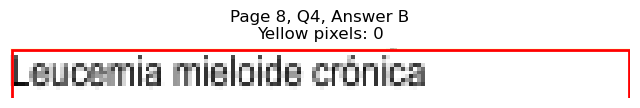

Page 8, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=174.3, y1=392.4
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 525
Page 8, Q4, C: Yellow percentage: 0.0%


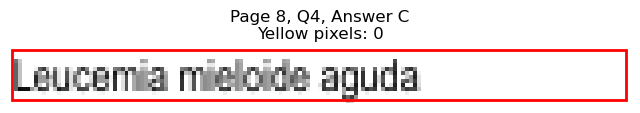

Page 8, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=464.9, y1=367.2
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 676
Page 8, Q4, D: Yellow percentage: 0.0%


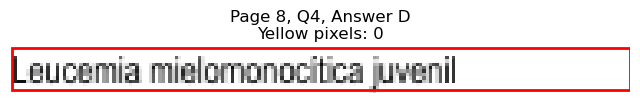

Page 8, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=441.4, y1=379.8
Page 8, Q4, E: Yellow pixels: 0
Page 8, Q4, E: Total non-white pixels: 606
Page 8, Q4, E: Yellow percentage: 0.0%


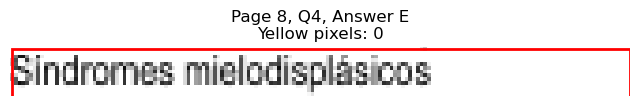


Page 8, Q4 - Selected Answer: A (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=442.8, x1=464.5, y1=455.5
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 1911
Page 8, Q5, A: Yellow percentage: 0.0%


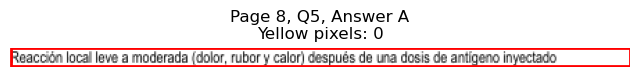

Page 8, Q5 - B: Detected box: x0=68.3, y0=455.5, x1=235.8, y1=468.1
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 838
Page 8, Q5, B: Yellow percentage: 0.0%


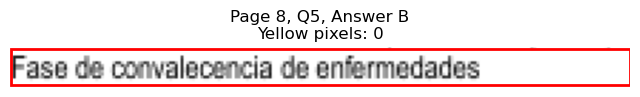

Page 8, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=346.1, y1=480.7
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 1343
Page 8, Q5, C: Yellow percentage: 0.0%


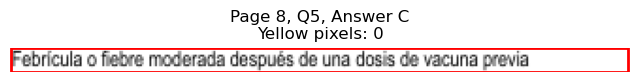

Page 8, Q5 - D: Detected box: x0=68.8, y0=480.8, x1=286.0, y1=493.4
Page 8, Q5, D: Yellow pixels: 269
Page 8, Q5, D: Total non-white pixels: 1327
Page 8, Q5, D: Yellow percentage: 20.3%


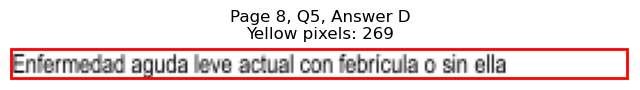

Page 8, Q5 - E: Detected box: x0=68.3, y0=493.4, x1=393.3, y1=506.0
Page 8, Q5, E: Yellow pixels: 3727
Page 8, Q5, E: Total non-white pixels: 4897
Page 8, Q5, E: Yellow percentage: 76.1%


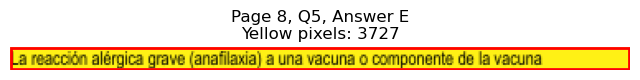


Page 8, Q5 - Selected Answer: E (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=543.8, x1=172.6, y1=556.4
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 501
Page 8, Q6, A: Yellow percentage: 0.0%


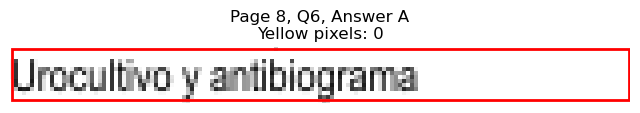

Page 8, Q6 - B: Detected box: x0=68.3, y0=556.5, x1=217.4, y1=569.2
Page 8, Q6, B: Yellow pixels: 200
Page 8, Q6, B: Total non-white pixels: 954
Page 8, Q6, B: Yellow percentage: 21.0%


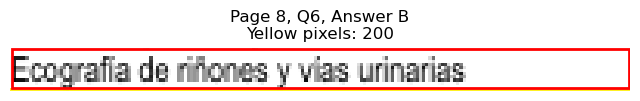

Page 8, Q6 - C: Detected box: x0=68.8, y0=569.1, x1=165.1, y1=581.8
Page 8, Q6, C: Yellow pixels: 1559
Page 8, Q6, C: Total non-white pixels: 1924
Page 8, Q6, C: Yellow percentage: 81.0%


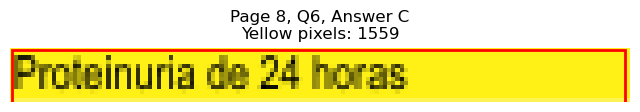

Page 8, Q6 - D: Detected box: x0=327.5, y0=543.8, x1=407.9, y1=556.4
Page 8, Q6, D: Yellow pixels: 0
Page 8, Q6, D: Total non-white pixels: 424
Page 8, Q6, D: Yellow percentage: 0.0%


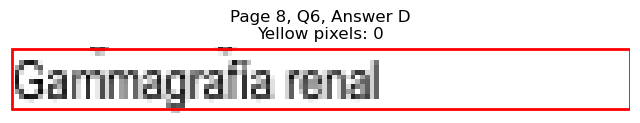

Page 8, Q6 - E: Detected box: x0=327.0, y0=556.5, x1=429.9, y1=569.2
Page 8, Q6, E: Yellow pixels: 0
Page 8, Q6, E: Total non-white pixels: 514
Page 8, Q6, E: Yellow percentage: 0.0%


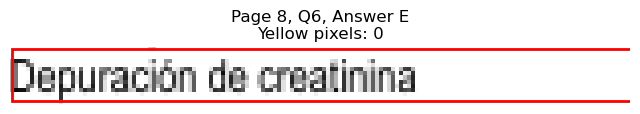


Page 8, Q6 - Selected Answer: C (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=606.9, x1=263.4, y1=619.6
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 917
Page 8, Q7, A: Yellow percentage: 0.0%


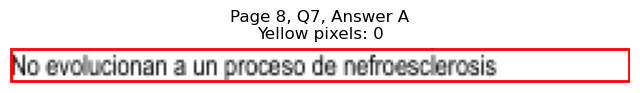

Page 8, Q7 - B: Detected box: x0=68.3, y0=619.6, x1=266.9, y1=632.3
Page 8, Q7, B: Yellow pixels: 249
Page 8, Q7, B: Total non-white pixels: 1180
Page 8, Q7, B: Yellow percentage: 21.1%


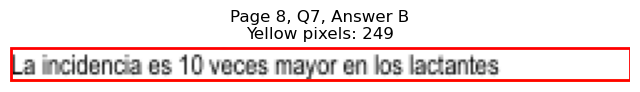

Page 8, Q7 - C: Detected box: x0=68.8, y0=632.2, x1=271.4, y1=644.9
Page 8, Q7, C: Yellow pixels: 2553
Page 8, Q7, C: Total non-white pixels: 3302
Page 8, Q7, C: Yellow percentage: 77.3%


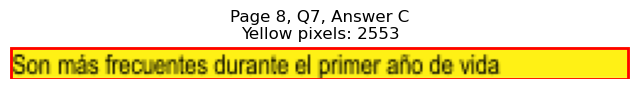

Page 8, Q7 - D: Detected box: x0=68.8, y0=644.9, x1=434.9, y1=657.5
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 1730
Page 8, Q7, D: Yellow percentage: 0.0%


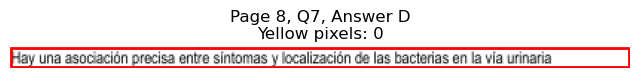

Page 8, Q7 - E: Detected box: x0=68.3, y0=657.5, x1=401.8, y1=670.1
Page 8, Q7, E: Yellow pixels: 0
Page 8, Q7, E: Total non-white pixels: 1679
Page 8, Q7, E: Yellow percentage: 0.0%


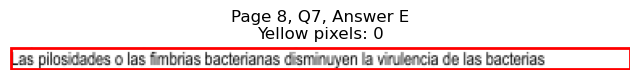


Page 8, Q7 - Selected Answer: C (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=720.6, x1=133.9, y1=733.2
Page 8, Q8, A: Yellow pixels: 116
Page 8, Q8, A: Total non-white pixels: 442
Page 8, Q8, A: Yellow percentage: 26.2%


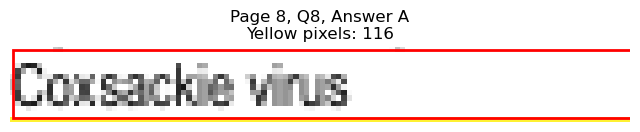

Page 8, Q8 - B: Detected box: x0=68.3, y0=733.2, x1=115.9, y1=745.8
Page 8, Q8, B: Yellow pixels: 1078
Page 8, Q8, B: Total non-white pixels: 1274
Page 8, Q8, B: Yellow percentage: 84.6%


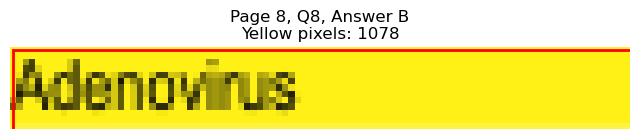

Page 8, Q8 - C: Detected box: x0=68.8, y0=745.8, x1=150.5, y1=758.4
Page 8, Q8, C: Yellow pixels: 133
Page 8, Q8, C: Total non-white pixels: 539
Page 8, Q8, C: Yellow percentage: 24.7%


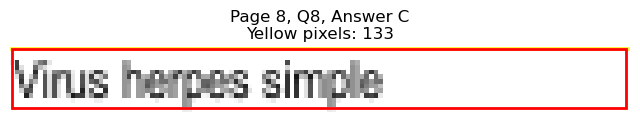

Page 8, Q8 - D: Detected box: x0=327.5, y0=720.6, x1=415.3, y1=733.2
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 426
Page 8, Q8, D: Yellow percentage: 0.0%


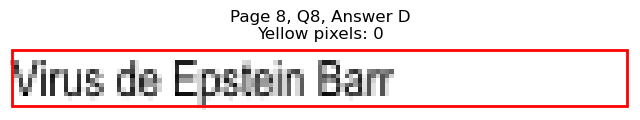

Page 8, Q8 - E: Detected box: x0=327.0, y0=733.2, x1=398.9, y1=745.8
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 399
Page 8, Q8, E: Yellow percentage: 0.0%


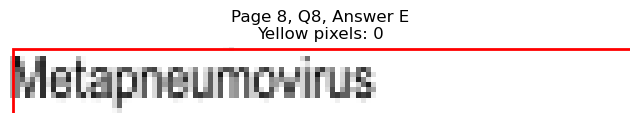


Page 8, Q8 - Selected Answer: B (based on yellow pixel count)





Page 9: Found 8 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=139.6, y1=102.1
Page 9, Q1, A: Yellow pixels: 122
Page 9, Q1, A: Total non-white pixels: 456
Page 9, Q1, A: Yellow percentage: 26.8%


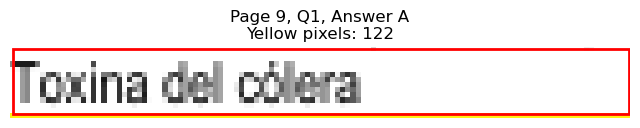

Page 9, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=223.2, y1=114.7
Page 9, Q1, B: Yellow pixels: 2076
Page 9, Q1, B: Total non-white pixels: 2678
Page 9, Q1, B: Yellow percentage: 77.5%


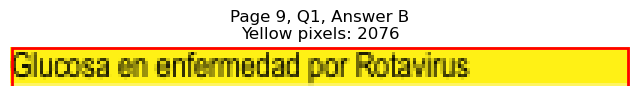

Page 9, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=167.5, y1=127.3
Page 9, Q1, C: Yellow pixels: 150
Page 9, Q1, C: Total non-white pixels: 651
Page 9, Q1, C: Yellow percentage: 23.0%


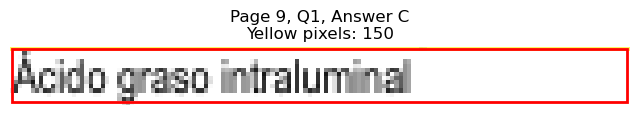

Page 9, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=432.3, y1=102.1
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 564
Page 9, Q1, D: Yellow percentage: 0.0%


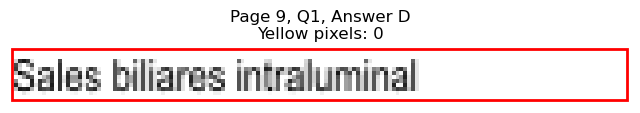

Page 9, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=523.2, y1=114.7
Page 9, Q1, E: Yellow pixels: 0
Page 9, Q1, E: Total non-white pixels: 1005
Page 9, Q1, E: Yellow percentage: 0.0%


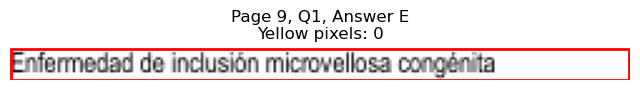


Page 9, Q1 - Selected Answer: B (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=153.5, y1=177.8
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 443
Page 9, Q2, A: Yellow percentage: 0.0%


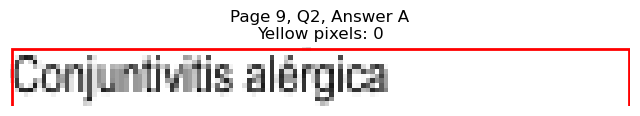

Page 9, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=121.5, y1=190.4
Page 9, Q2, B: Yellow pixels: 104
Page 9, Q2, B: Total non-white pixels: 392
Page 9, Q2, B: Yellow percentage: 26.5%


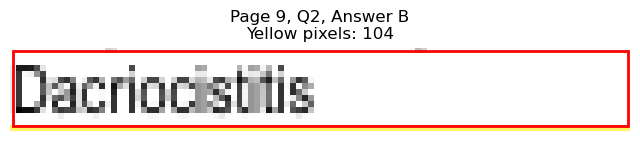

Page 9, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=154.1, y1=203.0
Page 9, Q2, C: Yellow pixels: 1429
Page 9, Q2, C: Total non-white pixels: 1781
Page 9, Q2, C: Yellow percentage: 80.2%


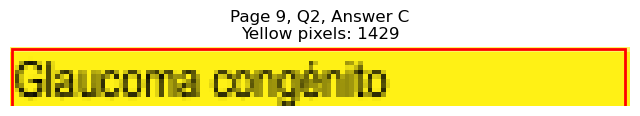

Page 9, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=423.3, y1=177.8
Page 9, Q2, D: Yellow pixels: 0
Page 9, Q2, D: Total non-white pixels: 510
Page 9, Q2, D: Yellow percentage: 0.0%


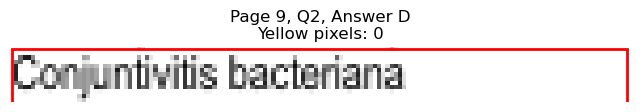

Page 9, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=386.7, y1=190.4
Page 9, Q2, E: Yellow pixels: 0
Page 9, Q2, E: Total non-white pixels: 323
Page 9, Q2, E: Yellow percentage: 0.0%


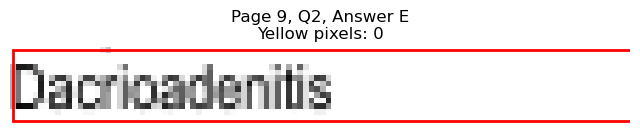


Page 9, Q2 - Selected Answer: C (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=172.1, y1=266.1
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 527
Page 9, Q3, A: Yellow percentage: 0.0%


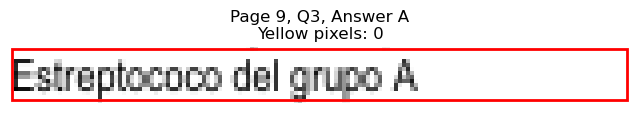

Page 9, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=150.0, y1=278.7
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 392
Page 9, Q3, B: Yellow percentage: 0.0%


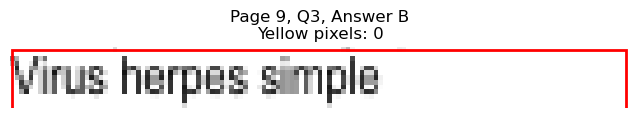

Page 9, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=116.4, y1=291.5
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 223
Page 9, Q3, C: Yellow percentage: 0.0%


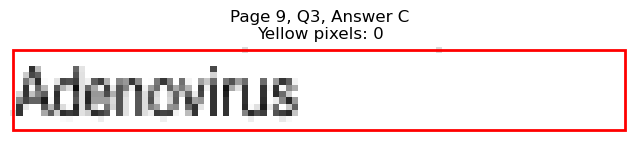

Page 9, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=415.3, y1=266.1
Page 9, Q3, D: Yellow pixels: 139
Page 9, Q3, D: Total non-white pixels: 563
Page 9, Q3, D: Yellow percentage: 24.7%


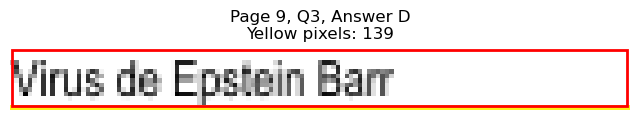

Page 9, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=392.7, y1=278.7
Page 9, Q3, E: Yellow pixels: 1279
Page 9, Q3, E: Total non-white pixels: 1508
Page 9, Q3, E: Yellow percentage: 84.8%


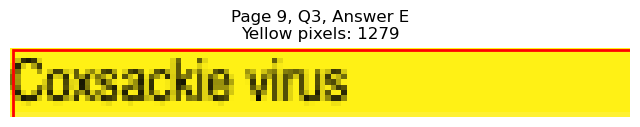


Page 9, Q3 - Selected Answer: E (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=143.5, y1=367.2
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 378
Page 9, Q4, A: Yellow percentage: 0.0%


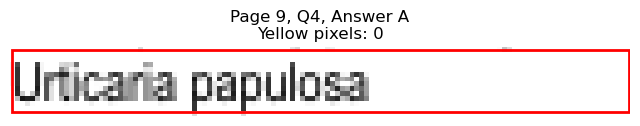

Page 9, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=130.5, y1=379.8
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 314
Page 9, Q4, B: Yellow percentage: 0.0%


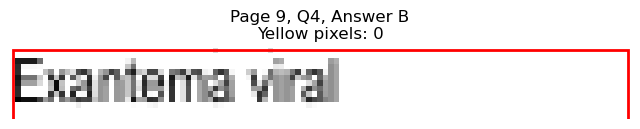

Page 9, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=165.0, y1=392.4
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 510
Page 9, Q4, C: Yellow percentage: 0.0%


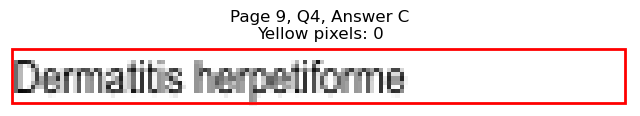

Page 9, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=402.3, y1=367.2
Page 9, Q4, D: Yellow pixels: 126
Page 9, Q4, D: Total non-white pixels: 521
Page 9, Q4, D: Yellow percentage: 24.2%


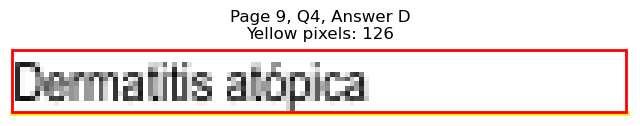

Page 9, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=372.7, y1=379.8
Page 9, Q4, E: Yellow pixels: 1063
Page 9, Q4, E: Total non-white pixels: 1248
Page 9, Q4, E: Yellow percentage: 85.2%


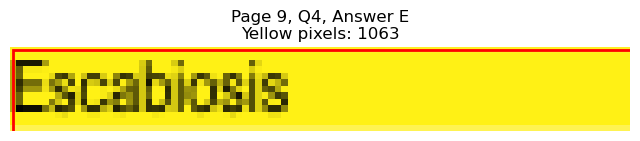


Page 9, Q4 - Selected Answer: E (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=298.5, y1=430.3
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 1103
Page 9, Q5, A: Yellow percentage: 0.0%


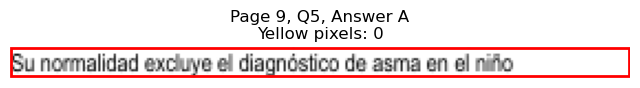

Page 9, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=219.3, y1=442.9
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 901
Page 9, Q5, B: Yellow percentage: 0.0%


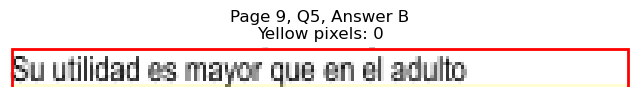

Page 9, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=360.8, y1=455.5
Page 9, Q5, C: Yellow pixels: 3349
Page 9, Q5, C: Total non-white pixels: 4802
Page 9, Q5, C: Yellow percentage: 69.7%


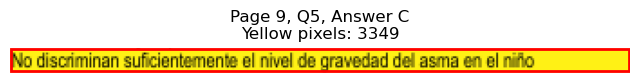

Page 9, Q5 - D: Detected box: x0=68.8, y0=455.5, x1=268.4, y1=468.1
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 961
Page 9, Q5, D: Yellow percentage: 0.0%


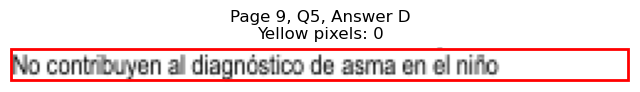

Page 9, Q5 - E: Detected box: x0=68.3, y0=468.1, x1=424.9, y1=480.7
Page 9, Q5, E: Yellow pixels: 0
Page 9, Q5, E: Total non-white pixels: 1772
Page 9, Q5, E: Yellow percentage: 0.0%


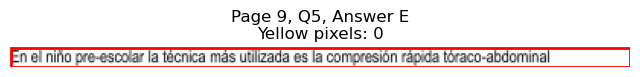


Page 9, Q5 - Selected Answer: C (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=543.8, x1=168.1, y1=556.4
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 530
Page 9, Q6, A: Yellow percentage: 0.0%


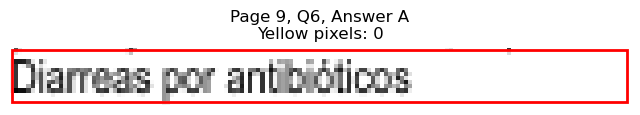

Page 9, Q6 - B: Detected box: x0=68.3, y0=556.5, x1=98.1, y1=569.2
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 167
Page 9, Q6, B: Yellow percentage: 0.0%


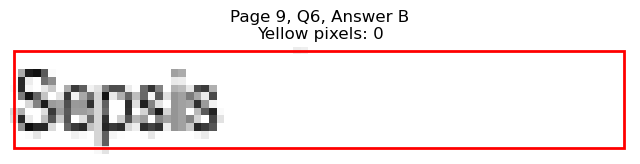

Page 9, Q6 - C: Detected box: x0=68.8, y0=569.1, x1=204.6, y1=581.8
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 657
Page 9, Q6, C: Yellow percentage: 0.0%


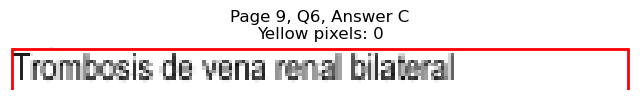

Page 9, Q6 - D: Detected box: x0=327.5, y0=543.8, x1=447.9, y1=556.4
Page 9, Q6, D: Yellow pixels: 1747
Page 9, Q6, D: Total non-white pixels: 2394
Page 9, Q6, D: Yellow percentage: 73.0%


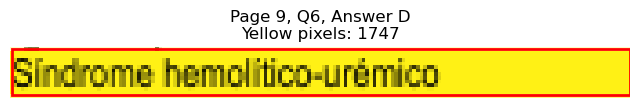

Page 9, Q6 - E: Detected box: x0=327.0, y0=556.5, x1=414.3, y1=569.2
Page 9, Q6, E: Yellow pixels: 138
Page 9, Q6, E: Total non-white pixels: 606
Page 9, Q6, E: Yellow percentage: 22.8%


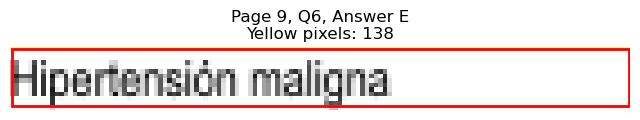


Page 9, Q6 - Selected Answer: D (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=632.2, x1=173.7, y1=644.9
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 557
Page 9, Q7, A: Yellow percentage: 0.0%


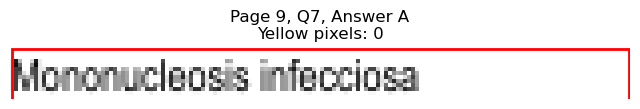

Page 9, Q7 - B: Detected box: x0=68.3, y0=644.9, x1=117.5, y1=657.5
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 272
Page 9, Q7, B: Yellow percentage: 0.0%


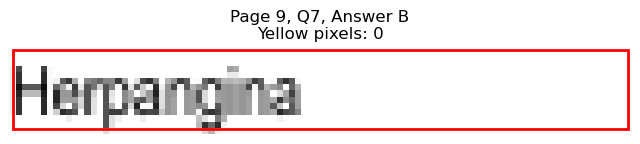

Page 9, Q7 - C: Detected box: x0=68.8, y0=657.5, x1=170.1, y1=670.1
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 516
Page 9, Q7, C: Yellow percentage: 0.0%


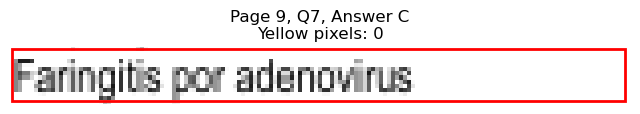

Page 9, Q7 - D: Detected box: x0=327.5, y0=632.2, x1=427.4, y1=644.9
Page 9, Q7, D: Yellow pixels: 1542
Page 9, Q7, D: Total non-white pixels: 1963
Page 9, Q7, D: Yellow percentage: 78.6%


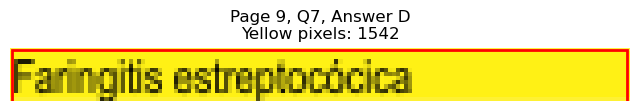

Page 9, Q7 - E: Detected box: x0=327.0, y0=644.9, x1=405.8, y1=657.5
Page 9, Q7, E: Yellow pixels: 0
Page 9, Q7, E: Total non-white pixels: 440
Page 9, Q7, E: Yellow percentage: 0.0%


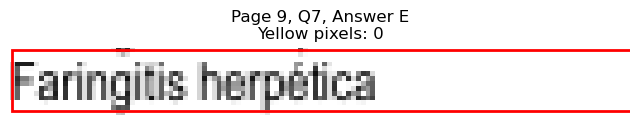


Page 9, Q7 - Selected Answer: D (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=708.0, x1=137.1, y1=720.6
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 364
Page 9, Q8, A: Yellow percentage: 0.0%


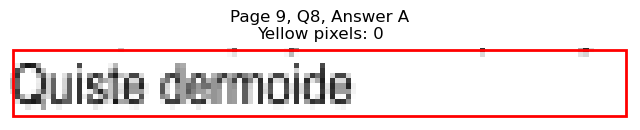

Page 9, Q8 - B: Detected box: x0=68.3, y0=720.6, x1=128.5, y1=733.2
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 333
Page 9, Q8, B: Yellow percentage: 0.0%


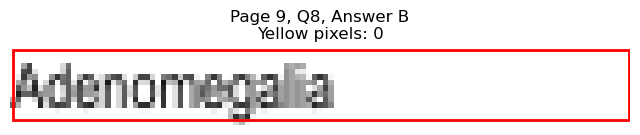

Page 9, Q8 - C: Detected box: x0=68.8, y0=733.2, x1=100.9, y1=745.8
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 155
Page 9, Q8, C: Yellow percentage: 0.0%


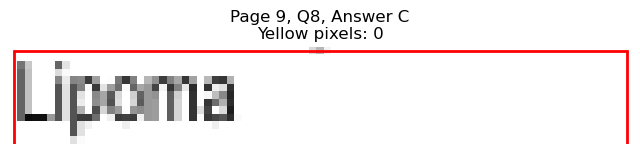

Page 9, Q8 - D: Detected box: x0=327.5, y0=708.0, x1=352.6, y1=720.6
Page 9, Q8, D: Yellow pixels: 76
Page 9, Q8, D: Total non-white pixels: 212
Page 9, Q8, D: Yellow percentage: 35.8%


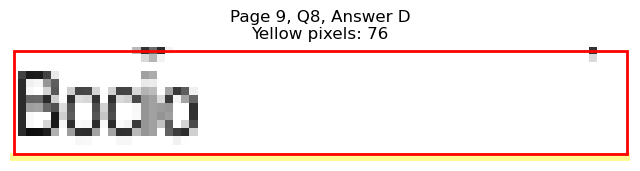

Page 9, Q8 - E: Detected box: x0=327.0, y0=720.6, x1=389.7, y1=733.2
Page 9, Q8, E: Yellow pixels: 1175
Page 9, Q8, E: Total non-white pixels: 1582
Page 9, Q8, E: Yellow percentage: 74.3%


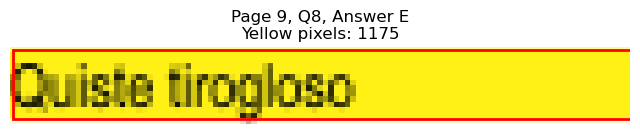


Page 9, Q8 - Selected Answer: E (based on yellow pixel count)





Page 10: Found 7 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=103.5, y1=139.9
Page 10, Q1, A: Yellow pixels: 968
Page 10, Q1, A: Total non-white pixels: 1118
Page 10, Q1, A: Yellow percentage: 86.6%


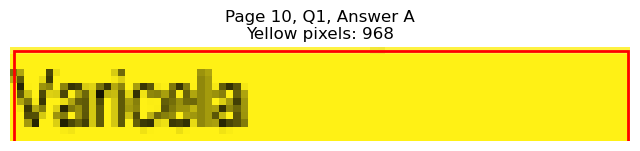

Page 10, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=132.5, y1=152.6
Page 10, Q1, B: Yellow pixels: 115
Page 10, Q1, B: Total non-white pixels: 443
Page 10, Q1, B: Yellow percentage: 26.0%


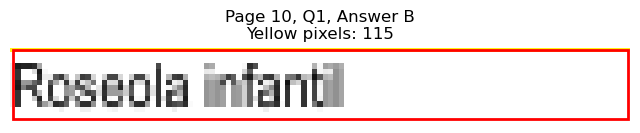

Page 10, Q1 - C: Detected box: x0=68.8, y0=152.5, x1=145.0, y1=165.2
Page 10, Q1, C: Yellow pixels: 0
Page 10, Q1, C: Total non-white pixels: 387
Page 10, Q1, C: Yellow percentage: 0.0%


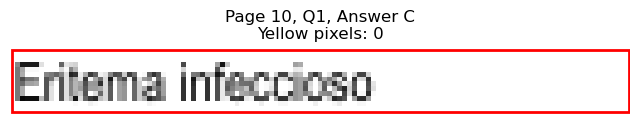

Page 10, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=381.7, y1=139.9
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 250
Page 10, Q1, D: Yellow percentage: 0.0%


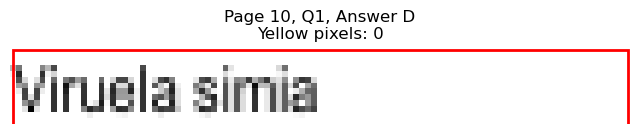

Page 10, Q1 - E: Detected box: x0=327.0, y0=139.9, x1=436.0, y1=152.6
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 572
Page 10, Q1, E: Yellow percentage: 0.0%


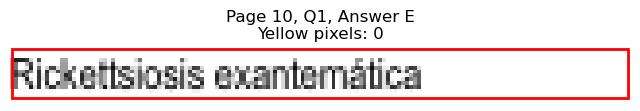


Page 10, Q1 - Selected Answer: A (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=88.8, y1=215.6
Page 10, Q2, A: Yellow pixels: 0
Page 10, Q2, A: Total non-white pixels: 114
Page 10, Q2, A: Yellow percentage: 0.0%


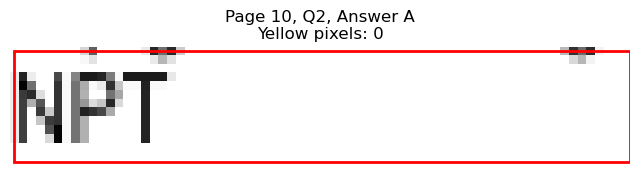

Page 10, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=136.6, y1=228.3
Page 10, Q2, B: Yellow pixels: 0
Page 10, Q2, B: Total non-white pixels: 358
Page 10, Q2, B: Yellow percentage: 0.0%


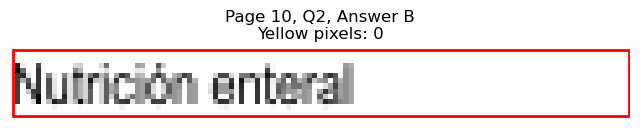

Page 10, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=126.0, y1=240.9
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 299
Page 10, Q2, C: Yellow percentage: 0.0%


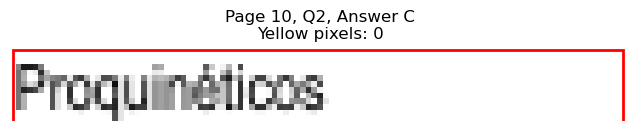

Page 10, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=480.7, y1=215.6
Page 10, Q2, D: Yellow pixels: 0
Page 10, Q2, D: Total non-white pixels: 786
Page 10, Q2, D: Yellow percentage: 0.0%


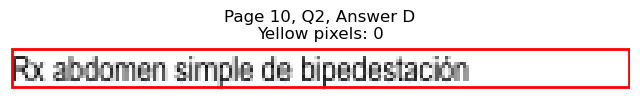

Page 10, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=385.4, y1=228.3
Page 10, Q2, E: Yellow pixels: 1086
Page 10, Q2, E: Total non-white pixels: 1526
Page 10, Q2, E: Yellow percentage: 71.2%


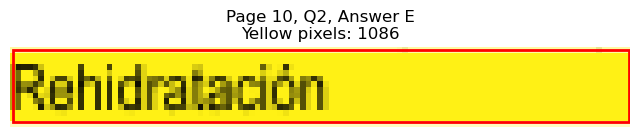


Page 10, Q2 - Selected Answer: E (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=56.6, y0=291.4, x1=65.2, y1=304.1
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 70
Page 10, Q3, A: Yellow percentage: 0.0%


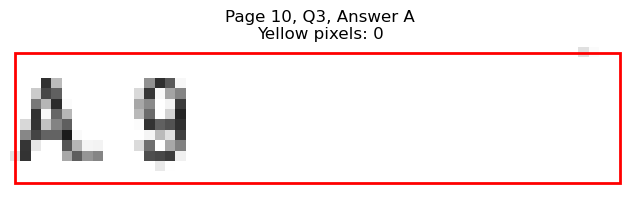

Page 10, Q3 - B: Detected box: x0=56.6, y0=304.0, x1=65.2, y1=316.7
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 125
Page 10, Q3, B: Yellow percentage: 0.0%


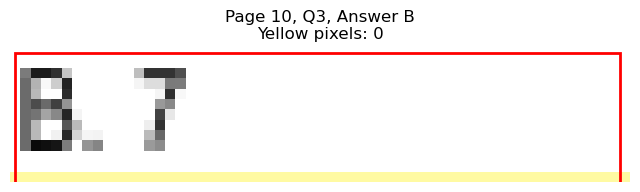

Page 10, Q3 - C: Detected box: x0=68.8, y0=316.6, x1=81.4, y1=329.3
Page 10, Q3, C: Yellow pixels: 746
Page 10, Q3, C: Total non-white pixels: 896
Page 10, Q3, C: Yellow percentage: 83.3%


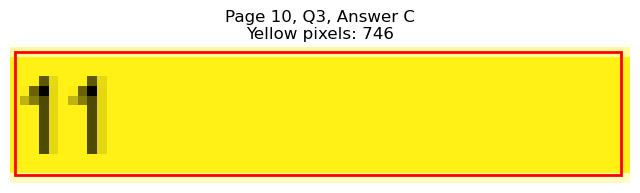

Page 10, Q3 - D: Detected box: x0=315.4, y0=291.4, x1=324.4, y1=304.1
Page 10, Q3, D: Yellow pixels: 0
Page 10, Q3, D: Total non-white pixels: 73
Page 10, Q3, D: Yellow percentage: 0.0%


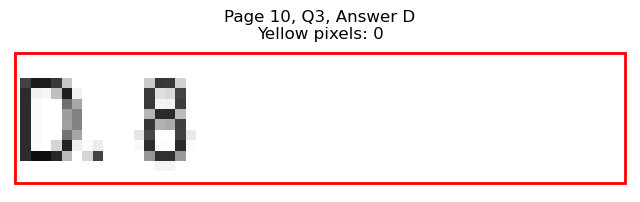

Page 10, Q3 - E: Detected box: x0=315.4, y0=304.0, x1=323.9, y1=316.7
Page 10, Q3, E: Yellow pixels: 0
Page 10, Q3, E: Total non-white pixels: 71
Page 10, Q3, E: Yellow percentage: 0.0%


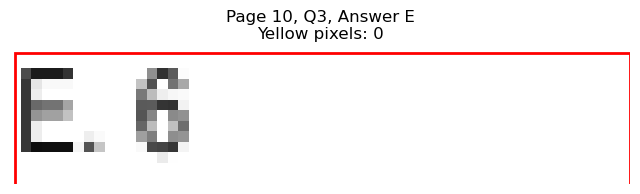


Page 10, Q3 - Selected Answer: C (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=392.3, x1=97.9, y1=405.0
Page 10, Q4, A: Yellow pixels: 0
Page 10, Q4, A: Total non-white pixels: 165
Page 10, Q4, A: Yellow percentage: 0.0%


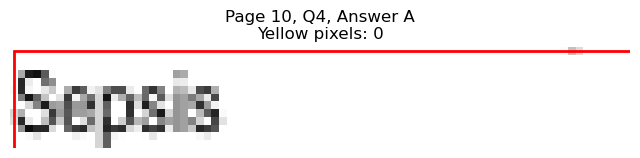

Page 10, Q4 - B: Detected box: x0=68.3, y0=404.9, x1=151.6, y1=417.6
Page 10, Q4, B: Yellow pixels: 0
Page 10, Q4, B: Total non-white pixels: 421
Page 10, Q4, B: Yellow percentage: 0.0%


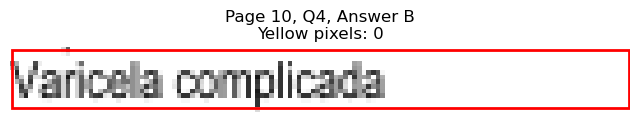

Page 10, Q4 - C: Detected box: x0=68.8, y0=417.6, x1=174.1, y1=430.3
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 548
Page 10, Q4, C: Yellow percentage: 0.0%


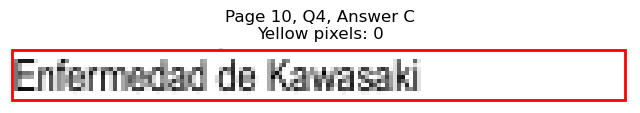

Page 10, Q4 - D: Detected box: x0=327.5, y0=392.3, x1=434.0, y1=405.0
Page 10, Q4, D: Yellow pixels: 1616
Page 10, Q4, D: Total non-white pixels: 2041
Page 10, Q4, D: Yellow percentage: 79.2%


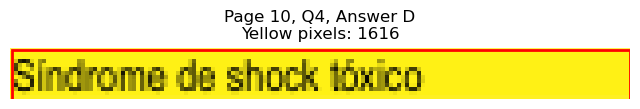

Page 10, Q4 - E: Detected box: x0=327.0, y0=404.9, x1=441.4, y1=417.6
Page 10, Q4, E: Yellow pixels: 165
Page 10, Q4, E: Total non-white pixels: 776
Page 10, Q4, E: Yellow percentage: 21.3%


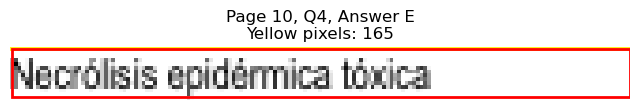


Page 10, Q4 - Selected Answer: D (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=493.4, x1=166.1, y1=506.0
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 488
Page 10, Q5, A: Yellow percentage: 0.0%


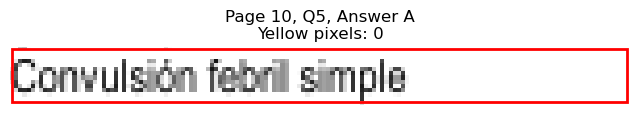

Page 10, Q5 - B: Detected box: x0=68.3, y0=506.0, x1=107.4, y1=518.6
Page 10, Q5, B: Yellow pixels: 90
Page 10, Q5, B: Total non-white pixels: 313
Page 10, Q5, B: Yellow percentage: 28.8%


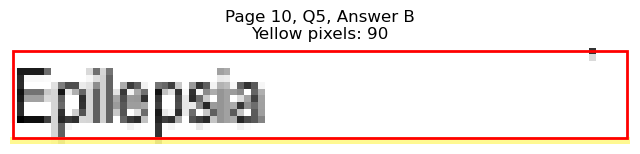

Page 10, Q5 - C: Detected box: x0=68.8, y0=518.6, x1=176.5, y1=531.2
Page 10, Q5, C: Yellow pixels: 1630
Page 10, Q5, C: Total non-white pixels: 2226
Page 10, Q5, C: Yellow percentage: 73.2%


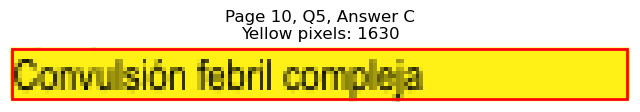

Page 10, Q5 - D: Detected box: x0=327.5, y0=493.4, x1=404.8, y1=506.0
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 398
Page 10, Q5, D: Yellow percentage: 0.0%


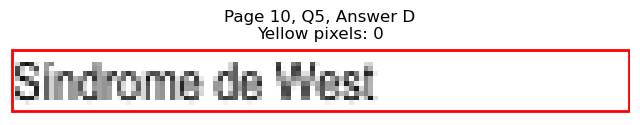

Page 10, Q5 - E: Detected box: x0=327.0, y0=506.0, x1=372.7, y1=518.6
Page 10, Q5, E: Yellow pixels: 0
Page 10, Q5, E: Total non-white pixels: 225
Page 10, Q5, E: Yellow percentage: 0.0%


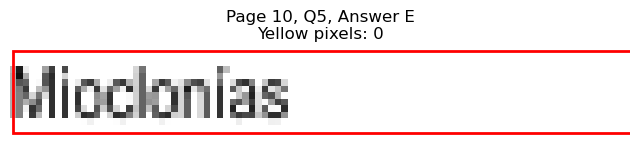


Page 10, Q5 - Selected Answer: C (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=569.1, x1=306.5, y1=581.8
Page 10, Q6, A: Yellow pixels: 1
Page 10, Q6, A: Total non-white pixels: 1415
Page 10, Q6, A: Yellow percentage: 0.1%


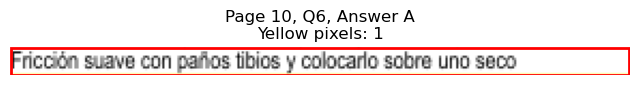

Page 10, Q6 - B: Detected box: x0=68.3, y0=581.7, x1=216.9, y1=594.4
Page 10, Q6, B: Yellow pixels: 1829
Page 10, Q6, B: Total non-white pixels: 2786
Page 10, Q6, B: Yellow percentage: 65.6%


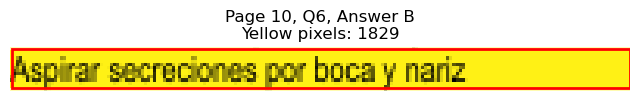

Page 10, Q6 - C: Detected box: x0=68.8, y0=594.3, x1=224.3, y1=607.0
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 978
Page 10, Q6, C: Yellow percentage: 0.0%


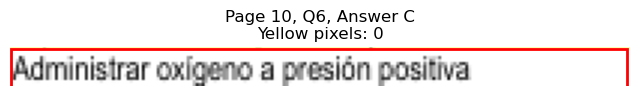

Page 10, Q6 - D: Detected box: x0=68.8, y0=606.9, x1=197.7, y1=619.6
Page 10, Q6, D: Yellow pixels: 0
Page 10, Q6, D: Total non-white pixels: 646
Page 10, Q6, D: Yellow percentage: 0.0%


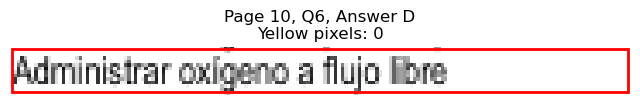

Page 10, Q6 - E: Detected box: x0=68.3, y0=619.6, x1=207.8, y1=632.3
Page 10, Q6, E: Yellow pixels: 0
Page 10, Q6, E: Total non-white pixels: 669
Page 10, Q6, E: Yellow percentage: 0.0%


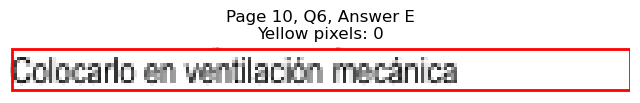


Page 10, Q6 - Selected Answer: B (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=682.7, x1=202.7, y1=695.3
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 672
Page 10, Q7, A: Yellow percentage: 0.0%


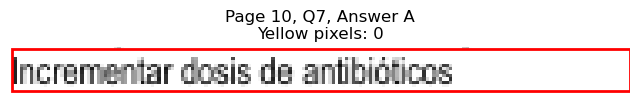

Page 10, Q7 - B: Detected box: x0=107.0, y0=695.4, x1=177.7, y1=708.0
Page 10, Q7, B: Yellow pixels: 1236
Page 10, Q7, B: Total non-white pixels: 1694
Page 10, Q7, B: Yellow percentage: 73.0%


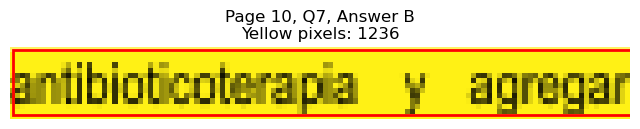

Page 10, Q7 - C: Detected box: x0=68.8, y0=720.6, x1=282.4, y1=733.2
Page 10, Q7, C: Yellow pixels: 211
Page 10, Q7, C: Total non-white pixels: 1396
Page 10, Q7, C: Yellow percentage: 15.1%


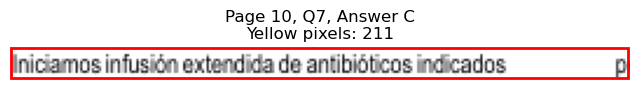

Page 10, Q7 - D: Detected box: x0=327.5, y0=682.7, x1=382.3, y1=695.3
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 522
Page 10, Q7, D: Yellow percentage: 0.0%


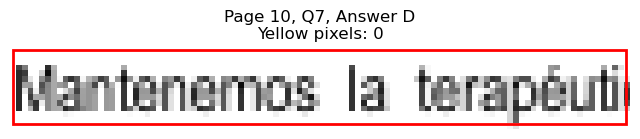

Page 10, Q7 - E: Detected box: x0=327.0, y0=708.0, x1=541.0, y1=720.6
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 1072
Page 10, Q7, E: Yellow percentage: 0.0%


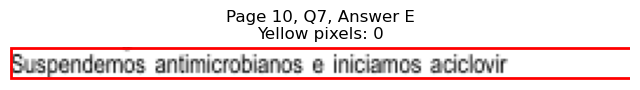


Page 10, Q7 - Selected Answer: B (based on yellow pixel count)





Page 11: Found 8 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=153.0, y1=139.9
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 426
Page 11, Q1, A: Yellow percentage: 0.0%


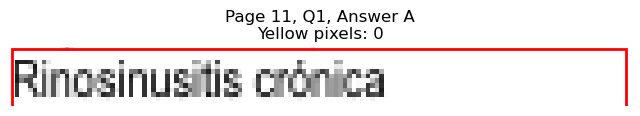

Page 11, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=129.5, y1=152.6
Page 11, Q1, B: Yellow pixels: 0
Page 11, Q1, B: Total non-white pixels: 320
Page 11, Q1, B: Yellow percentage: 0.0%


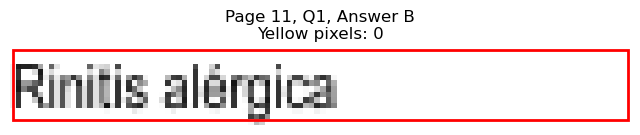

Page 11, Q1 - C: Detected box: x0=68.8, y0=152.5, x1=182.1, y1=165.2
Page 11, Q1, C: Yellow pixels: 0
Page 11, Q1, C: Total non-white pixels: 553
Page 11, Q1, C: Yellow percentage: 0.0%


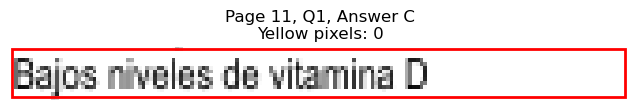

Page 11, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=399.8, y1=139.9
Page 11, Q1, D: Yellow pixels: 0
Page 11, Q1, D: Total non-white pixels: 367
Page 11, Q1, D: Yellow percentage: 0.0%


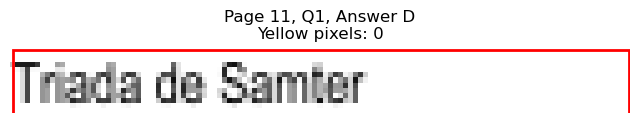

Page 11, Q1 - E: Detected box: x0=327.0, y0=139.9, x1=394.7, y1=152.6
Page 11, Q1, E: Yellow pixels: 1276
Page 11, Q1, E: Total non-white pixels: 1652
Page 11, Q1, E: Yellow percentage: 77.2%


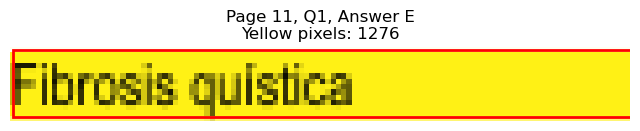


Page 11, Q1 - Selected Answer: E (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=248.0, y1=203.0
Page 11, Q2, A: Yellow pixels: 0
Page 11, Q2, A: Total non-white pixels: 845
Page 11, Q2, A: Yellow percentage: 0.0%


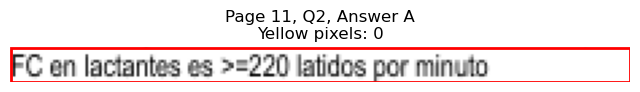

Page 11, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=233.3, y1=215.6
Page 11, Q2, B: Yellow pixels: 0
Page 11, Q2, B: Total non-white pixels: 750
Page 11, Q2, B: Yellow percentage: 0.0%


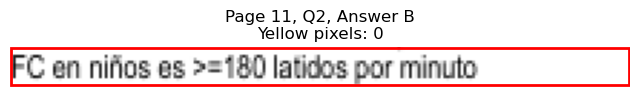

Page 11, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=152.2, y1=228.3
Page 11, Q2, C: Yellow pixels: 0
Page 11, Q2, C: Total non-white pixels: 424
Page 11, Q2, C: Yellow percentage: 0.0%


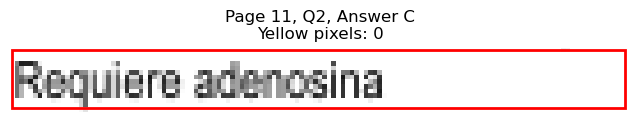

Page 11, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=454.0, y1=203.0
Page 11, Q2, D: Yellow pixels: 1839
Page 11, Q2, D: Total non-white pixels: 2314
Page 11, Q2, D: Yellow percentage: 79.5%


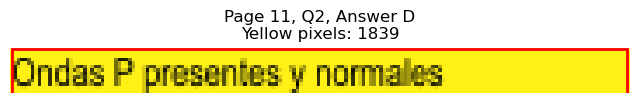

Page 11, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=488.1, y1=215.6
Page 11, Q2, E: Yellow pixels: 208
Page 11, Q2, E: Total non-white pixels: 1000
Page 11, Q2, E: Yellow percentage: 20.8%


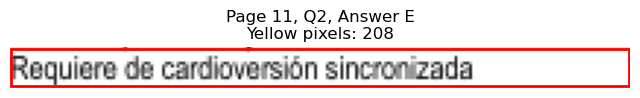


Page 11, Q2 - Selected Answer: D (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=118.9, y1=278.7
Page 11, Q3, A: Yellow pixels: 0
Page 11, Q3, A: Total non-white pixels: 261
Page 11, Q3, A: Yellow percentage: 0.0%


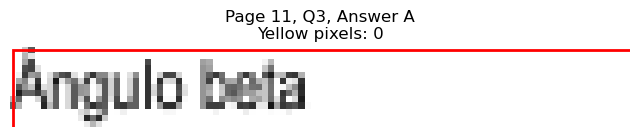

Page 11, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=115.9, y1=291.5
Page 11, Q3, B: Yellow pixels: 1075
Page 11, Q3, B: Total non-white pixels: 1372
Page 11, Q3, B: Yellow percentage: 78.4%


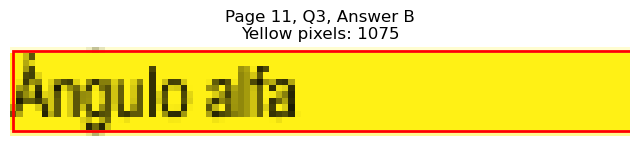

Page 11, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=186.1, y1=304.1
Page 11, Q3, C: Yellow pixels: 168
Page 11, Q3, C: Total non-white pixels: 770
Page 11, Q3, C: Yellow percentage: 21.8%


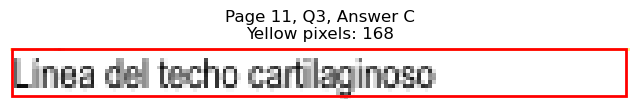

Page 11, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=393.8, y1=278.7
Page 11, Q3, D: Yellow pixels: 0
Page 11, Q3, D: Total non-white pixels: 326
Page 11, Q3, D: Yellow percentage: 0.0%


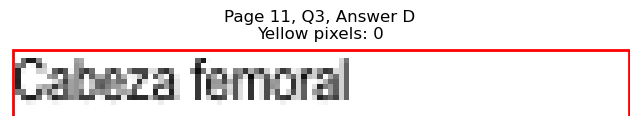

Page 11, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=397.3, y1=291.5
Page 11, Q3, E: Yellow pixels: 0
Page 11, Q3, E: Total non-white pixels: 365
Page 11, Q3, E: Yellow percentage: 0.0%


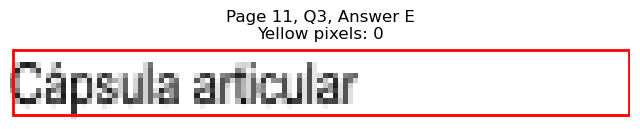


Page 11, Q3 - Selected Answer: B (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=178.6, y1=341.9
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 525
Page 11, Q4, A: Yellow percentage: 0.0%


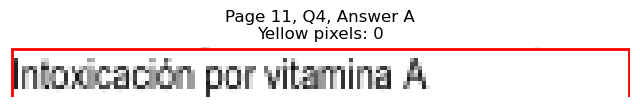

Page 11, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=126.0, y1=354.6
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 297
Page 11, Q4, B: Yellow percentage: 0.0%


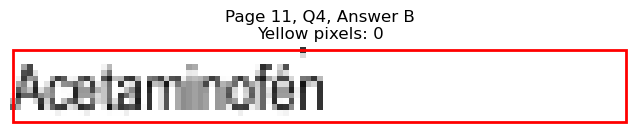

Page 11, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=131.4, y1=367.2
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 353
Page 11, Q4, C: Yellow percentage: 0.0%


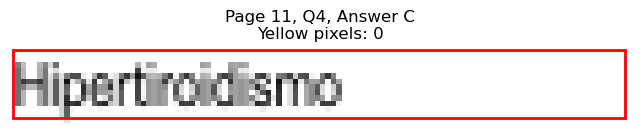

Page 11, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=410.8, y1=341.9
Page 11, Q4, D: Yellow pixels: 0
Page 11, Q4, D: Total non-white pixels: 398
Page 11, Q4, D: Yellow percentage: 0.0%


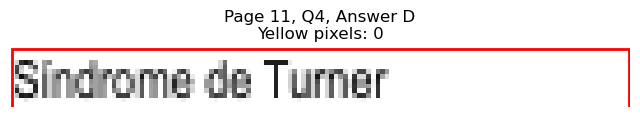

Page 11, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=443.9, y1=354.6
Page 11, Q4, E: Yellow pixels: 1705
Page 11, Q4, E: Total non-white pixels: 2338
Page 11, Q4, E: Yellow percentage: 72.9%


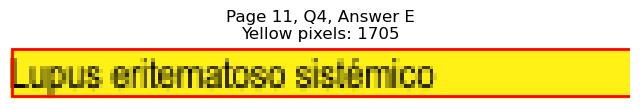


Page 11, Q4 - Selected Answer: E (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=104.4, y1=442.9
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 197
Page 11, Q5, A: Yellow percentage: 0.0%


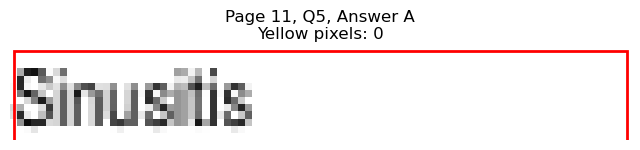

Page 11, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=175.1, y1=455.5
Page 11, Q5, B: Yellow pixels: 0
Page 11, Q5, B: Total non-white pixels: 526
Page 11, Q5, B: Yellow percentage: 0.0%


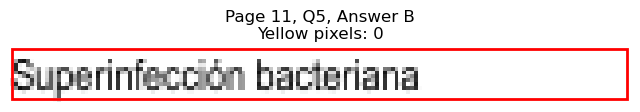

Page 11, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=130.0, y1=468.1
Page 11, Q5, C: Yellow pixels: 0
Page 11, Q5, C: Total non-white pixels: 342
Page 11, Q5, C: Yellow percentage: 0.0%


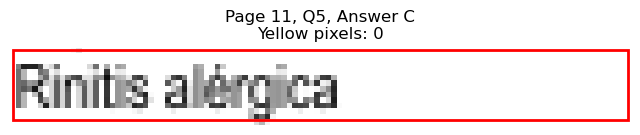

Page 11, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=388.7, y1=442.9
Page 11, Q5, D: Yellow pixels: 1226
Page 11, Q5, D: Total non-white pixels: 1456
Page 11, Q5, D: Yellow percentage: 84.2%


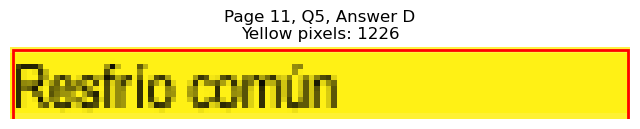

Page 11, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=391.7, y1=455.5
Page 11, Q5, E: Yellow pixels: 115
Page 11, Q5, E: Total non-white pixels: 422
Page 11, Q5, E: Yellow percentage: 27.3%


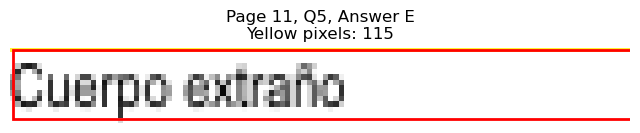


Page 11, Q5 - Selected Answer: D (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=130.0, y1=531.2
Page 11, Q6, A: Yellow pixels: 0
Page 11, Q6, A: Total non-white pixels: 291
Page 11, Q6, A: Yellow percentage: 0.0%


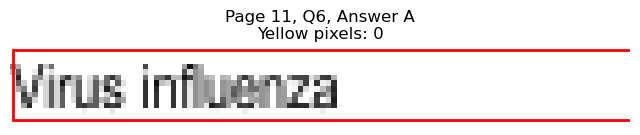

Page 11, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=115.9, y1=543.8
Page 11, Q6, B: Yellow pixels: 0
Page 11, Q6, B: Total non-white pixels: 248
Page 11, Q6, B: Yellow percentage: 0.0%


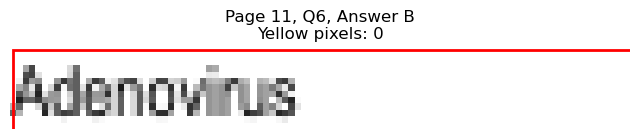

Page 11, Q6 - C: Detected box: x0=68.8, y0=543.8, x1=134.5, y1=556.4
Page 11, Q6, C: Yellow pixels: 0
Page 11, Q6, C: Total non-white pixels: 299
Page 11, Q6, C: Yellow percentage: 0.0%


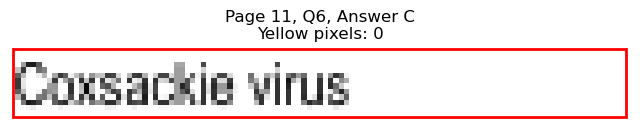

Page 11, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=407.3, y1=531.2
Page 11, Q6, D: Yellow pixels: 1405
Page 11, Q6, D: Total non-white pixels: 1834
Page 11, Q6, D: Yellow percentage: 76.6%


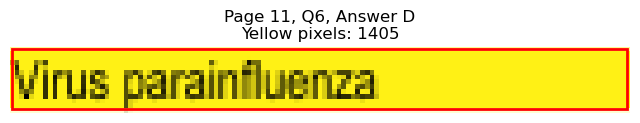

Page 11, Q6 - E: Detected box: x0=327.0, y0=531.2, x1=429.9, y1=543.8
Page 11, Q6, E: Yellow pixels: 0
Page 11, Q6, E: Total non-white pixels: 693
Page 11, Q6, E: Yellow percentage: 0.0%


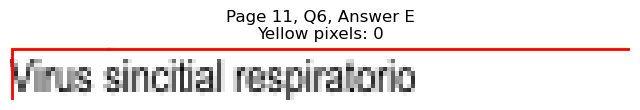


Page 11, Q6 - Selected Answer: D (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=68.3, y0=581.7, x1=257.0, y1=594.4
Page 11, Q7, A: Yellow pixels: 0
Page 11, Q7, A: Total non-white pixels: 952
Page 11, Q7, A: Yellow percentage: 0.0%


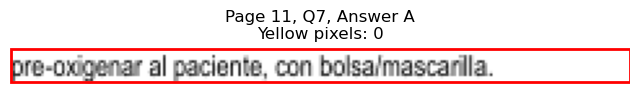

Page 11, Q7 - B: Detected box: x0=68.3, y0=594.3, x1=284.9, y1=607.0
Page 11, Q7, B: Yellow pixels: 0
Page 11, Q7, B: Total non-white pixels: 1306
Page 11, Q7, B: Yellow percentage: 0.0%


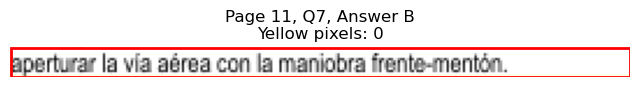

Page 11, Q7 - C: Detected box: x0=68.8, y0=606.9, x1=304.5, y1=619.6
Page 11, Q7, C: Yellow pixels: 2828
Page 11, Q7, C: Total non-white pixels: 4018
Page 11, Q7, C: Yellow percentage: 70.4%


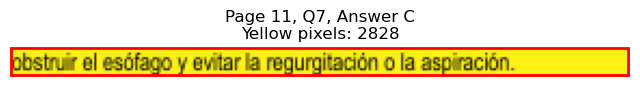

Page 11, Q7 - D: Detected box: x0=68.8, y0=619.6, x1=290.4, y1=632.3
Page 11, Q7, D: Yellow pixels: 267
Page 11, Q7, D: Total non-white pixels: 1337
Page 11, Q7, D: Yellow percentage: 20.0%


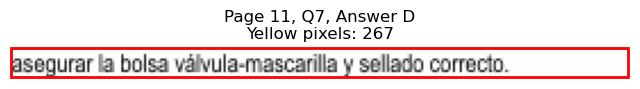

Page 11, Q7 - E: Detected box: x0=68.3, y0=632.2, x1=345.2, y1=644.9
Page 11, Q7, E: Yellow pixels: 0
Page 11, Q7, E: Total non-white pixels: 1350
Page 11, Q7, E: Yellow percentage: 0.0%


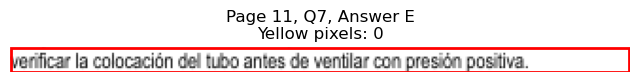


Page 11, Q7 - Selected Answer: C (based on yellow pixel count)




Page 11, Q8 - A: Detected box: x0=68.3, y0=708.0, x1=179.2, y1=720.6
Page 11, Q8, A: Yellow pixels: 162
Page 11, Q8, A: Total non-white pixels: 756
Page 11, Q8, A: Yellow percentage: 21.4%


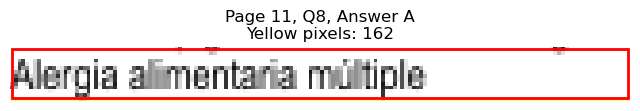

Page 11, Q8 - B: Detected box: x0=68.3, y0=720.6, x1=196.7, y1=733.2
Page 11, Q8, B: Yellow pixels: 1769
Page 11, Q8, B: Total non-white pixels: 2506
Page 11, Q8, B: Yellow percentage: 70.6%


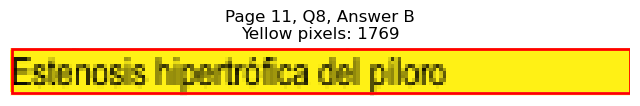

Page 11, Q8 - C: Detected box: x0=68.8, y0=733.2, x1=187.7, y1=745.8
Page 11, Q8, C: Yellow pixels: 0
Page 11, Q8, C: Total non-white pixels: 720
Page 11, Q8, C: Yellow percentage: 0.0%


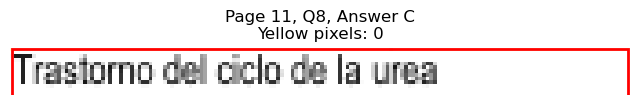

Page 11, Q8 - D: Detected box: x0=327.5, y0=708.0, x1=404.2, y1=720.6
Page 11, Q8, D: Yellow pixels: 0
Page 11, Q8, D: Total non-white pixels: 412
Page 11, Q8, D: Yellow percentage: 0.0%


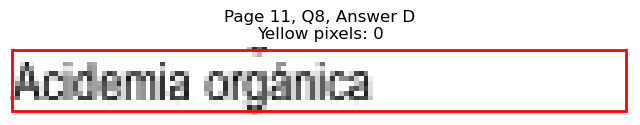

Page 11, Q8 - E: Detected box: x0=327.0, y0=720.6, x1=415.9, y1=733.2
Page 11, Q8, E: Yellow pixels: 0
Page 11, Q8, E: Total non-white pixels: 484
Page 11, Q8, E: Yellow percentage: 0.0%


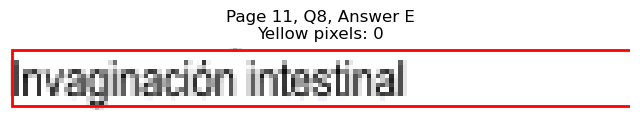


Page 11, Q8 - Selected Answer: B (based on yellow pixel count)





Page 12: Found 8 questions
Page 12, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=147.0, y1=114.7
Page 12, Q1, A: Yellow pixels: 0
Page 12, Q1, A: Total non-white pixels: 437
Page 12, Q1, A: Yellow percentage: 0.0%


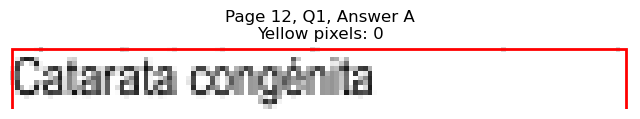

Page 12, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=129.0, y1=127.3
Page 12, Q1, B: Yellow pixels: 0
Page 12, Q1, B: Total non-white pixels: 263
Page 12, Q1, B: Yellow percentage: 0.0%


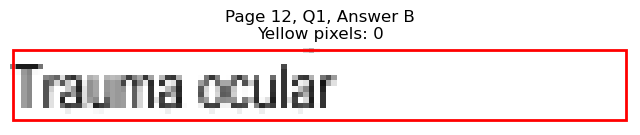

Page 12, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=145.0, y1=139.9
Page 12, Q1, C: Yellow pixels: 0
Page 12, Q1, C: Total non-white pixels: 371
Page 12, Q1, C: Yellow percentage: 0.0%


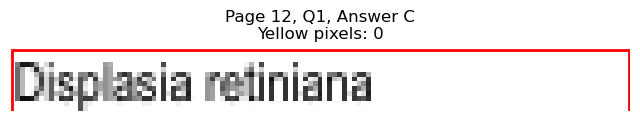

Page 12, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=430.4, y1=114.7
Page 12, Q1, D: Yellow pixels: 1
Page 12, Q1, D: Total non-white pixels: 637
Page 12, Q1, D: Yellow percentage: 0.2%


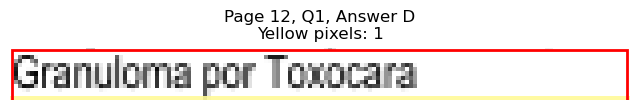

Page 12, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=392.2, y1=127.3
Page 12, Q1, E: Yellow pixels: 1106
Page 12, Q1, E: Total non-white pixels: 1624
Page 12, Q1, E: Yellow percentage: 68.1%


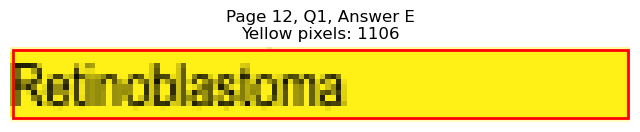


Page 12, Q1 - Selected Answer: E (based on yellow pixel count)




Page 12, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=159.0, y1=190.4
Page 12, Q2, A: Yellow pixels: 1348
Page 12, Q2, A: Total non-white pixels: 1988
Page 12, Q2, A: Yellow percentage: 67.8%


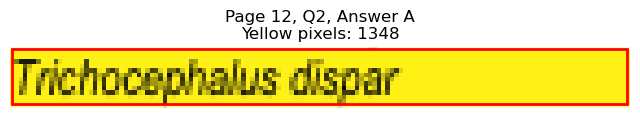

Page 12, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=167.1, y1=203.0
Page 12, Q2, B: Yellow pixels: 2
Page 12, Q2, B: Total non-white pixels: 629
Page 12, Q2, B: Yellow percentage: 0.3%


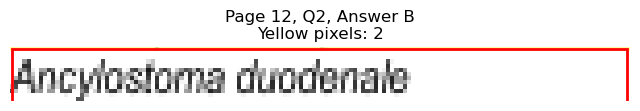

Page 12, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=131.4, y1=215.6
Page 12, Q2, C: Yellow pixels: 0
Page 12, Q2, C: Total non-white pixels: 334
Page 12, Q2, C: Yellow percentage: 0.0%


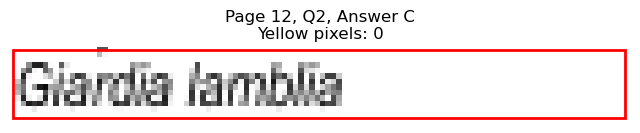

Page 12, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=412.7, y1=190.4
Page 12, Q2, D: Yellow pixels: 0
Page 12, Q2, D: Total non-white pixels: 429
Page 12, Q2, D: Yellow percentage: 0.0%


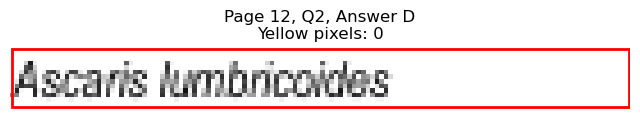

Page 12, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=427.9, y1=203.0
Page 12, Q2, E: Yellow pixels: 0
Page 12, Q2, E: Total non-white pixels: 530
Page 12, Q2, E: Yellow percentage: 0.0%


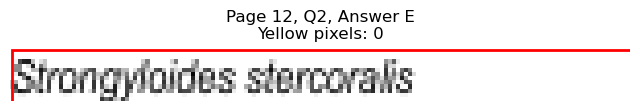


Page 12, Q2 - Selected Answer: A (based on yellow pixel count)




Page 12, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=136.5, y1=253.5
Page 12, Q3, A: Yellow pixels: 0
Page 12, Q3, A: Total non-white pixels: 355
Page 12, Q3, A: Yellow percentage: 0.0%


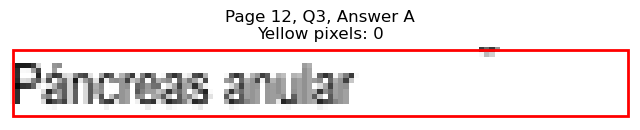

Page 12, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=124.0, y1=266.1
Page 12, Q3, B: Yellow pixels: 0
Page 12, Q3, B: Total non-white pixels: 249
Page 12, Q3, B: Yellow percentage: 0.0%


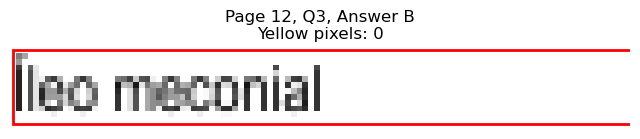

Page 12, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=188.7, y1=278.7
Page 12, Q3, C: Yellow pixels: 0
Page 12, Q3, C: Total non-white pixels: 607
Page 12, Q3, C: Yellow percentage: 0.0%


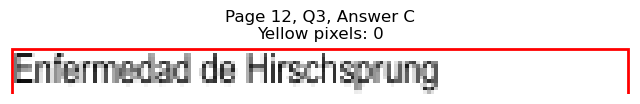

Page 12, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=416.3, y1=253.5
Page 12, Q3, D: Yellow pixels: 140
Page 12, Q3, D: Total non-white pixels: 602
Page 12, Q3, D: Yellow percentage: 23.3%


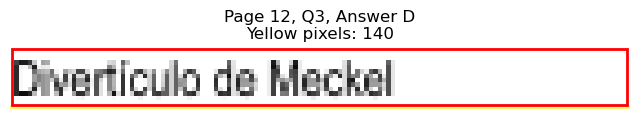

Page 12, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=363.7, y1=266.1
Page 12, Q3, E: Yellow pixels: 987
Page 12, Q3, E: Total non-white pixels: 1218
Page 12, Q3, E: Yellow percentage: 81.0%


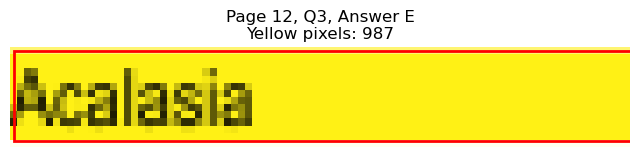


Page 12, Q3 - Selected Answer: E (based on yellow pixel count)




Page 12, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=142.1, y1=341.9
Page 12, Q4, A: Yellow pixels: 0
Page 12, Q4, A: Total non-white pixels: 368
Page 12, Q4, A: Yellow percentage: 0.0%


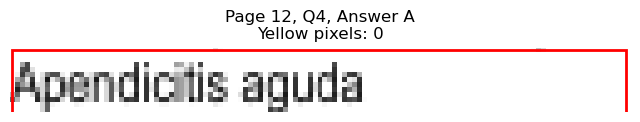

Page 12, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=176.2, y1=354.6
Page 12, Q4, B: Yellow pixels: 0
Page 12, Q4, B: Total non-white pixels: 530
Page 12, Q4, B: Yellow percentage: 0.0%


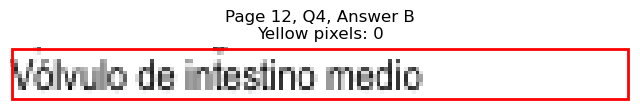

Page 12, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=124.6, y1=367.2
Page 12, Q4, C: Yellow pixels: 0
Page 12, Q4, C: Total non-white pixels: 288
Page 12, Q4, C: Yellow percentage: 0.0%


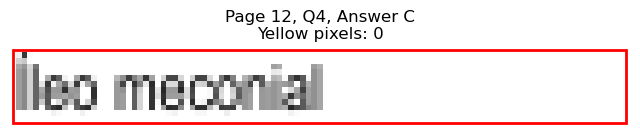

Page 12, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=390.3, y1=341.9
Page 12, Q4, D: Yellow pixels: 1231
Page 12, Q4, D: Total non-white pixels: 1482
Page 12, Q4, D: Yellow percentage: 83.1%


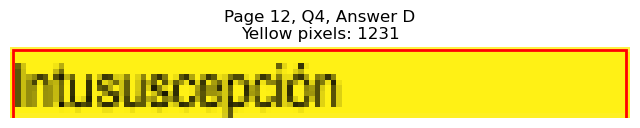

Page 12, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=445.0, y1=354.6
Page 12, Q4, E: Yellow pixels: 167
Page 12, Q4, E: Total non-white pixels: 720
Page 12, Q4, E: Yellow percentage: 23.2%


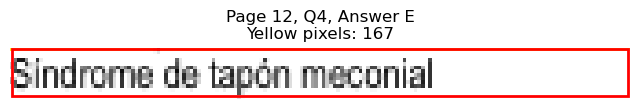


Page 12, Q4 - Selected Answer: D (based on yellow pixel count)




Page 12, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=124.5, y1=442.9
Page 12, Q5, A: Yellow pixels: 0
Page 12, Q5, A: Total non-white pixels: 275
Page 12, Q5, A: Yellow percentage: 0.0%


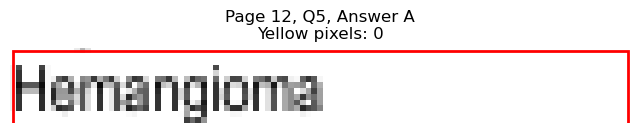

Page 12, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=205.7, y1=455.5
Page 12, Q5, B: Yellow pixels: 188
Page 12, Q5, B: Total non-white pixels: 844
Page 12, Q5, B: Yellow percentage: 22.3%


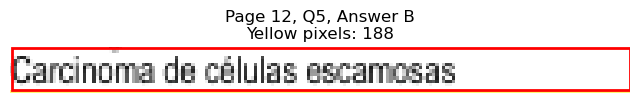

Page 12, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=144.5, y1=468.1
Page 12, Q5, C: Yellow pixels: 1321
Page 12, Q5, C: Total non-white pixels: 1778
Page 12, Q5, C: Yellow percentage: 74.3%


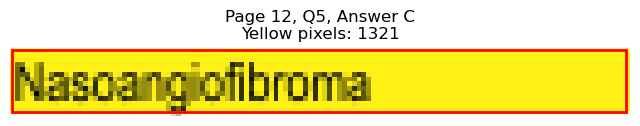

Page 12, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=409.7, y1=442.9
Page 12, Q5, D: Yellow pixels: 0
Page 12, Q5, D: Total non-white pixels: 416
Page 12, Q5, D: Yellow percentage: 0.0%


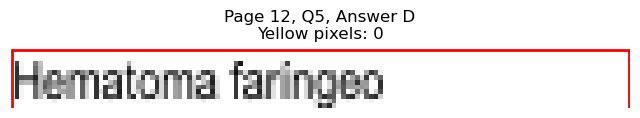

Page 12, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=361.6, y1=455.5
Page 12, Q5, E: Yellow pixels: 0
Page 12, Q5, E: Total non-white pixels: 167
Page 12, Q5, E: Yellow percentage: 0.0%


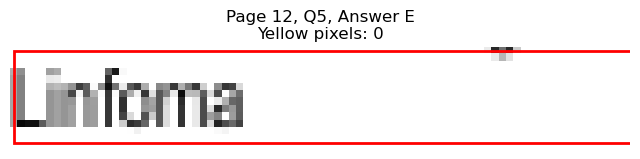


Page 12, Q5 - Selected Answer: C (based on yellow pixel count)




Page 12, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=254.0, y1=518.6
Page 12, Q6, A: Yellow pixels: 0
Page 12, Q6, A: Total non-white pixels: 975
Page 12, Q6, A: Yellow percentage: 0.0%


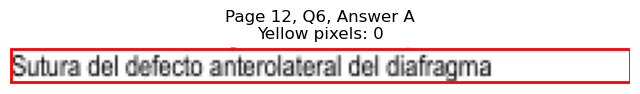

Page 12, Q6 - B: Detected box: x0=68.3, y0=518.6, x1=184.7, y1=531.2
Page 12, Q6, B: Yellow pixels: 0
Page 12, Q6, B: Total non-white pixels: 578
Page 12, Q6, B: Yellow percentage: 0.0%


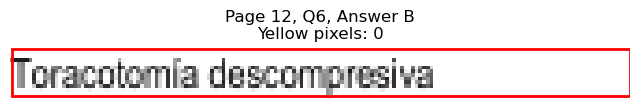

Page 12, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=174.1, y1=543.8
Page 12, Q6, C: Yellow pixels: 0
Page 12, Q6, C: Total non-white pixels: 558
Page 12, Q6, C: Yellow percentage: 0.0%


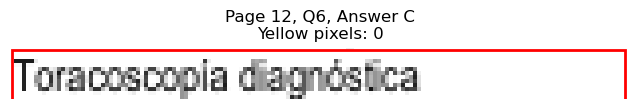

Page 12, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=515.6, y1=518.6
Page 12, Q6, D: Yellow pixels: 2012
Page 12, Q6, D: Total non-white pixels: 2995
Page 12, Q6, D: Yellow percentage: 67.2%


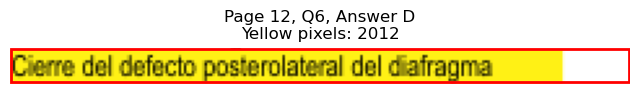

Page 12, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=432.5, y1=531.2
Page 12, Q6, E: Yellow pixels: 156
Page 12, Q6, E: Total non-white pixels: 709
Page 12, Q6, E: Yellow percentage: 22.0%


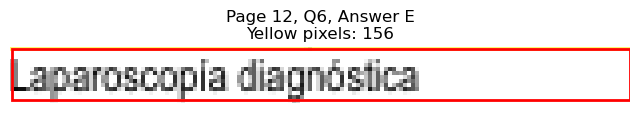


Page 12, Q6 - Selected Answer: D (based on yellow pixel count)




Page 12, Q7 - A: Detected box: x0=68.3, y0=594.3, x1=167.1, y1=607.0
Page 12, Q7, A: Yellow pixels: 0
Page 12, Q7, A: Total non-white pixels: 687
Page 12, Q7, A: Yellow percentage: 0.0%


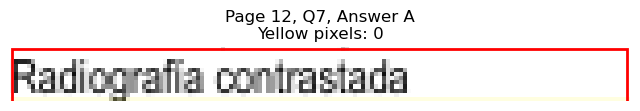

Page 12, Q7 - B: Detected box: x0=68.3, y0=606.9, x1=153.6, y1=619.6
Page 12, Q7, B: Yellow pixels: 1405
Page 12, Q7, B: Total non-white pixels: 1904
Page 12, Q7, B: Yellow percentage: 73.8%


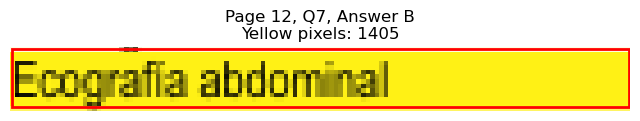

Page 12, Q7 - C: Detected box: x0=68.8, y0=619.6, x1=170.7, y1=632.3
Page 12, Q7, C: Yellow pixels: 152
Page 12, Q7, C: Total non-white pixels: 668
Page 12, Q7, C: Yellow percentage: 22.8%


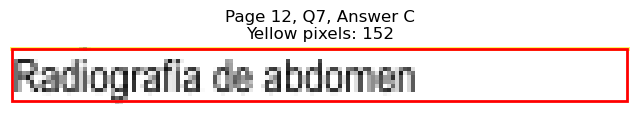

Page 12, Q7 - D: Detected box: x0=327.5, y0=594.3, x1=428.8, y1=607.0
Page 12, Q7, D: Yellow pixels: 0
Page 12, Q7, D: Total non-white pixels: 500
Page 12, Q7, D: Yellow percentage: 0.0%


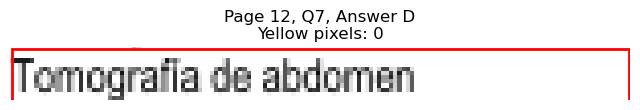

Page 12, Q7 - E: Detected box: x0=327.0, y0=606.9, x1=421.4, y1=619.6
Page 12, Q7, E: Yellow pixels: 0
Page 12, Q7, E: Total non-white pixels: 516
Page 12, Q7, E: Yellow percentage: 0.0%


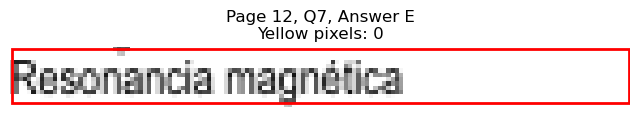


Page 12, Q7 - Selected Answer: B (based on yellow pixel count)




Page 12, Q8 - A: Detected box: x0=56.6, y0=695.4, x1=65.2, y1=708.0
Page 12, Q8, A: Yellow pixels: 0
Page 12, Q8, A: Total non-white pixels: 53
Page 12, Q8, A: Yellow percentage: 0.0%


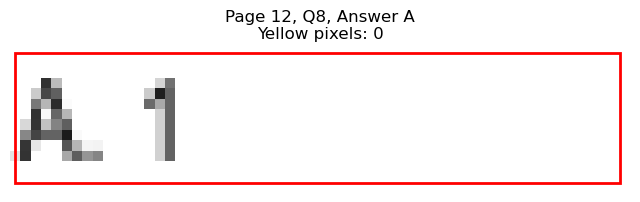

Page 12, Q8 - B: Detected box: x0=56.6, y0=708.0, x1=65.2, y1=720.6
Page 12, Q8, B: Yellow pixels: 0
Page 12, Q8, B: Total non-white pixels: 69
Page 12, Q8, B: Yellow percentage: 0.0%


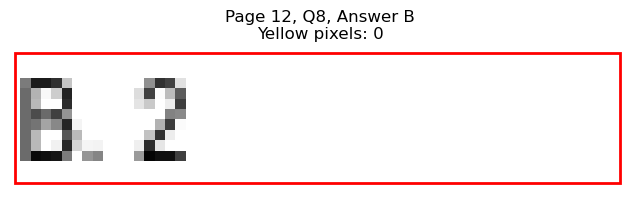

Page 12, Q8 - C: Detected box: x0=56.6, y0=720.6, x1=65.6, y1=733.2
Page 12, Q8, C: Yellow pixels: 0
Page 12, Q8, C: Total non-white pixels: 70
Page 12, Q8, C: Yellow percentage: 0.0%


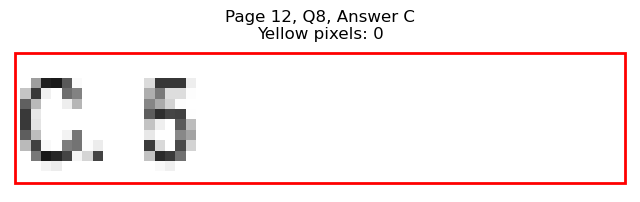

Page 12, Q8 - D: Detected box: x0=315.4, y0=695.4, x1=324.4, y1=708.0
Page 12, Q8, D: Yellow pixels: 731
Page 12, Q8, D: Total non-white pixels: 780
Page 12, Q8, D: Yellow percentage: 93.7%


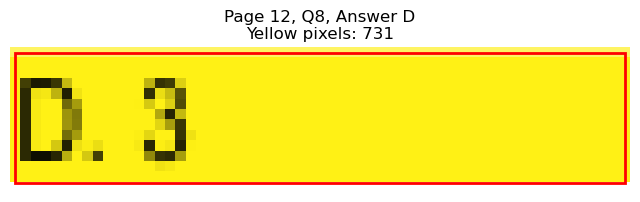

Page 12, Q8 - E: Detected box: x0=315.4, y0=708.0, x1=323.9, y1=720.6
Page 12, Q8, E: Yellow pixels: 59
Page 12, Q8, E: Total non-white pixels: 130
Page 12, Q8, E: Yellow percentage: 45.4%


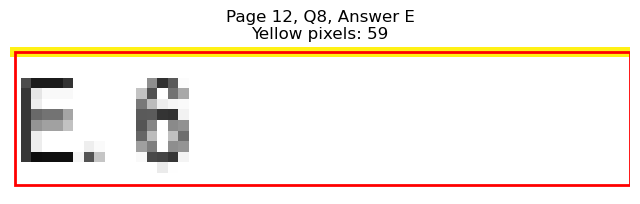


Page 12, Q8 - Selected Answer: D (based on yellow pixel count)





Page 13: Found 8 questions
Page 13, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=109.5, y1=114.7
Page 13, Q1, A: Yellow pixels: 0
Page 13, Q1, A: Total non-white pixels: 224
Page 13, Q1, A: Yellow percentage: 0.0%


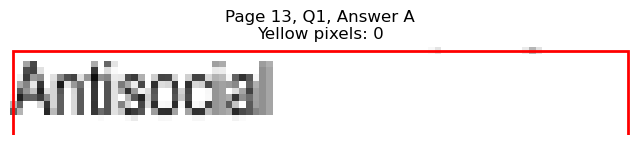

Page 13, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=126.0, y1=127.3
Page 13, Q1, B: Yellow pixels: 109
Page 13, Q1, B: Total non-white pixels: 370
Page 13, Q1, B: Yellow percentage: 29.5%


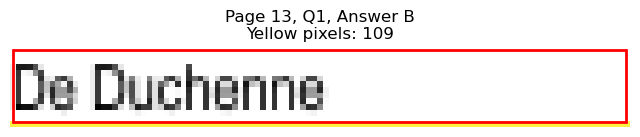

Page 13, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=128.4, y1=139.9
Page 13, Q1, C: Yellow pixels: 1216
Page 13, Q1, C: Total non-white pixels: 1443
Page 13, Q1, C: Yellow percentage: 84.3%


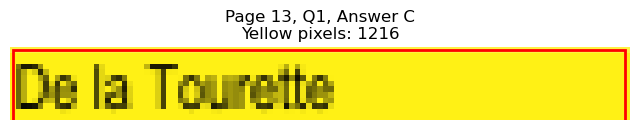

Page 13, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=413.3, y1=114.7
Page 13, Q1, D: Yellow pixels: 0
Page 13, Q1, D: Total non-white pixels: 436
Page 13, Q1, D: Yellow percentage: 0.0%


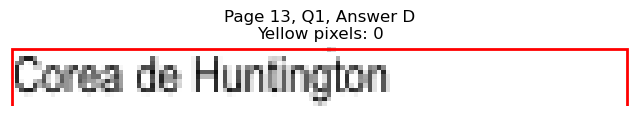

Page 13, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=370.7, y1=127.3
Page 13, Q1, E: Yellow pixels: 0
Page 13, Q1, E: Total non-white pixels: 244
Page 13, Q1, E: Yellow percentage: 0.0%


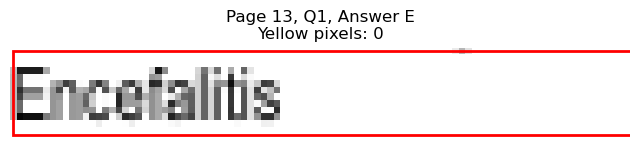


Page 13, Q1 - Selected Answer: C (based on yellow pixel count)




Page 13, Q2 - A: Detected box: x0=68.3, y0=215.7, x1=165.6, y1=228.3
Page 13, Q2, A: Yellow pixels: 0
Page 13, Q2, A: Total non-white pixels: 472
Page 13, Q2, A: Yellow percentage: 0.0%


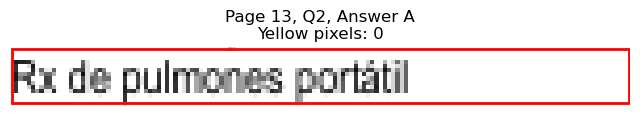

Page 13, Q2 - B: Detected box: x0=68.3, y0=228.3, x1=149.1, y1=240.9
Page 13, Q2, B: Yellow pixels: 0
Page 13, Q2, B: Total non-white pixels: 564
Page 13, Q2, B: Yellow percentage: 0.0%


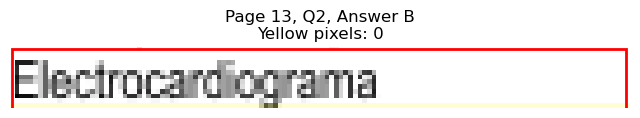

Page 13, Q2 - C: Detected box: x0=68.8, y0=240.9, x1=134.5, y1=253.5
Page 13, Q2, C: Yellow pixels: 1218
Page 13, Q2, C: Total non-white pixels: 1638
Page 13, Q2, C: Yellow percentage: 74.4%


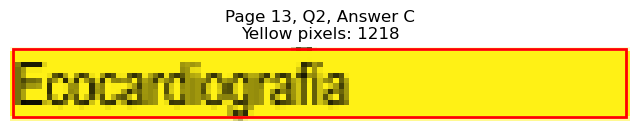

Page 13, Q2 - D: Detected box: x0=327.5, y0=215.7, x1=411.3, y1=228.3
Page 13, Q2, D: Yellow pixels: 0
Page 13, Q2, D: Total non-white pixels: 403
Page 13, Q2, D: Yellow percentage: 0.0%


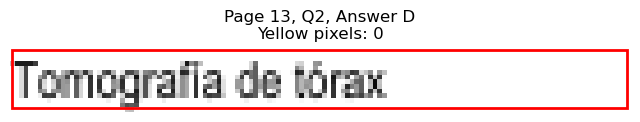

Page 13, Q2 - E: Detected box: x0=327.0, y0=228.3, x1=402.3, y1=240.9
Page 13, Q2, E: Yellow pixels: 0
Page 13, Q2, E: Total non-white pixels: 364
Page 13, Q2, E: Yellow percentage: 0.0%


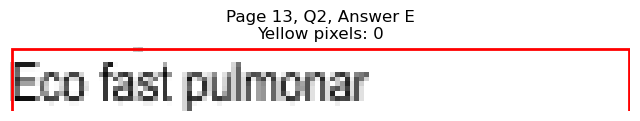


Page 13, Q2 - Selected Answer: C (based on yellow pixel count)




Page 13, Q3 - A: Detected box: x0=68.3, y0=291.4, x1=126.0, y1=304.1
Page 13, Q3, A: Yellow pixels: 0
Page 13, Q3, A: Total non-white pixels: 276
Page 13, Q3, A: Yellow percentage: 0.0%


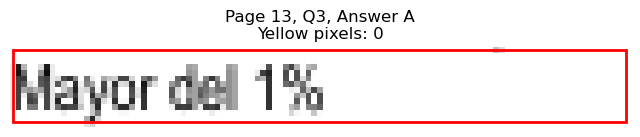

Page 13, Q3 - B: Detected box: x0=68.3, y0=304.0, x1=126.0, y1=316.7
Page 13, Q3, B: Yellow pixels: 0
Page 13, Q3, B: Total non-white pixels: 289
Page 13, Q3, B: Yellow percentage: 0.0%


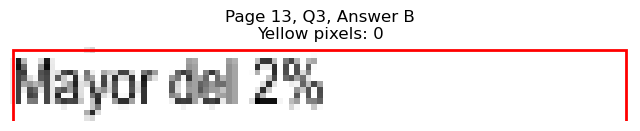

Page 13, Q3 - C: Detected box: x0=68.8, y0=316.6, x1=150.5, y1=329.3
Page 13, Q3, C: Yellow pixels: 0
Page 13, Q3, C: Total non-white pixels: 400
Page 13, Q3, C: Yellow percentage: 0.0%


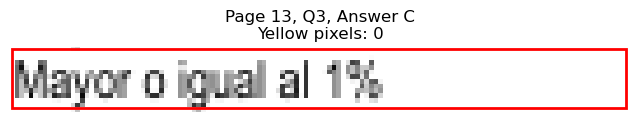

Page 13, Q3 - D: Detected box: x0=327.5, y0=291.4, x1=409.3, y1=304.1
Page 13, Q3, D: Yellow pixels: 1432
Page 13, Q3, D: Total non-white pixels: 1862
Page 13, Q3, D: Yellow percentage: 76.9%


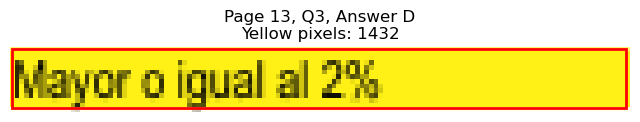

Page 13, Q3 - E: Detected box: x0=327.0, y0=304.0, x1=418.9, y1=316.7
Page 13, Q3, E: Yellow pixels: 0
Page 13, Q3, E: Total non-white pixels: 609
Page 13, Q3, E: Yellow percentage: 0.0%


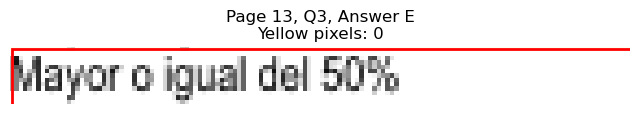


Page 13, Q3 - Selected Answer: D (based on yellow pixel count)




Page 13, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=156.0, y1=379.8
Page 13, Q4, A: Yellow pixels: 0
Page 13, Q4, A: Total non-white pixels: 425
Page 13, Q4, A: Yellow percentage: 0.0%


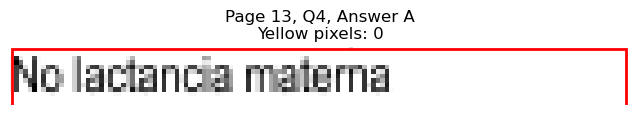

Page 13, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=192.1, y1=392.4
Page 13, Q4, B: Yellow pixels: 0
Page 13, Q4, B: Total non-white pixels: 632
Page 13, Q4, B: Yellow percentage: 0.0%


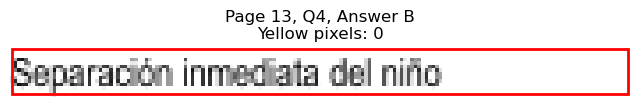

Page 13, Q4 - C: Detected box: x0=68.8, y0=392.3, x1=105.5, y1=405.0
Page 13, Q4, C: Yellow pixels: 0
Page 13, Q4, C: Total non-white pixels: 193
Page 13, Q4, C: Yellow percentage: 0.0%


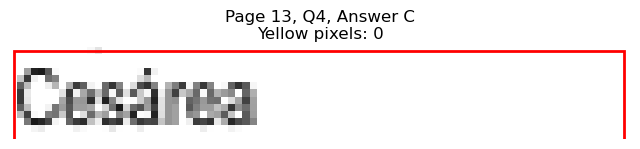

Page 13, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=494.5, y1=379.8
Page 13, Q4, D: Yellow pixels: 2125
Page 13, Q4, D: Total non-white pixels: 2782
Page 13, Q4, D: Yellow percentage: 76.4%


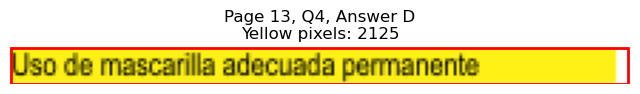

Page 13, Q4 - E: Detected box: x0=327.0, y0=379.7, x1=454.0, y1=392.4
Page 13, Q4, E: Yellow pixels: 178
Page 13, Q4, E: Total non-white pixels: 804
Page 13, Q4, E: Yellow percentage: 22.1%


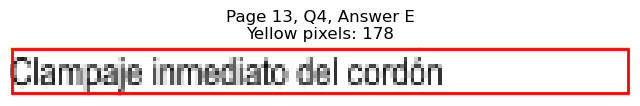


Page 13, Q4 - Selected Answer: D (based on yellow pixel count)




Page 13, Q5 - A: Detected box: x0=68.3, y0=455.5, x1=129.5, y1=468.1
Page 13, Q5, A: Yellow pixels: 0
Page 13, Q5, A: Total non-white pixels: 309
Page 13, Q5, A: Yellow percentage: 0.0%


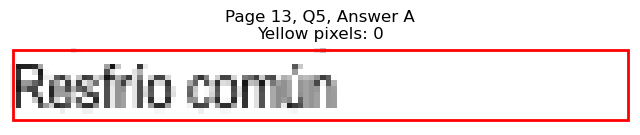

Page 13, Q5 - B: Detected box: x0=68.3, y0=468.1, x1=129.5, y1=480.7
Page 13, Q5, B: Yellow pixels: 0
Page 13, Q5, B: Total non-white pixels: 320
Page 13, Q5, B: Yellow percentage: 0.0%


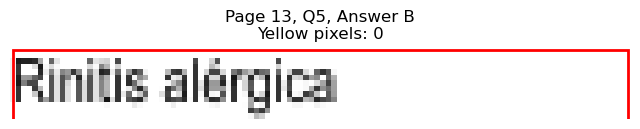

Page 13, Q5 - C: Detected box: x0=68.8, y0=480.8, x1=104.9, y1=493.4
Page 13, Q5, C: Yellow pixels: 910
Page 13, Q5, C: Total non-white pixels: 1218
Page 13, Q5, C: Yellow percentage: 74.7%


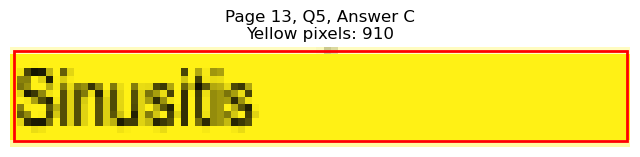

Page 13, Q5 - D: Detected box: x0=327.5, y0=455.5, x1=392.2, y1=468.1
Page 13, Q5, D: Yellow pixels: 0
Page 13, Q5, D: Total non-white pixels: 317
Page 13, Q5, D: Yellow percentage: 0.0%


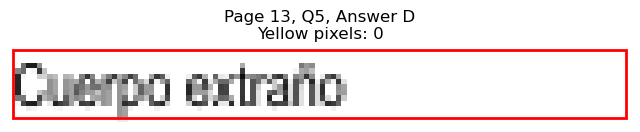

Page 13, Q5 - E: Detected box: x0=327.0, y0=468.1, x1=403.7, y1=480.7
Page 13, Q5, E: Yellow pixels: 0
Page 13, Q5, E: Total non-white pixels: 379
Page 13, Q5, E: Yellow percentage: 0.0%


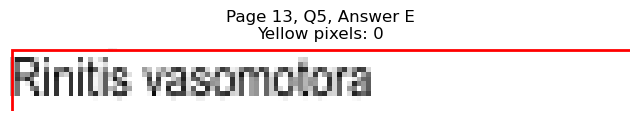


Page 13, Q5 - Selected Answer: C (based on yellow pixel count)




Page 13, Q6 - A: Detected box: x0=68.3, y0=531.2, x1=251.9, y1=543.8
Page 13, Q6, A: Yellow pixels: 0
Page 13, Q6, A: Total non-white pixels: 911
Page 13, Q6, A: Yellow percentage: 0.0%


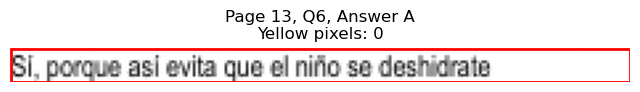

Page 13, Q6 - B: Detected box: x0=68.3, y0=543.8, x1=283.0, y1=556.4
Page 13, Q6, B: Yellow pixels: 0
Page 13, Q6, B: Total non-white pixels: 1069
Page 13, Q6, B: Yellow percentage: 0.0%


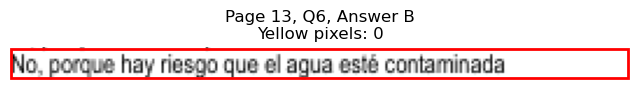

Page 13, Q6 - C: Detected box: x0=68.8, y0=556.5, x1=341.1, y1=569.2
Page 13, Q6, C: Yellow pixels: 0
Page 13, Q6, C: Total non-white pixels: 1373
Page 13, Q6, C: Yellow percentage: 0.0%


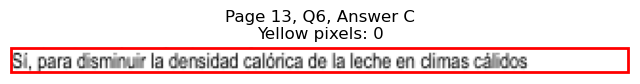

Page 13, Q6 - D: Detected box: x0=68.8, y0=569.1, x1=269.4, y1=581.8
Page 13, Q6, D: Yellow pixels: 1
Page 13, Q6, D: Total non-white pixels: 1240
Page 13, Q6, D: Yellow percentage: 0.1%


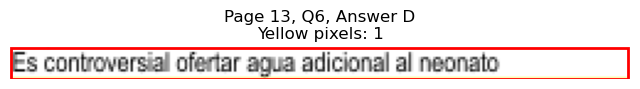

Page 13, Q6 - E: Detected box: x0=68.3, y0=581.7, x1=269.9, y1=594.4
Page 13, Q6, E: Yellow pixels: 2248
Page 13, Q6, E: Total non-white pixels: 3528
Page 13, Q6, E: Yellow percentage: 63.7%


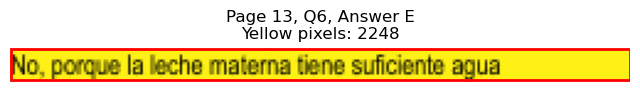


Page 13, Q6 - Selected Answer: E (based on yellow pixel count)




Page 13, Q7 - A: Detected box: x0=68.3, y0=632.2, x1=131.1, y1=644.9
Page 13, Q7, A: Yellow pixels: 0
Page 13, Q7, A: Total non-white pixels: 337
Page 13, Q7, A: Yellow percentage: 0.0%


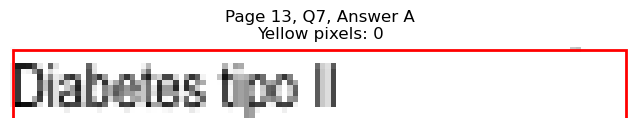

Page 13, Q7 - B: Detected box: x0=68.3, y0=644.9, x1=138.5, y1=657.5
Page 13, Q7, B: Yellow pixels: 0
Page 13, Q7, B: Total non-white pixels: 357
Page 13, Q7, B: Yellow percentage: 0.0%


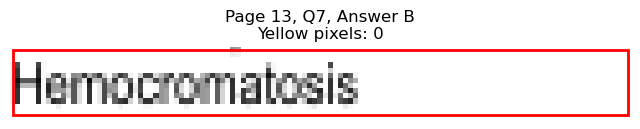

Page 13, Q7 - C: Detected box: x0=68.8, y0=657.5, x1=144.0, y1=670.1
Page 13, Q7, C: Yellow pixels: 0
Page 13, Q7, C: Total non-white pixels: 367
Page 13, Q7, C: Yellow percentage: 0.0%


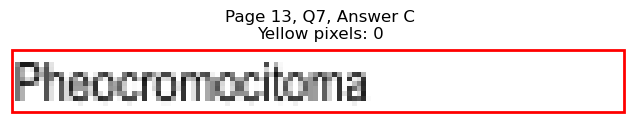

Page 13, Q7 - D: Detected box: x0=327.5, y0=632.2, x1=387.8, y1=644.9
Page 13, Q7, D: Yellow pixels: 1185
Page 13, Q7, D: Total non-white pixels: 1443
Page 13, Q7, D: Yellow percentage: 82.1%


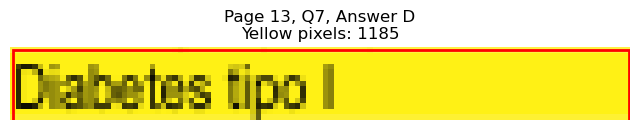

Page 13, Q7 - E: Detected box: x0=327.0, y0=644.9, x1=416.8, y1=657.5
Page 13, Q7, E: Yellow pixels: 0
Page 13, Q7, E: Total non-white pixels: 424
Page 13, Q7, E: Yellow percentage: 0.0%


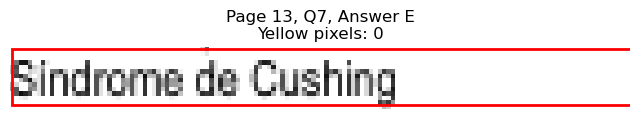


Page 13, Q7 - Selected Answer: D (based on yellow pixel count)




Page 13, Q8 - A: Detected box: x0=68.3, y0=720.6, x1=139.6, y1=733.2
Page 13, Q8, A: Yellow pixels: 0
Page 13, Q8, A: Total non-white pixels: 354
Page 13, Q8, A: Yellow percentage: 0.0%


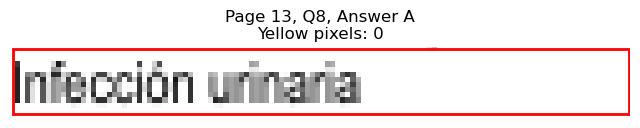

Page 13, Q8 - B: Detected box: x0=68.3, y0=733.2, x1=136.5, y1=745.8
Page 13, Q8, B: Yellow pixels: 0
Page 13, Q8, B: Total non-white pixels: 319
Page 13, Q8, B: Yellow percentage: 0.0%


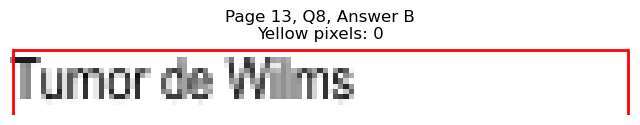

Page 13, Q8 - C: Detected box: x0=68.8, y0=745.8, x1=104.4, y1=758.4
Page 13, Q8, C: Yellow pixels: 0
Page 13, Q8, C: Total non-white pixels: 195
Page 13, Q8, C: Yellow percentage: 0.0%


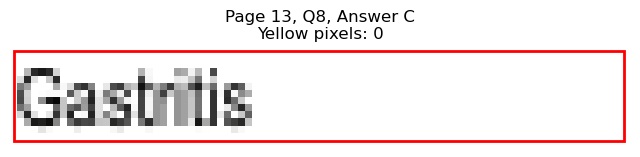

Page 13, Q8 - D: Detected box: x0=68.8, y0=758.5, x1=115.0, y1=771.2
Page 13, Q8, D: Yellow pixels: 0
Page 13, Q8, D: Total non-white pixels: 253
Page 13, Q8, D: Yellow percentage: 0.0%


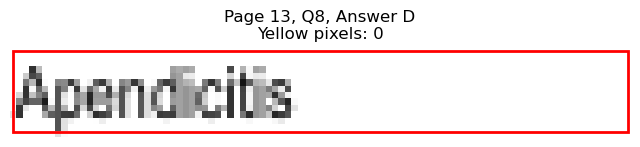

Page 13, Q8 - E: Detected box: x0=327.0, y0=720.6, x1=366.2, y1=733.2
Page 13, Q8, E: Yellow pixels: 1010
Page 13, Q8, E: Total non-white pixels: 1260
Page 13, Q8, E: Yellow percentage: 80.2%


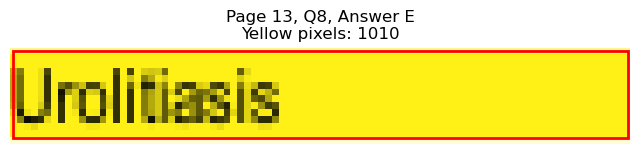


Page 13, Q8 - Selected Answer: E (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,Lactante de 4 meses que inició alimentación co...
1,"Niño de 3 años, traído al Centro de Salud, por..."
2,Lactante varón de 8 meses con poca ganancia po...
3,¿Qué examen confirma el diagnóstico de la disp...
4,"Varón de 5 meses, traído a emergencia por difi..."
...,...
95,Madre gestante a término en inicio de trabajo ...
96,"Niño de 8 años, presenta fiebre, dolor de cabe..."
97,Neonato de una semana de edad que recibe lacta...
98,"Niño de 10 años, conducido a Centro de Salud p..."


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Hierro,Magnesio,Zinc,Calcio,Cobre
1,Neuroblastoma,Linfoma no Hodgkin,Rabdomiosarcoma,Hepatoblastoma,Tumor de Wilms
2,Otitis media,Infección urinaria,Apendicitis,Neumonía,Urolitiasis
3,El signo de Ortolani-Barlow,La asimetría de los pliegues,Signo de Galeazzi,Asimetría en longitud de miembros,Radiografía o ecografía
4,Bronquiolitis aguda,Laringotraqueitis,Tos ferina,Reflujo gastroesofágico,Insuficiencia cardíaca
...,...,...,...,...,...
95,No lactancia materna,Separación inmediata del niño,Cesárea,Uso de mascarilla adecuada permanente,Clampaje inmediato del cordón
96,Resfrío común,Rinitis alérgica,Sinusitis,Cuerpo extraño,Rinitis vasomotora
97,"Sí, porque así evita que el niño se deshidrate","No, porque hay riesgo que el agua esté contami...","Sí, para disminuir la densidad calórica de la ...",Es controversial ofertar agua adicional al neo...,"No, porque la leche materna tiene suficiente agua"
98,Diabetes tipo II,Hemocromatosis,Pheocromocitoma,Diabetes tipo I,Síndrome de Cushing


In [9]:
correct_answers_df

,correct_answer
0,C
1,E
2,B
3,E
4,A
...,...
95,D
96,C
97,E
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,Lactante de 4 meses que inició alimentación co...,Hierro,Magnesio,Zinc,Calcio,Cobre,C
1,"Niño de 3 años, traído al Centro de Salud, por...",Neuroblastoma,Linfoma no Hodgkin,Rabdomiosarcoma,Hepatoblastoma,Tumor de Wilms,E
2,Lactante varón de 8 meses con poca ganancia po...,Otitis media,Infección urinaria,Apendicitis,Neumonía,Urolitiasis,B
3,¿Qué examen confirma el diagnóstico de la disp...,El signo de Ortolani-Barlow,La asimetría de los pliegues,Signo de Galeazzi,Asimetría en longitud de miembros,Radiografía o ecografía,E
4,"Varón de 5 meses, traído a emergencia por difi...",Bronquiolitis aguda,Laringotraqueitis,Tos ferina,Reflujo gastroesofágico,Insuficiencia cardíaca,A
...,...,...,...,...,...,...,...
95,Madre gestante a término en inicio de trabajo ...,No lactancia materna,Separación inmediata del niño,Cesárea,Uso de mascarilla adecuada permanente,Clampaje inmediato del cordón,D
96,"Niño de 8 años, presenta fiebre, dolor de cabe...",Resfrío común,Rinitis alérgica,Sinusitis,Cuerpo extraño,Rinitis vasomotora,C
97,Neonato de una semana de edad que recibe lacta...,"Sí, porque así evita que el niño se deshidrate","No, porque hay riesgo que el agua esté contami...","Sí, para disminuir la densidad calórica de la ...",Es controversial ofertar agua adicional al neo...,"No, porque la leche materna tiene suficiente agua",E
98,"Niño de 10 años, conducido a Centro de Salud p...",Diabetes tipo II,Hemocromatosis,Pheocromocitoma,Diabetes tipo I,Síndrome de Cushing,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Pediatría.csv
